# 0. 분석 준비
- 2024년 말 기준 365일 구매 이력으로 R·F·M을 산출하고, 5분위 스코어링의 한계를 확인한 뒤 R·F 고정 구간 스코어링과 세그먼트 규칙을 정의합니다.
- 세그먼트 간 R·F·M 차이를 Kruskal-Wallis·Dunn, Welch ANOVA·Games-Howell로 검증합니다.
- 마지막에 2022-01~2024-12 월말 RFM 스냅샷을 만들어 `data/snapshots_df.parquet`로 저장합니다 (04·05 노트북의 입력).

## 0.1. 라이브러리

In [ ]:
# %pip install squarify
# %pip install pingouin
# %pip install scikit_posthocs

In [ ]:
import pandas as pd
import numpy as np

import os
import urllib.request
import warnings

import math
import scipy.stats as stats
from statsmodels.stats.multicomp
import pingouin as pg
import pairwise_tukeyhsd
import scikit_posthocs as sp
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import matplotlib.ticker as ticker
import matplotlib.font_manager as fm
import seaborn as sns
import koreanize_matplotlib
import squarify # 트리맵 구현을 위한 라이브러리

from sqlalchemy import create_engine, text, inspect

## 0.2. 차트 공통 규칙 정의

In [ ]:
# =====================================================================================
# [CHART THEME v2] 보고서 게재 차트 공통 규칙  — Layer 1(공통) + Layer 2(유형별)
# =====================================================================================
# 이 셀은 '규칙'만 정의한다. "무엇을 강조할 것인가"(Layer 3)는 각 차트 셀이 스스로 정한다.
#
# [v2 변경점]
#   (1) 범례 규칙 통일 — 예외 없이 '축 바깥 우상단'. legend_loc 인자를 없앴다.
#       바깥 범례는 플롯 폭을 잠식하므로 fig_size() 가 LEGEND_W 만큼 캔버스를 넓힌다.
#   (2) 범례 순서 — sort_legend(on/off) 를 없애고 legend_order(명시 리스트)로 일원화.
#       세그먼트면 SEGMENT_ORDER, 아니면 해당 차트가 순서를 명시한다. '정렬 안 함'은 없다.
#   (3) 제목-부제 간격 — 부제를 축 좌표(1.012)가 아니라 offset points 로 띄운다.
#       축 높이가 2.6인치든 8인치든 간격이 같아진다. 제목 pad 도 20 → 32.
#   (4) 범례 handles/labels 를 직접 넘길 수 있게 함(범례용 더미 핸들을 쓰는 차트 대응).
# =====================================================================================

# ---------- C1 한글 폰트 (셀 1의 koreanize_matplotlib 로 이미 적용됨) -------------------
plt.rcParams["axes.unicode_minus"] = False

# ---------- C2 폰트 크기 위계 ----------------------------------------------------------
FS_TITLE, FS_SUB, FS_AXIS, FS_TICK, FS_LABEL = 16, 10.5, 12, 10, 9
FS_PANEL = 14                      # 다중 패널의 개별 패널 제목

# ---------- C2b 제목 · 부제 간격 --------------------------------------------------------
TITLE_PAD      = 14                # 부제가 없을 때
TITLE_PAD_SUB  = 32                # 부제가 있을 때 (부제가 들어갈 자리를 비운다)
SUB_OFFSET_PT  = 8                 # 축 상단에서 부제까지 (pt 고정 → 축 높이와 무관)

# ---------- C3 캔버스 폭 ----------------------------------------------------------------
FIG_W        = 14.0                # 1패널 '플롯 영역' 폭
FIG_W_2PANE  = 16.0                # 2패널 '플롯 영역' 합계 폭
LEGEND_W     = 2.6                 # 바깥 범례에 할당하는 폭

def fig_size(height, plot_w=None, legends=1):
    """플롯 영역 폭 + 범례 폭. 범례를 바깥에 두면 플롯이 좁아지므로 그만큼 캔버스를 넓힌다.
       legends=0 이면 범례가 없는 차트."""
    return ((FIG_W if plot_w is None else plot_w) + LEGEND_W * legends, height)

# ---------- C4 세그먼트 색상 고정 매핑 (Set3) -------------------------------------------
_SEG_ABC    = ["At_Risk", "Dormant", "Low_Value", "Loyal", "Potential", "Regular", "VIP"]
PALETTE_SEG = dict(zip(_SEG_ABC, sns.color_palette("Set3", n_colors=7)))
PALETTE_SEG["Dormant"] = "darkgray"
palette_dict = PALETTE_SEG          # 기존 셀들이 쓰는 이름을 같은 객체로 묶어 이원화를 방지

# ---------- C5 세그먼트 순서(범례·정렬) 고정 -------------------------------------------
SEGMENT_ORDER  = ["VIP", "Loyal", "At_Risk", "Regular", "Potential", "Low_Value", "Dormant"]
TIER_PRIMARY   = ["VIP", "Loyal", "At_Risk"]
TIER_SECONDARY = ["Regular", "Potential", "Low_Value"]

# ---------- C11 텍스트 위계 : alpha 가 아니라 잉크 색으로 ------------------------------
INK_PRIMARY   = "#1A1A1A"   # 대비 약 16.5:1
INK_SECONDARY = "#5A5A5A"   # 대비 약  6.9:1 (WCAG AA 통과)
INK_MUTED     = "#8A897F"   # 보조선 · 부제
LABEL_BBOX    = dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85)

# ---------- 비(非)세그먼트 범주용 Okabe-Ito --------------------------------------------
CAT_PALETTE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]

# =====================================================================================
# Layer 2 — 차트 유형별 스타일
# =====================================================================================
def line_style(seg, primary=None, secondary=None):
    """선: 위계는 alpha + linewidth 로."""
    p = TIER_PRIMARY   if primary   is None else primary
    s = TIER_SECONDARY if secondary is None else secondary
    if seg in p:
        return dict(alpha=1.00, linewidth=3.0, zorder=5, markersize=5)
    if seg in s:
        return dict(alpha=0.55, linewidth=1.8, zorder=3, markersize=3)
    return dict(alpha=0.45, linewidth=1.5, zorder=2, markersize=3)

def bar_style(is_primary=True):
    """막대: 면적이 넓어 alpha 를 쓰면 색이 혼합되므로 edgecolor 로 분리."""
    return dict(alpha=1.00 if is_primary else 0.65,
                edgecolor="white", linewidth=2.0, zorder=3)

def ink(is_primary=True):
    return INK_PRIMARY if is_primary else INK_SECONDARY

# =====================================================================================
# finalize() — C2·C5~C10 일괄 적용. 모든 차트의 마지막에 호출한다.
# =====================================================================================
def finalize(ax, title=None, xlabel=None, ylabel=None, *,
             subtitle=None, panel=False,
             legend=True, legend_title="세그먼트", legend_order=None, legend_ncol=1,
             handles=None, labels=None,
             grid_axis="y", unit_fmt=None, xtick_rotation=None, layout=True):
    # ---- 제목 · 부제 (C2b) -------------------------------------------------------------
    if title is not None:
        ax.set_title(title, fontsize=FS_PANEL if panel else FS_TITLE, fontweight="bold",
                     pad=TITLE_PAD_SUB if subtitle else TITLE_PAD)
    if subtitle:
        ax.annotate(subtitle, xy=(0.5, 1.0), xycoords="axes fraction",
                    xytext=(0, SUB_OFFSET_PT), textcoords="offset points",
                    ha="center", va="bottom", fontsize=FS_SUB, color=INK_MUTED,
                    annotation_clip=False)

    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=FS_AXIS)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=FS_AXIS)
    ax.tick_params(labelsize=FS_TICK)
    if xtick_rotation is not None:
        ax.tick_params(axis="x", rotation=xtick_rotation)

    # ---- C10 축 눈금 단위 = 데이터 라벨 단위 -------------------------------------------
    if unit_fmt:
        ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: unit_fmt.format(v)))

    # ---- C7 격자 (가로 막대는 "x", 격자가 무의미하면 None) ------------------------------
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle="--", alpha=0.4)
        ax.set_axisbelow(True)

    # ---- C6 spine ----------------------------------------------------------------------
    for s in ["top", "right"] + (["left"] if grid_axis == "x" else []):
        ax.spines[s].set_visible(False)

    # ---- C8 범례 : 예외 없이 '축 바깥 우상단', 순서는 명시 리스트로 --------------------
    if legend:
        h, l = (handles, labels) if handles is not None else ax.get_legend_handles_labels()
        if h:
            order = legend_order if legend_order is not None else SEGMENT_ORDER
            idx = sorted(range(len(l)),
                         key=lambda i: order.index(l[i]) if l[i] in order else 999 + i)
            ax.legend([h[i] for i in idx], [l[i] for i in idx], title=legend_title,
                      bbox_to_anchor=(1.02, 1.0), loc="upper left",
                      fontsize=FS_SUB, title_fontsize=FS_SUB, frameon=False, ncol=legend_ncol)
    if layout:
        plt.tight_layout()

print("[CHART THEME v2] 로드 — FIG_W=%.0f  LEGEND_W=%.1f  세그먼트 순서: %s"
      % (FIG_W, LEGEND_W, " > ".join(SEGMENT_ORDER[:4]) + " ..."))

# [화면용 선택 프로필] 좁은 보고서 본문에서 1개 이미지당 1개 차트 사용.
# 기존 기본값은 유지한다. 범례는 이 프로필에서만 상단 가로 배치를 허용한다.
SCREEN_FIG_W = 9.0
SCREEN_FS_LABEL = 12
SCREEN_FS_TICK = 12
SCREEN_FS_AXIS = 13

def finalize_screen(ax, title, xlabel=None, ylabel=None, grid_axis='y'):
    finalize(ax,title,xlabel,ylabel,legend=False,grid_axis=grid_axis,layout=False)
    ax.tick_params(labelsize=SCREEN_FS_TICK)
    ax.xaxis.label.set_size(SCREEN_FS_AXIS)
    ax.yaxis.label.set_size(SCREEN_FS_AXIS)
    ax.title.set_fontsize(FS_TITLE)


[CHART THEME v2] 로드 — FIG_W=14  LEGEND_W=2.6  세그먼트 순서: VIP > Loyal > At_Risk > Regular ...


In [395]:
def setup_korean_font():
    font_url = 'https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf'
    font_path = 'NanumGothic.ttf'
    if not os.path.exists(font_path):
        urllib.request.urlretrieve(font_url, font_path)
    
    fe = fm.FontEntry(fname=font_path, name='NanumGothic')
    fm.fontManager.ttflist.insert(0, fe)
    plt.rcParams.update({'font.size': 12, 'font.family': 'NanumGothic', 'axes.unicode_minus': False})
    return 'NanumGothic'

font_name = setup_korean_font()

In [335]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 500)

warnings.filterwarnings('ignore')

## 0.3. 데이터 로드

In [336]:
# Data 리스트 불러오기
data_path = os.path.join(os.getcwd(), '..', 'data')
data_files = os.listdir(data_path)

# DB Table에 적재하지 않는 파일을 리스트에서 제거
table_order = ['users', 'products', 'promotions', 'events', 'orders', 'order_items']  # 'users', 'products', 'promotions', 'events', 'orders', 'order_items'
data_files = [(file.split('.')[0], file.split('.')[1]) for file in data_files if file.split('.')[0] in table_order]

print(data_files)

[('products', 'csv'), ('orders', 'csv'), ('users', 'csv'), ('events', 'parquet'), ('promotions', 'csv'), ('order_items', 'csv')]


In [337]:
# 테이블별 날짜 컬럼 정의
date_cols = {
    "users": ["created_at", "birth"],
    "products": [],
    "promotions": ["start_date", "end_date"],
    "events": ["created_at"],
    "orders": ["created_at", "withdrawn_at", "returned_at", "shipped_at", "delivered_at"],
    "order_items": ["created_at", "withdrawn_at", "shipped_at", "delivered_at", "returned_at"],
}

if "df_dict" in globals():
    print("========== df_dict already exists ==========")
    for file_name, ext in data_files:
        if ext == 'csv':
            df_dict[file_name] = pd.read_csv(os.path.join(data_path, f"{file_name}.{ext}"), parse_dates=date_cols.get(file_name, []))
        elif ext == 'parquet':
            df_dict[file_name] = pd.read_parquet(os.path.join(data_path, f"{file_name}.{ext}"), engine='pyarrow')
        print(f"✅ {file_name} loaded")
else:
    print("========== df_dict does not exist ==========")
    # DataFrame 딕셔너리 생성
    df_dict = {}
    for file_name, ext in data_files:
        if ext == 'csv':
            df_dict[file_name] = pd.read_csv(
                os.path.join(data_path, f"{file_name}.{ext}"),
                parse_dates=date_cols.get(file_name, [])
            )
        elif ext == 'parquet':
            df_dict[file_name] = pd.read_parquet(
                os.path.join(data_path, f"{file_name}.{ext}"),
                engine='pyarrow'
            )
        print(f"✅ {file_name} loaded")

# 로드 확인
for name, df in df_dict.items():
    print(f"{name}: {df.shape}")

========== df_dict does not exist ==========
✅ products loaded


✅ orders loaded
✅ users loaded
✅ events loaded
✅ promotions loaded
✅ order_items loaded
products: (30000, 8)
orders: (280340, 10)
users: (103648, 11)
events: (15366289, 12)
promotions: (15, 8)
order_items: (548660, 17)


In [338]:
events_df = df_dict['events']
orders_df = df_dict['orders']
order_items_df = df_dict['order_items']
users_df = df_dict['users']
products_df = df_dict['products']
promotions_df = df_dict['promotions']

del df_dict

# 1. RFM 세그먼트 기준 설정 및 검증

**[정의]**</br>
구매 기반 RFM 분석이란 `“고객의 실제 매출 기여 행동만을 기준으로, 고객 가치를 구조적으로 분해해 이해하는 방법”`

**[목표]**</br>
`“지금 우리 매출을 떠받치고 있는 고객은 누구인가?”`

**[구매 기반 RFM의 3요소]**
- Recency (R): 마지막 구매 시점 기준 최근성
- Frequency (F): 일정 기간 내 구매 횟수
- Monetary (M): 일정 기간 내 구매 금액

→ 즉, `“얼마나 최근에, 얼마나 자주, 얼마나 많이 돈을 썼는가”`만으로 고객을 평가

## 1.1. 세그먼트 분할

**[RFM 정의]**

- R : 마지막 구매일 기준(일 단위)
- F : 최근 12개월 주문 횟수
- M : 최근 12개월 실결제 금액(할인 반영 후)

**[스코어링 방식]**
- 각 지표 5분위(quantile)
- R은 낮을수록 고점, F/M은 높을수록 고점

**[세그먼트 구조(초기 설정)]**
- VIP : 지금 매출의 핵심
- 충성 고객 : 안정적 매출원
- 신규 활성 : 미래 성장 후보
- 이탈 위험 : 방치 시 매출 감소 위험
- 저가, 저빈도 : ROI 낮음
- 휴면 : 분석 대상에서 제외 가능

### 1.1.1. 데이터 준비

In [348]:
def build_order_level_amounts(orders_df: pd.DataFrame, order_items_df: pd.DataFrame) -> pd.DataFrame:
    """
    주문 단위 금액(order_amount) 생성:
      order_amount = Σ(sale_price) by order_id
    """
    o = orders_df.copy()
    oi = order_items_df.copy()

    # datetime 캐스팅
    o["created_at"] = pd.to_datetime(o["created_at"], errors="coerce")
    

    # 숫자 캐스팅
    oi["sale_price"] = pd.to_numeric(oi["sale_price"], errors="coerce").fillna(0.0)
    oi["num_of_items"] = pd.to_numeric(oi["num_of_items"], errors="coerce").fillna(0).astype(int)

    # order_id 기준 집계
    order_amounts = (
        oi[oi['status'].isin(['Purchased', 'Shipped', 'Packing'])].groupby("order_id", as_index=False)
          .agg(
              order_amount=("sale_price", "sum"),           # 주문 총 금액
              item_rows=("id", "count"),                    # 주문 상품 수
              distinct_products=("product_id", "nunique"),  # 주문 상품 종류 수
              qty_sum=("num_of_items", "sum"),              # 주문 상품 총 개수
          )
    )

    # orders에 붙이기 (orders.id == order_items.order_id)
    out = o.merge(order_amounts, left_on="id", right_on="order_id", how="left")
    out = out.dropna(subset=['order_amount', 'item_rows', 'distinct_products', 'qty_sum'])

    # 조인 후 생긴 중복키 정리
    out = out.drop(columns=["order_id"])

    return out
    

In [349]:
orders_enriched = build_order_level_amounts(orders_df, order_items_df)
orders_enriched.head()

,id,user_id,status,gender,created_at,withdrawn_at,shipped_at,delivered_at,returned_at,num_of_items,order_amount,item_rows,distinct_products,qty_sum
0,or-00007c1b304e,70131,Completed,M,2024-12-07 10:01:11,NaT,2024-12-07 23:34:08,2024-12-09 09:31:19,NaT,1,10440.0,1.0,1.0,1.0
1,or-00009bda2202,19543,Processing,M,2024-12-31 15:58:27,NaT,NaT,NaT,NaT,1,41400.0,1.0,1.0,1.0
2,or-0000a689fc6b,41124,Completed,M,2023-07-03 07:10:52,NaT,2023-07-04 00:36:33,2023-07-06 11:17:03,NaT,5,234000.0,2.0,2.0,5.0
3,or-0000c4021e62,36445,Completed,F,2024-01-25 08:45:03,NaT,2024-01-26 02:48:58,2024-01-28 22:58:46,NaT,6,442980.0,4.0,4.0,6.0
4,or-0000c830f7b3,67269,Completed,M,2023-01-30 16:51:49,NaT,2023-01-31 05:31:15,2023-02-03 01:22:45,NaT,4,137290.0,3.0,3.0,4.0


### 1.1.2. RFM 스코어 기반 세그먼트 분할

In [350]:
# Purchase-based RFM 계산
def compute_rfm_purchase(
    users_df: pd.DataFrame,
    orders_enriched_df: pd.DataFrame,
    as_of_date: str = "2024-12-31",
    lookback_days: int = 365,
    statuses: set | None = None,
) -> pd.DataFrame:
    """
    구매 기반 RFM:
      - 분석 기준일(as_of_date) 기준 최근 lookback_days(기본 365일) 주문만 사용
      - R: 기준일 - 마지막 구매일 (일)
      - F: 기간 내 주문수
      - M: 기간 내 총 구매금액(주문금액 합)
    """
    as_of = pd.to_datetime(as_of_date).normalize().replace(hour=23, minute=59, second=59)   # 분석 기준일 예) 2022-01-31 23:59:59
    start = (as_of - pd.Timedelta(days=lookback_days-1)).normalize()                        # lookback 시작일 예) 2021-02-01 00:00:00

    o = orders_enriched_df.copy()
    o["created_at"] = pd.to_datetime(o["created_at"], errors="coerce")

    # 결제 완료 필터(orders.status가 존재하므로 보수적으로 적용)
    # 시뮬레이션 데이터의 status 값이 다를 수 있어, 모르면 아래 리스트만 수정하면 됩니다.
    if statuses is None:
        statuses = {"Completed", "Processing"}  # Cancelled 제외

    if "status" in o.columns:
        o = o[o["status"].isin(statuses)]

    # 기간 필터
    o = o[(o["created_at"] >= start) & (o["created_at"] <= as_of)]

    # user_id 결측 제거
    o = o.dropna(subset=["user_id", "created_at"])

    # 고객 단위 집계
    rfm = (
        o.groupby("user_id", as_index=False)
         .agg(
             last_order_dt=("created_at", "max"),
             frequency=("id", "nunique"),
             monetary=("order_amount", "sum"),
         )
    )

    # recency(days)
    rfm["recency_days"] = (as_of - rfm["last_order_dt"].dt.normalize()).dt.days

    # 구매 없는 유저까지 포함(Left join)
    base = users_df[users_df['created_at'] <= as_of]
    base = base[["id", "created_at", "age", "gender", "traffic_source"]].drop_duplicates().rename(columns={"id": "user_id"})
    rfm_full = base.merge(rfm, on="user_id", how="left")

    rfm_full["frequency"] = rfm_full["frequency"].fillna(0).astype(int)
    rfm_full["monetary"] = rfm_full["monetary"].fillna(0.0)

    # 구매 이력 없는 고객은 recency를 큰 값으로 처리(분위수 스코어링에서 최하위로 밀리게 함)
    rfm_full["recency_days"] = rfm_full["recency_days"].fillna(lookback_days + 999).astype(int)

    # 가입 후 경과일(days_since_signup)
    rfm_full["days_since_signup"] = (pd.to_datetime(as_of_date).normalize() - rfm_full["created_at"]).dt.days

    # 고객별 평균 객단가(aov_user)
    rfm_full["aov_user"] = np.where(rfm_full["frequency"] > 0, round(rfm_full["monetary"] / rfm_full["frequency"], 2), 0)

    return rfm_full


In [351]:
# 단일 기간 대상 세그먼트 분할

def run_purchase_rfm(
    users_df: pd.DataFrame,
    orders_df: pd.DataFrame,
    order_items_df: pd.DataFrame,
    as_of_date: str = "2024-12-31",  # 분석 기준일
    lookback_days: int = 365,        # 고객 수명 1년을 전제로 반영
) -> pd.DataFrame:
    """
    외부에서 이미 로드된 DataFrame을 받아 구매 기반 RFM 산출.
    """
    orders_enriched = build_order_level_amounts(orders_df, order_items_df)
    rfm_df = compute_rfm_purchase(
        users_df=users_df,
        orders_enriched_df=orders_enriched,
        as_of_date=as_of_date,
        lookback_days=lookback_days,
    )

    # 간단 검증 출력
    print("=== Purchase RFM ===")
    print(f"as_of_date={as_of_date} | lookback_days={lookback_days}")
    as_of = pd.to_datetime(as_of_date).normalize()
    print("users:", users_df.loc[users_df['created_at'] <= as_of, "id"].nunique(), "| rfm_rows:", len(rfm_df))
    display(rfm_df.head())

    return rfm_df
    

In [352]:
as_of_date="2024-12-31"
lookback_days=365

rfm_2024_df = run_purchase_rfm(users_df, orders_df, order_items_df, as_of_date=as_of_date, lookback_days=lookback_days)

=== Purchase RFM ===
as_of_date=2024-12-31 | lookback_days=365
users: 103613 | rfm_rows: 103648


,user_id,created_at,age,gender,traffic_source,last_order_dt,frequency,monetary,recency_days,days_since_signup,aov_user
0,1,2023-09-20 03:01:49,23,M,direct,2024-02-08 00:28:36,2,258250.0,327,467,129125.00
1,2,2023-11-01 17:43:31,20,F,email,2024-05-22 01:31:56,10,1817400.0,223,425,181740.00
2,3,2023-11-09 05:37:17,27,F,direct,NaT,0,0.0,1364,417,0.00
3,4,2024-09-07 16:42:36,25,M,organic_search,NaT,0,0.0,1364,114,0.00
4,5,2023-12-23 19:45:29,24,M,direct,2024-09-12 17:47:49,11,1691780.0,110,373,153798.18


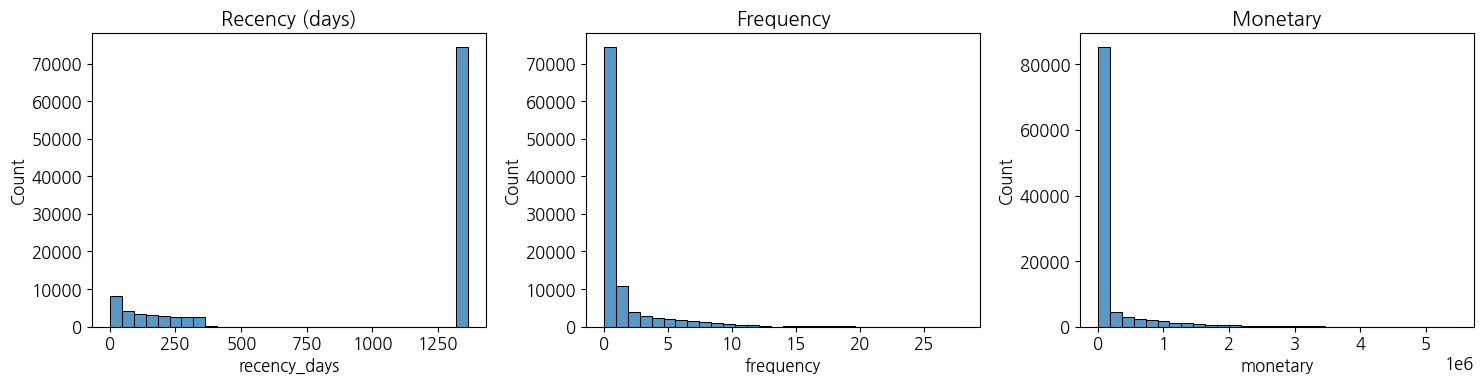

In [353]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(rfm_2024_df["recency_days"], bins=30, kde=False, ax=axes[0])
axes[0].set_title("Recency (days)")

sns.histplot(rfm_2024_df["frequency"], bins=30, kde=False, ax=axes[1])
axes[1].set_title("Frequency")

sns.histplot(rfm_2024_df["monetary"], bins=30, kde=False, ax=axes[2])
axes[2].set_title("Monetary")

plt.tight_layout()
plt.show()

- **Frequency / Monetary의 값이 낮은 값에 집중되어 있음 확인**

In [354]:
# RFM 초기 설정
def rfm_quintile_scoring(rfm_df, lookback_days: int = 365):
    """
    입력 rfm_df 필수 컬럼:
      - recency_days (int)
      - frequency (int)
      - monetary (float)
    출력:
      - R_score, F_score, M_score (1~5, 높을수록 우수)
      - RFM_score (문자열: 예 '545')
      - RFM_sum (정수 합계)
    """    
    out = rfm_df.copy()

    # 미구매 마스크: recency_days > lookback_days or frequency=0 or monetary=0
    non_buyer_mask = (
        (out["recency_days"] > lookback_days)  # 최근 구매일이 분석 기간 초과
        | (out["frequency"] == 0)              # 구매 횟수 0회
        | (out["monetary"] == 0)               # 구매 금액 0원
    )

    # 미구매는 0점으로 기본값 부여
    out["R_score"] = 0
    out["F_score"] = 0
    out["M_score"] = 0

    # 구매자만 분위수 스코어링
    buyers = out.loc[~non_buyer_mask].copy()

    # Recency: 작을수록 좋음 → 역정렬
    r_cut = pd.qcut(
        buyers["recency_days"],
        q=5,
        duplicates="drop")
    n_bins_r = len(r_cut.cat.categories)
    buyers["R_score"] = (n_bins_r - 1) - r_cut.cat.codes.astype(int) + 1

    # F, M: 클수록 좋음
    f_cut = pd.qcut(
        buyers["frequency"],
        q=5,
        duplicates="drop")
    n_bins_f = len(f_cut.cat.categories)
    buyers["F_score"] = f_cut.cat.codes.astype(int) + 1

    m_cut = pd.qcut(
        buyers["monetary"],
        q=5,
        duplicates="drop")
    n_bins_m = len(m_cut.cat.categories)
    buyers["M_score"] = m_cut.cat.codes.astype(int) + 1

    out.loc[buyers.index, ["R_score", "F_score", "M_score"]] = buyers[["R_score", "F_score", "M_score"]]

    # --- 합성 점수
    out["RFM_score"] = (
        out["R_score"].astype(str)
        + out["F_score"].astype(str)
        + out["M_score"].astype(str)
    )
    out["RFM_sum"] = out[["R_score", "F_score", "M_score"]].sum(axis=1)

    return out
    

In [355]:
lookback_days = 365
rfm_2024_scored = rfm_quintile_scoring(rfm_2024_df, lookback_days = lookback_days)
rfm_2024_scored.head()

,user_id,created_at,age,gender,traffic_source,last_order_dt,frequency,monetary,recency_days,days_since_signup,aov_user,R_score,F_score,M_score,RFM_score,RFM_sum
0,1,2023-09-20 03:01:49,23,M,direct,2024-02-08 00:28:36,2,258250.0,327,467,129125.00,1,1,3,113,5
1,2,2023-11-01 17:43:31,20,F,email,2024-05-22 01:31:56,10,1817400.0,223,425,181740.00,2,4,5,245,11
2,3,2023-11-09 05:37:17,27,F,direct,NaT,0,0.0,1364,417,0.00,0,0,0,000,0
3,4,2024-09-07 16:42:36,25,M,organic_search,NaT,0,0.0,1364,114,0.00,0,0,0,000,0
4,5,2023-12-23 19:45:29,24,M,direct,2024-09-12 17:47:49,11,1691780.0,110,373,153798.18,3,4,5,345,12


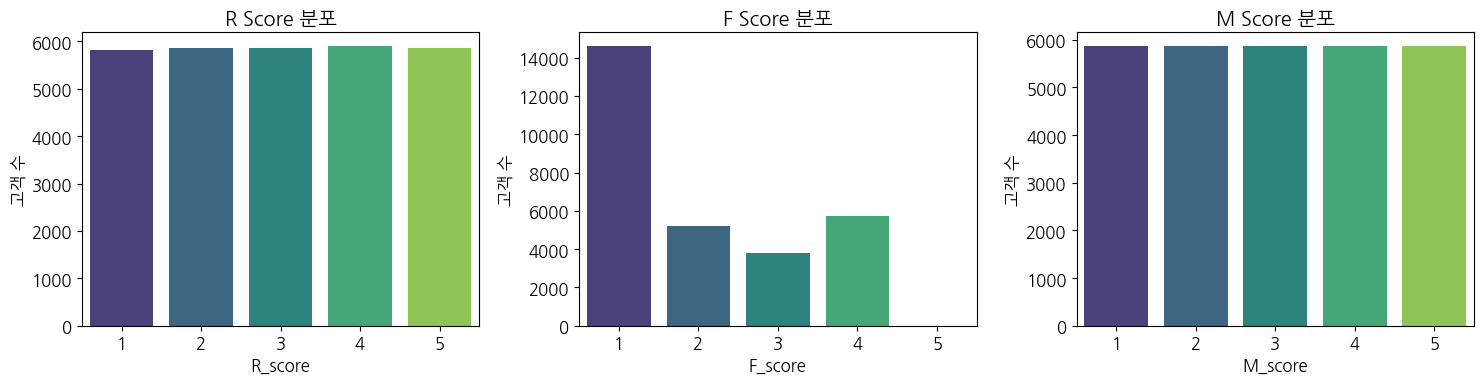

In [356]:
score_cols = ["R_score", "F_score", "M_score"]
titles = ["R Score 분포", "F Score 분포", "M Score 분포"]
# 0점 제외: 구매자(또는 세 점수 모두 부여된 고객)만
mask = (rfm_2024_scored["RFM_sum"] > 0)
rfm_buyers = rfm_2024_scored.loc[mask]

score_cols = ["R_score", "F_score", "M_score"]
titles = ["R Score 분포", "F Score 분포", "M Score 분포"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, title in zip(axes, score_cols, titles):
    order = list(range(1, 6))
    sns.countplot(data=rfm_buyers, x=col, order=order, ax=ax, palette="viridis")
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel("고객 수")

plt.tight_layout()
plt.show()

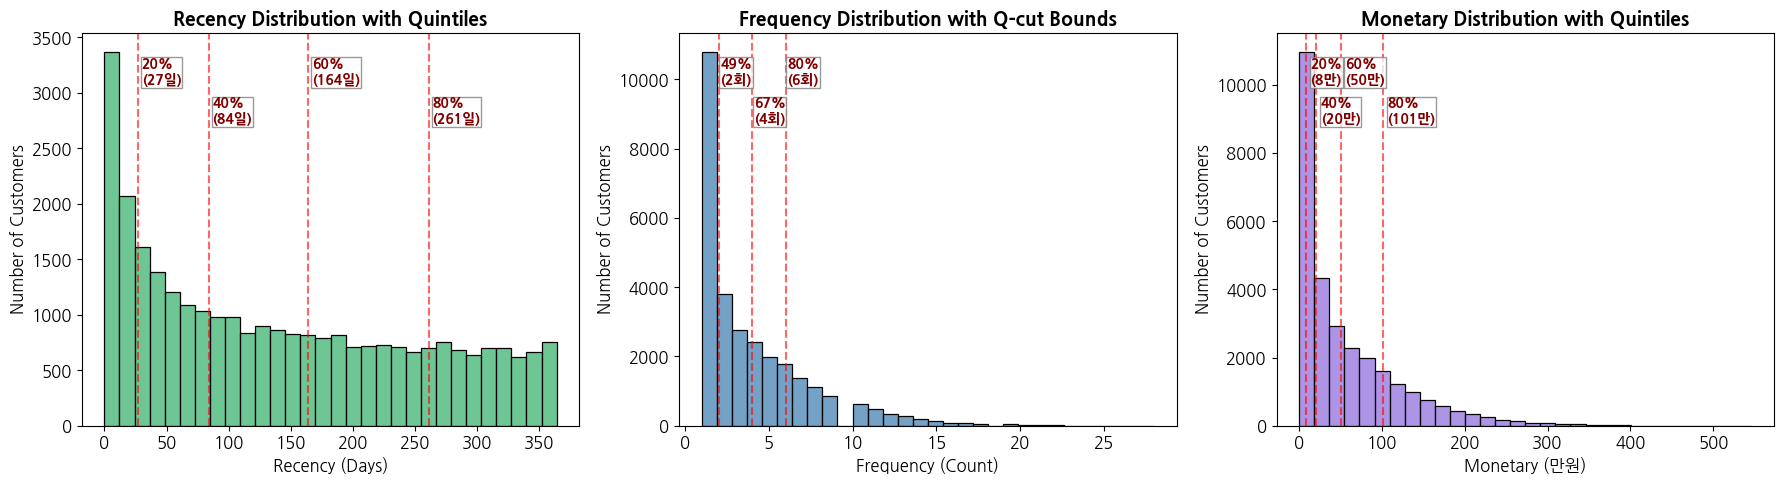

In [357]:
# 서브플롯 설정 (1행 3열)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# =========================================================
# 1. Recency 히스토그램 그리기
# =========================================================
sns.histplot(rfm_buyers["recency_days"], bins=30, kde=False, ax=axes[0], color="mediumseagreen")
axes[0].set_title("Recency Distribution with Quintiles", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Recency (Days)", fontsize=12)
axes[0].set_ylabel("Number of Customers", fontsize=12)

quintiles = [0.2, 0.4, 0.6, 0.8]
quantiles_r = rfm_buyers["recency_days"].quantile(quintiles)
unique_quantiles_r = quantiles_r.drop_duplicates()

y_max_r = axes[0].get_ylim()[1]

for i, (q_label, x_val) in enumerate(unique_quantiles_r.items()):
    axes[0].axvline(x=x_val, color='red', linestyle='--', alpha=0.6)
    pct_str = f"{int(q_label * 100)}%"
    y_pos = y_max_r * (0.9 - (i % 2) * 0.1)
    
    axes[0].text(
        x=x_val + 3, 
        y=y_pos, 
        s=f"{pct_str}\n({int(x_val)}일)", 
        color='maroon', 
        ha='left', 
        va='center', 
        fontsize=10,
        fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', pad=0.5)
    )

# =========================================================
# 2. Frequency 히스토그램 그리기 (qcut 병합 반영)
# =========================================================
sns.histplot(rfm_buyers["frequency"], bins=30, kde=False, ax=axes[1], color="steelblue")
axes[1].set_title("Frequency Distribution with Q-cut Bounds", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Frequency (Count)", fontsize=12)
axes[1].set_ylabel("Number of Customers", fontsize=12)

# pd.qcut을 활용하여 우측 경계값 계산 (5분위 기준, 20%~40% 등 중복 구간 병합)
f_cut = pd.qcut(rfm_buyers["frequency"], q=5, duplicates="drop")
right_bounds_f = [interval.right for interval in f_cut.cat.categories][:-1]

y_max_f = axes[1].get_ylim()[1]

for i, x_val in enumerate(right_bounds_f):
    axes[1].axvline(x=x_val, color='red', linestyle='--', alpha=0.6)
    
    # 핵심 수정: 해당 경계값(x_val) 이하인 데이터의 '실제 누적 비율(%)'을 계산
    actual_pct = (rfm_buyers["frequency"] <= x_val).mean() * 100
    
    # Recency, Monetary와 동일한 텍스트 포맷팅 유지
    pct_str = f"{int(actual_pct)}%"
    y_pos = y_max_f * (0.9 - (i % 2) * 0.1)
    
    axes[1].text(
        x=x_val + 0.1, 
        y=y_pos, 
        s=f"{pct_str}\n({int(x_val)}회)", 
        color='maroon', 
        ha='left', 
        va='center', 
        fontsize=10,
        fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', pad=0.5)
    )

# =========================================================
# 3. Monetary 히스토그램 그리기
# =========================================================
sns.histplot(rfm_buyers["monetary"], bins=30, kde=False, ax=axes[2], color="mediumpurple")
axes[2].set_title("Monetary Distribution with Quintiles", fontsize=14, fontweight="bold")
axes[2].set_xlabel("Monetary (만원)", fontsize=12)
axes[2].set_ylabel("Number of Customers", fontsize=12)

axes[2].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x/10000:,.0f}"))

quantiles_m = rfm_buyers["monetary"].quantile(quintiles)
unique_quantiles_m = quantiles_m.drop_duplicates()

y_max_m = axes[2].get_ylim()[1]

for i, (q_label, x_val) in enumerate(unique_quantiles_m.items()):
    axes[2].axvline(x=x_val, color='red', linestyle='--', alpha=0.6)
    
    pct_str = f"{int(q_label * 100)}%"
    y_pos = y_max_m * (0.9 - (i % 2) * 0.1)
    
    manwon_val = int(x_val / 10000)
    
    axes[2].text(
        x=x_val + (rfm_buyers['monetary'].max() * 0.01), 
        y=y_pos, 
        s=f"{pct_str}\n({manwon_val:,}만)", 
        color='maroon', 
        ha='left', 
        va='center', 
        fontsize=10,
        fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', pad=0.5)
    )

plt.tight_layout()
plt.show()

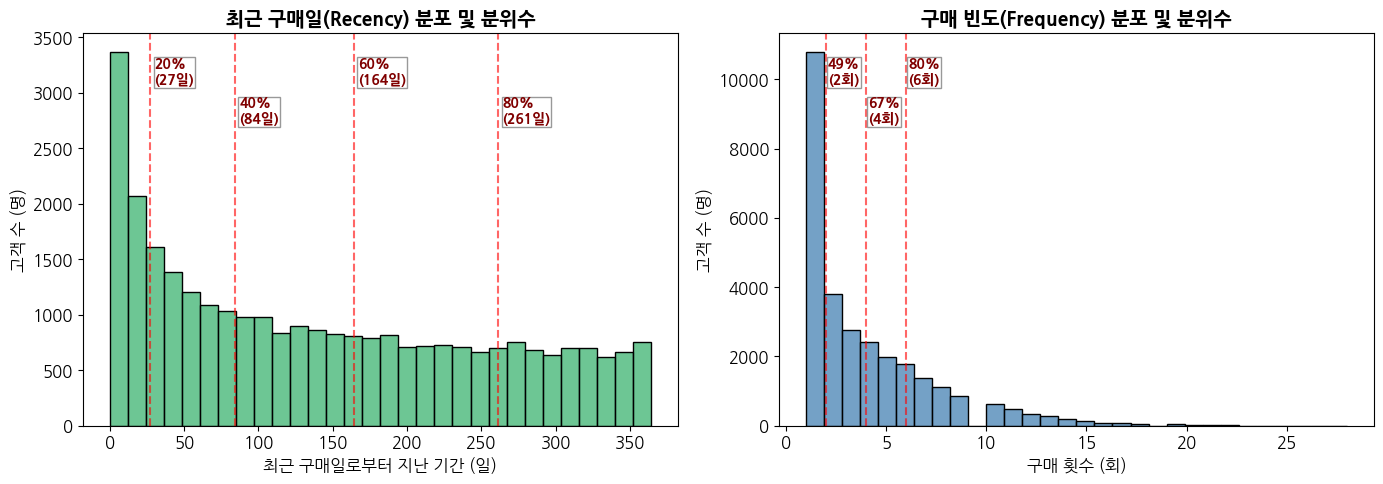

In [358]:
# 서브플롯 설정 (1행 2열)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# =========================================================
# 1. Recency 히스토그램 그리기
# =========================================================
sns.histplot(rfm_buyers["recency_days"], bins=30, kde=False, ax=axes[0], color="mediumseagreen")
axes[0].set_title("최근 구매일(Recency) 분포 및 분위수", fontsize=14, fontweight="bold")
axes[0].set_xlabel("최근 구매일로부터 지난 기간 (일)", fontsize=12)
axes[0].set_ylabel("고객 수 (명)", fontsize=12)

quintiles = [0.2, 0.4, 0.6, 0.8]
quantiles_r = rfm_buyers["recency_days"].quantile(quintiles)
unique_quantiles_r = quantiles_r.drop_duplicates()

y_max_r = axes[0].get_ylim()[1]

for i, (q_label, x_val) in enumerate(unique_quantiles_r.items()):
    axes[0].axvline(x=x_val, color='red', linestyle='--', alpha=0.6)
    pct_str = f"{int(q_label * 100)}%"
    y_pos = y_max_r * (0.9 - (i % 2) * 0.1)
    
    axes[0].text(
        x=x_val + 3, 
        y=y_pos, 
        s=f"{pct_str}\n({int(x_val)}일)", 
        color='maroon', 
        ha='left', 
        va='center', 
        fontsize=10,
        fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', pad=0.5)
    )

# =========================================================
# 2. Frequency 히스토그램 그리기 (qcut 병합 반영)
# =========================================================
sns.histplot(rfm_buyers["frequency"], bins=30, kde=False, ax=axes[1], color="steelblue")
axes[1].set_title("구매 빈도(Frequency) 분포 및 분위수", fontsize=14, fontweight="bold")
axes[1].set_xlabel("구매 횟수 (회)", fontsize=12)
axes[1].set_ylabel("고객 수 (명)", fontsize=12)

# pd.qcut을 활용하여 우측 경계값 계산 (5분위 기준, 20%~40% 등 중복 구간 병합)
f_cut = pd.qcut(rfm_buyers["frequency"], q=5, duplicates="drop")
right_bounds_f = [interval.right for interval in f_cut.cat.categories][:-1]

y_max_f = axes[1].get_ylim()[1]

for i, x_val in enumerate(right_bounds_f):
    axes[1].axvline(x=x_val, color='red', linestyle='--', alpha=0.6)
    
    # 핵심 수정: 해당 경계값(x_val) 이하인 데이터의 '실제 누적 비율(%)'을 계산
    actual_pct = (rfm_buyers["frequency"] <= x_val).mean() * 100
    
    # Recency와 동일한 텍스트 포맷팅 유지
    pct_str = f"{int(actual_pct)}%"
    y_pos = y_max_f * (0.9 - (i % 2) * 0.1)
    
    axes[1].text(
        x=x_val + 0.1, 
        y=y_pos, 
        s=f"{pct_str}\n({int(x_val)}회)", 
        color='maroon', 
        ha='left', 
        va='center', 
        fontsize=10,
        fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', pad=0.5)
    )

plt.tight_layout()
plt.show()

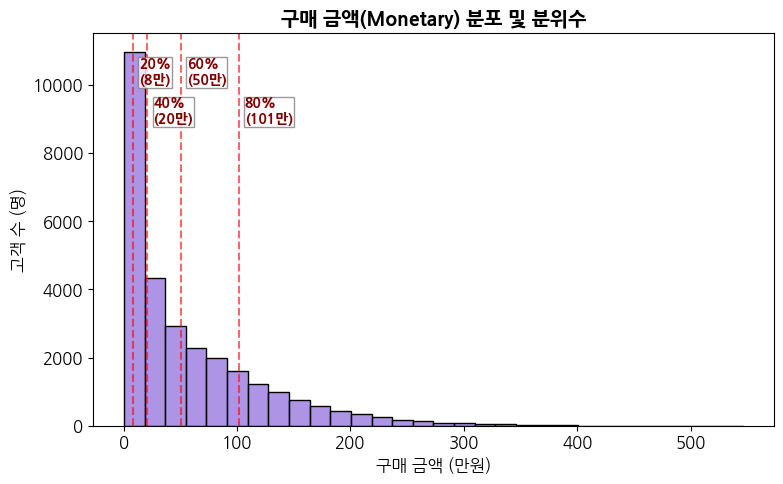

In [359]:
# =========================================================
# Monetary 단독 히스토그램 그리기
# =========================================================
fig, ax = plt.subplots(figsize=(8, 5))

# 히스토그램 그리기
sns.histplot(rfm_buyers["monetary"], bins=30, kde=False, ax=ax, color="mediumpurple")

# 제목 및 축 라벨 (한글화)
ax.set_title("구매 금액(Monetary) 분포 및 분위수", fontsize=14, fontweight="bold")
ax.set_xlabel("구매 금액 (만원)", fontsize=12)
ax.set_ylabel("고객 수 (명)", fontsize=12)

# X축 금액을 만원 단위로 포맷팅
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x/10000:,.0f}"))

# 5분위수 계산 (20%, 40%, 60%, 80%)
quintiles = [0.2, 0.4, 0.6, 0.8]
quantiles_m = rfm_buyers["monetary"].quantile(quintiles)
unique_quantiles_m = quantiles_m.drop_duplicates()

y_max_m = ax.get_ylim()[1]

# 세로선과 분위수 텍스트 추가
for i, (q_label, x_val) in enumerate(unique_quantiles_m.items()):
    ax.axvline(x=x_val, color='red', linestyle='--', alpha=0.6)
    
    pct_str = f"{int(q_label * 100)}%"
    
    # 텍스트가 겹치지 않게 지그재그 배치
    y_pos = y_max_m * (0.9 - (i % 2) * 0.1)
    
    # 만원 단위 환산
    manwon_val = int(x_val / 10000)
    
    ax.text(
        x=x_val + (rfm_buyers['monetary'].max() * 0.01), 
        y=y_pos, 
        s=f"{pct_str}\n({manwon_val:,}만)", 
        color='maroon', 
        ha='left', 
        va='center', 
        fontsize=10,
        fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', pad=0.5)
    )

plt.tight_layout()
plt.show()

### 1.1.3. Scoring 로직 재고

**[문제 정의]**
- Frequency:
    - 5분위수(Quantile) RFM 스코어링을 적용한 결과, 멱함수 분포(소수 빈도에 편중)로 인해 등급 간 경계가 중복되어 5점 그룹이 생성되지 않는 현상 발견.
- Recency:
    - 패션 이커머스의 일반적인 재구매 시기(30-60일)을 초과하여 80일 이상 재구매하지 않은 고객의 비율의 전체의 60%에 달함.

#### 1.1.3.1. Frequency Score 5가 생성되지 않는 원인 파악

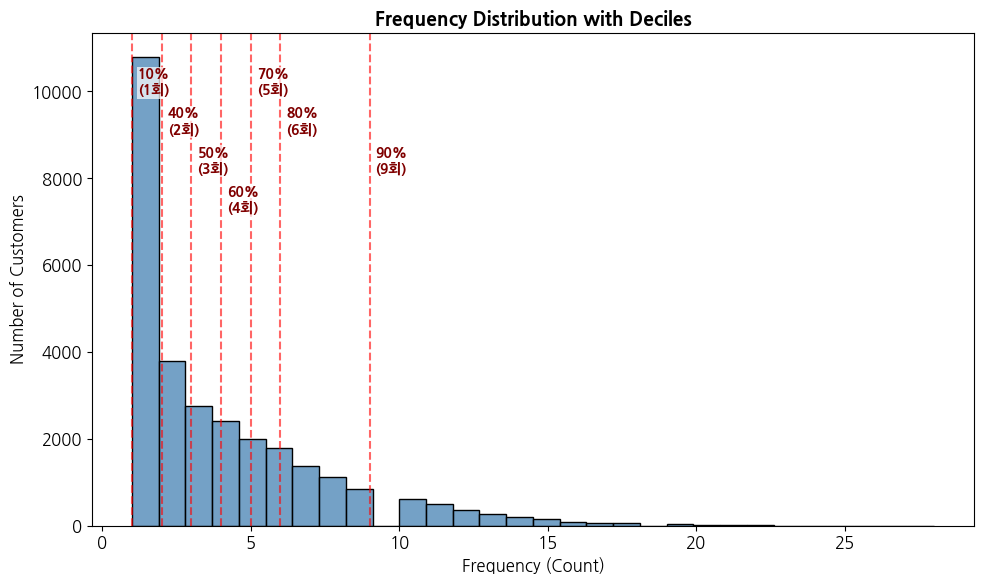

In [360]:
# 단일 차트 설정
fig, ax = plt.subplots(figsize=(10, 6))

# Frequency 히스토그램 그리기
sns.histplot(rfm_buyers["frequency"], bins=30, kde=False, ax=ax, color="steelblue")
ax.set_title("Frequency Distribution with Deciles", fontsize=14, fontweight="bold")
ax.set_xlabel("Frequency (Count)", fontsize=12)
ax.set_ylabel("Number of Customers", fontsize=12)

# 10분위수(10% ~ 90%) 계산
deciles = np.arange(0.1, 1.0, 0.1)
quantiles = rfm_buyers["frequency"].quantile(deciles)

# 이산형 데이터이므로 중복된 분위수 값 제거 (예: 20%, 30%가 동일하게 2회인 경우 하나만 표시)
unique_quantiles = quantiles.drop_duplicates()

# Y축 최대값을 기준으로 텍스트 위치 결정
y_max = ax.get_ylim()[1]

# 세로선과 분위수 텍스트 추가
for i, (q_label, x_val) in enumerate(unique_quantiles.items()):
    # 빨간 점선 추가
    ax.axvline(x=x_val, color='red', linestyle='--', alpha=0.6)
    
    # 퍼센트 텍스트 생성 (예: "10%")
    pct_str = f"{int(q_label * 100)}%"
    
    # 텍스트가 겹치지 않게 Y축 상단에서 지그재그로 배치 (0.9, 0.8, 0.7...)
    y_pos = y_max * (0.9 - (i % 4) * 0.08)
    
    # 텍스트 삽입 (퍼센트와 실제 횟수)
    ax.text(
        x=x_val + 0.2, # 선 바로 오른쪽에 위치
        y=y_pos, 
        s=f"{pct_str}\n({int(x_val)}회)", 
        color='maroon', 
        ha='left', 
        va='center', 
        fontsize=10,
        fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1.0)
    )

plt.tight_layout()
plt.show()

In [361]:
# F, M: 클수록 좋음
f_cut = pd.qcut(
    rfm_buyers["frequency"],
    q=5,
    duplicates="drop")
n_bins_f = len(f_cut.cat.categories)
print(f_cut.cat.categories)

IntervalIndex([(0.999, 2.0], (2.0, 4.0], (4.0, 6.0], (6.0, 28.0]], dtype='interval[float64, right]')


[! Frequency 5분위 시각화 결과에는 구간이 모두 정상 출력되는 이유]

**[시각화]**
- Frequency 데이터는 1회 구매자가 전체의 약 30~40%를 차지.
    - quantile(0.2) (하위 20% 위치의 사람): 1회 구매
    - quantile(0.4) (하위 40% 위치의 사람): 2회 구매
    - quantile(0.6) (하위 60% 위치의 사람): 4회 구매
    - quantile(0.8) (하위 80% 위치의 사람): 6회 구매

quantile은 단순히 "줄 세웠을 때 20% 위치에 있는 사람의 횟수가 1회, 40% 위치에 있는 사람의 횟수가 2회"라고 정확한 숫자를 뱉어냄.

**[pd.qcut]**
- pd.qcut(q=5)은 "전체 데이터를 20%씩 5개의 그룹으로 완벽하게 똑같이 나누는 것"
- pd.qcut이 경계를 잡으려고 시도할 때,
    - 1번 구간 (0~20%): 1회 구매자들을 넣음. 그런데 1회 구매자가 전체의 35%. 1번 구간에 해당되는 frequency=1인 값이 전체의 20%를 넘음.
    - 2번 구간 (20~40%): 2번 구간을 채우려고 보니, 아직 1회 구매자들이 남아있음. 즉, 2번 구간의 끝(40%)에도 1회 구매자, 혹은 이제 막 2회 구매자가 들어가게 됨.
    - 이럴 때, pd.qcut은 같은 frequency(1회)를 가진 데이터들을 1번 구간과 2번 구간으로 갈라놓을 수 없기 때문에, 1번 구간과 2번 구간을 통합하여 [.000, 2.0] 구간이 됨.

#### 1.1.3.2. Frequency 고정 구간 로직 설정
- 등급 간 경계가 중복되어 일부 상위 그룹이 생성되지 않는 현상을 해결하기 위해, 파레토 분석을 통해 '실제 매출을 견인하는 핵심 구매 빈도'를 역산함.
- 이를 바탕으로 Frequency에 한하여 비즈니스 의미를 담은 절대적 '고정 구간(Rule-based)' 방식으로 스코어링 체계를 개선함.

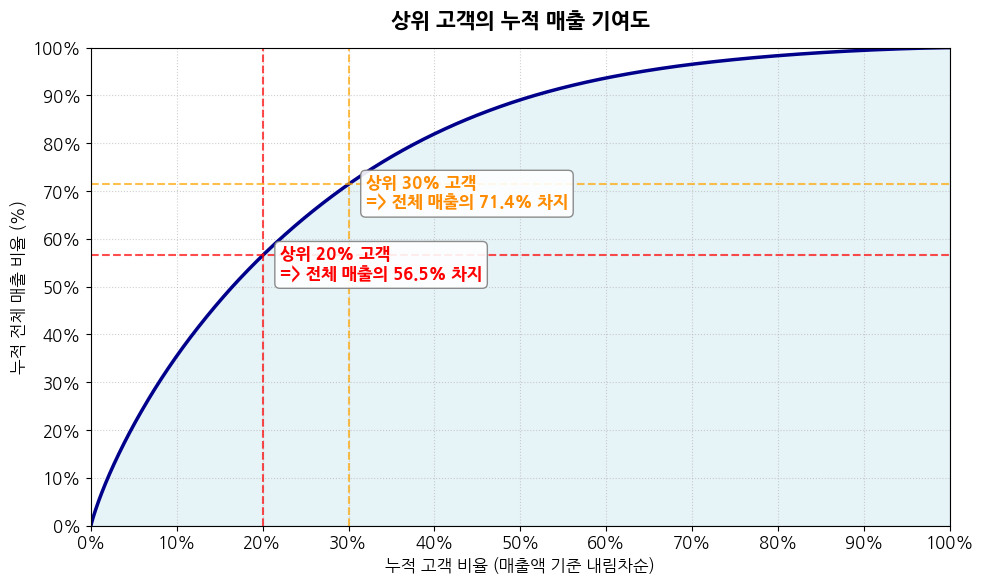

In [363]:
# 1. 데이터 준비 (결제 금액이 0보다 큰 고객만 대상)
active_customers = rfm_buyers.copy()  # target_df = rfm_2024_labeled[rfm_2024_labeled['segment'] != 'Dormant']

# 2. Monetary 기준 내림차순 정렬 (매출이 가장 높은 고객부터)
active_customers = active_customers.sort_values(by='monetary', ascending=False).reset_index(drop=True)

# 3. 누적 비율 계산
total_customers = len(active_customers)
total_revenue = active_customers['monetary'].sum()

# X축: 누적 고객 비율 (0 ~ 100%)
active_customers['cum_customer_pct'] = (active_customers.index + 1) / total_customers * 100

# Y축: 누적 매출 비율 (0 ~ 100%)
active_customers['cum_revenue_pct'] = (active_customers['monetary'].cumsum() / total_revenue) * 100

# 4. 상위 20%, 30% 지점의 데이터 찾기
# 가장 가까운 누적 고객 비율 인덱스를 찾음
idx_top20 = (active_customers['cum_customer_pct'] - 20).abs().idxmin()
idx_top30 = (active_customers['cum_customer_pct'] - 30).abs().idxmin()

revenue_pct_at_20 = active_customers.loc[idx_top20, 'cum_revenue_pct']
revenue_pct_at_30 = active_customers.loc[idx_top30, 'cum_revenue_pct']

# 5. 로렌츠 곡선(누적 비중 차트) 시각화
fig, ax = plt.subplots(figsize=(10, 6))

# 곡선 그리기
sns.lineplot(x='cum_customer_pct', y='cum_revenue_pct', data=active_customers, 
             color='darkblue', linewidth=2.5, ax=ax)

# 배경색 칠하기 (선택 사항: 누적 면적을 시각적으로 강조)
ax.fill_between(active_customers['cum_customer_pct'], active_customers['cum_revenue_pct'], 
                color='lightblue', alpha=0.3)

# 기준선 추가: 상위 20%
ax.axvline(x=20, color='red', linestyle='--', alpha=0.7)
ax.axhline(y=revenue_pct_at_20, color='red', linestyle='--', alpha=0.7)

# 기준선 추가: 상위 30%
ax.axvline(x=30, color='orange', linestyle='--', alpha=0.7)
ax.axhline(y=revenue_pct_at_30, color='orange', linestyle='--', alpha=0.7)

# 텍스트 어노테이션 (교차점에 표시)
bbox_props = dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=1, alpha=0.9)

ax.text(20 + 2, revenue_pct_at_20 - 5, 
        f"상위 20% 고객\n=> 전체 매출의 {revenue_pct_at_20:.1f}% 차지", 
        color='red', fontweight='bold', bbox=bbox_props)

ax.text(30 + 2, revenue_pct_at_30 - 5, 
        f"상위 30% 고객\n=> 전체 매출의 {revenue_pct_at_30:.1f}% 차지", 
        color='darkorange', fontweight='bold', bbox=bbox_props)

# 축 설정
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_title("상위 고객의 누적 매출 기여도", fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("누적 고객 비율 (매출액 기준 내림차순)", fontsize=12)
ax.set_ylabel("누적 전체 매출 비율 (%)", fontsize=12)

# 축 라벨 포맷 변경 (10, 20 -> 10%, 20%)
ax.xaxis.set_major_formatter(ticker.PercentFormatter())
ax.yaxis.set_major_formatter(ticker.PercentFormatter())

# X, Y축 눈금 세밀하게 설정 (10% 단위)
ax.set_xticks(np.arange(0, 101, 10))
ax.set_yticks(np.arange(0, 101, 10))
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

**상위 20% 고객이 전체 매출의 56.5%를 차지하고 있으며, 상위 30% 고객이 전체 매출의 71.4%를 차지하고 있음.**

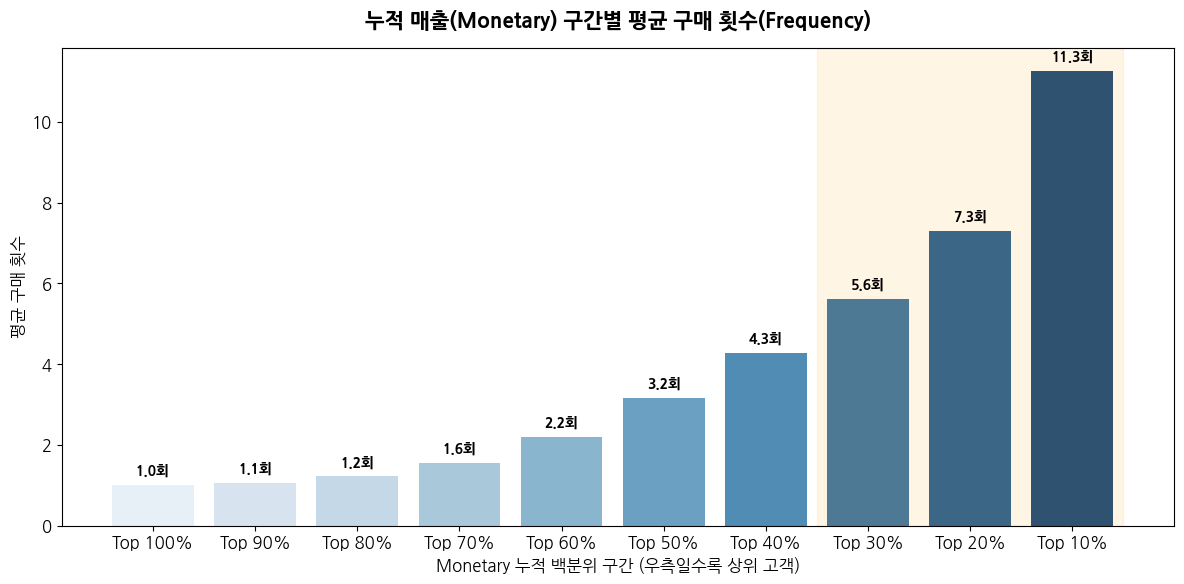

In [364]:
# 1. Monetary 상위 N% 파생 변수 생성 (qcut 사용)
# 10분위수(Deciles)로 나누어, 상위 10% 단위로 그룹화
active_customers['monetary_decile'] = pd.qcut(active_customers['monetary'], q=10, labels=False)
# 라벨을 직관적으로 변경 (0: 하위 10%, 9: 상위 10%)
# 이를 상위 % 텍스트로 매핑 (예: 9 -> 'Top 10%', 8 -> 'Top 20%' ...)
decile_labels = {i: f"Top {100 - i*10}%" for i in range(10)}
active_customers['monetary_group'] = active_customers['monetary_decile'].map(decile_labels)

# 2. Monetary 그룹별 평균 Frequency 집계
freq_by_m_group = active_customers.groupby('monetary_group')['frequency'].mean().reset_index()

# x축 정렬을 위해 'Top 100%' 부터 'Top 10%' 순서로 리스트 생성
order_list = [f"Top {x}%" for x in range(100, 0, -10)]

# 3. 바 차트 시각화
fig, ax = plt.subplots(figsize=(12, 6))

# 색상 그라데이션 (상위 그룹일수록 진한 색)
palette = sns.color_palette("Blues", n_colors=10)

sns.barplot(
    data=freq_by_m_group,
    x='monetary_group',
    y='frequency',
    order=order_list,
    palette=palette,
    ax=ax
)

# 텍스트 추가 (바 위에 평균 횟수 표시)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}회", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='black', xytext=(0, 5), textcoords='offset points')

ax.set_title("누적 매출(Monetary) 구간별 평균 구매 횟수(Frequency)", fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Monetary 누적 백분위 구간 (우측일수록 상위 고객)", fontsize=12)
ax.set_ylabel("평균 구매 횟수", fontsize=12)

# 파레토에서 언급한 Top 30% 영역을 하이라이트 (선택 사항)
ax.axvspan(6.5, 9.5, color='orange', alpha=0.1) # Top 30% ~ Top 10% 영역 배경색
# ax.text(8, freq_by_m_group['frequency'].max() * 0.8, "매출의 71.4%를\n견인하는 핵심 집단\n(높은 Frequency가 특징)", 
#         color='darkorange', fontweight='bold', ha='center', bbox=dict(facecolor='white', alpha=0.8, edgecolor='orange'))

plt.tight_layout()
plt.show()

상위 30% 고객들이 High AOV 일지, High Frequency일지 확인하기 위해 Monetary를 10분위 구간으로 분할하고, 주문 금액에 따른 주문 빈도를 확인함.

확인 결과, 상위 30% 고객들은 높은 빈도로 구매하는 것으로 확인됨.

따라서, 상위 30% 고객을 분할하여 관리하기 위해 Frequency 구간을 고정 구간으로 분할

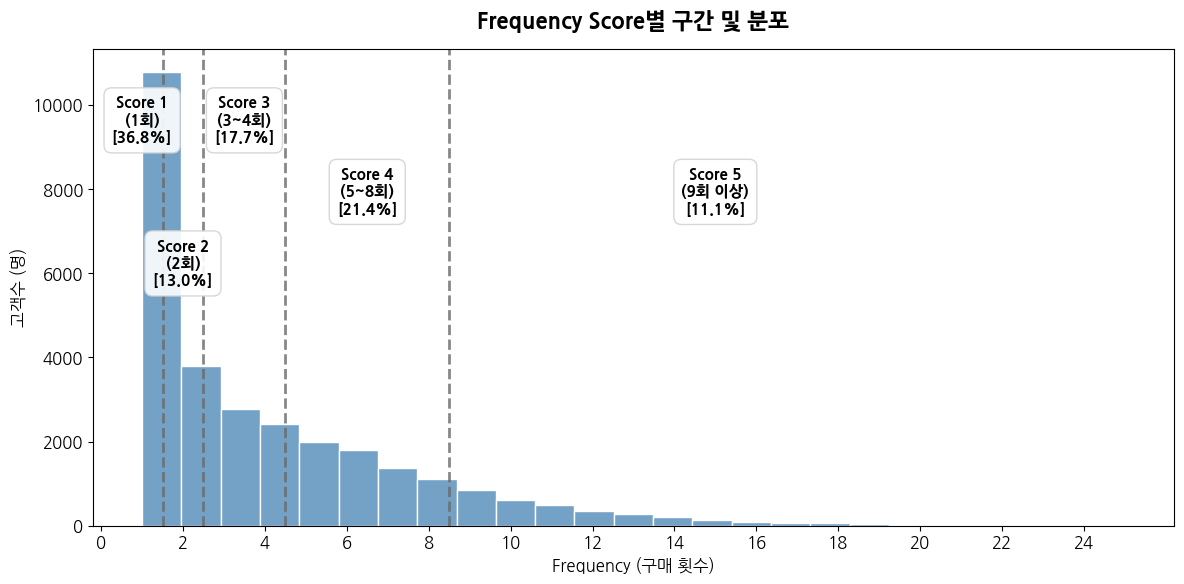

In [365]:
# --- 1. Frequency 고정 구간 설정 시각화 ---
fig, ax = plt.subplots(figsize=(12, 6))

# Frequency 분포가 낮은 쪽에 몰려 있으므로 너무 꼬리가 긴 부분은 잘라내서 보여주기 (예: 20회 이하만)
plot_df = rfm_buyers[rfm_buyers['frequency'] <= 25]

# 히스토그램 그리기
sns.histplot(plot_df["frequency"], bins=25, kde=False, ax=ax, color="steelblue", edgecolor='white')

# 우리가 설정한 고정 구간 경계값 (Score 1~5)
# 1점: 1회, 2점: 2회, 3점: 3~4회, 4점: 5~8회, 5점: 9회 이상
boundaries = [1.5, 2.5, 4.5, 8.5]  # 경계선 그리기 위한 좌표
labels = ['Score 1\n(1회)', 'Score 2\n(2회)', 'Score 3\n(3~4회)', 'Score 4\n(5~8회)', 'Score 5\n(9회 이상)']

# 경계선 추가 (모두 짙은 회색으로 통일)
for b in boundaries:
    ax.axvline(x=b, color='dimgray', linestyle='--', linewidth=2, alpha=0.8)

# 각 구간의 중심에 텍스트 라벨 추가
y_max = ax.get_ylim()[1]
x_centers = [1, 2, 3.5, 6.5, 15]

for i, (x_c, label) in enumerate(zip(x_centers, labels)):
    # 구간별 고객 비율 계산 (target_df 기준)
    if x_c == 1: mask = rfm_buyers['frequency'] == 1
    elif x_c == 2: mask = rfm_buyers['frequency'] == 2
    elif x_c == 3.5: mask = rfm_buyers['frequency'].between(3, 4)
    elif x_c == 6.5: mask = rfm_buyers['frequency'].between(5, 8)
    else: mask = rfm_buyers['frequency'] >= 9
        
    pct = (mask.sum() / len(rfm_buyers)) * 100
    
    # 텍스트 박스가 겹치지 않도록 앞부분(1, 2, 3구간)은 높이를 지그재그로 조정
    if i == 0:
        y_pos = y_max * 0.85
    elif i == 1:
        y_pos = y_max * 0.55
    elif i == 2:
        y_pos = y_max * 0.85
    else:
        y_pos = y_max * 0.7
    
    ax.text(x=x_c, y=y_pos, s=f"{label}\n[{pct:.1f}%]", 
            ha='center', va='center', fontsize=11, fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='lightgray', boxstyle='round,pad=0.5'))

ax.set_title("Frequency Score별 구간 및 분포", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Frequency (구매 횟수)", fontsize=12)
ax.set_ylabel("고객수 (명)", fontsize=12)
plt.xticks(np.arange(0, 26, 2))

plt.tight_layout()
plt.show()

- 1회 구매(1점)와 2회 구매(2점) 분리.
    - 이커머스에서 '첫 구매'를 '재구매'로 유도하는 것이 가장 어렵기 때문.
- 빈도가 촘촘한 3~4회, 5~8회, 9회 이상 구간을 세밀하게 나누어, 상위 30% 내에서도 '진짜 단골'과 '일반 단골' 구분.

#### 1.1.3.3. Recency 고정 구간 로직 설정

- **판단 기준 (고객 생애 주기)**: Recency는 R, F, M 중 유일하게 '시간이 지날수록 나빠지는' 지표입니다.
- **현재 상황 적용**:
    - 성장세가 둔화되고 있다는 것은 '과거에 한 번 사고 최근에 안 사는 휴면/이탈 고객'이 쌓이고 있다는 뜻입니다.
    - 예를 들어, 상대평가(분위수)를 하면 다 같이 안 사고 있을 때 "90일 전에 산 사람"이 최고점인 5점을 받는 착시가 생깁니다.
    - Monetary Top 10%는 "우리 플랫폼에서 돈을 제일 많이 쓴 10%"라는 분위수가 갖는 명확한 의미가 있는 반면, Recency Top 10%는 큰 의미를 갖지 않음.
- 의류/패션은 보통 '시즌(3~6개월)' 단위로 고객이 이탈했는지 여부를 판단합니다. 이와 같은 생애주기 기준(Rule)을 기반으로 고정 구간을 설정하여 Recency 점수를 부여함.
- 최근 1년(2024년) 고객의 Recency 분포를 기반으로, 고객의 생애주기를 가정하여 고정 구간을 설정함.

**[기존 5분위 분할 구간]**

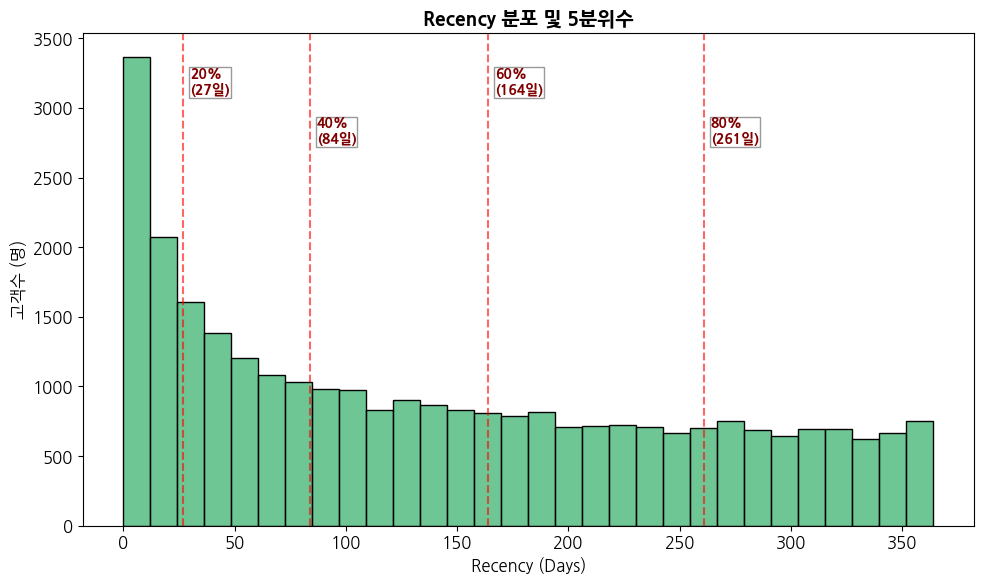

In [366]:
# 단일 차트 설정
fig, ax = plt.subplots(figsize=(10, 6))

# Recency 히스토그램 그리기
sns.histplot(rfm_buyers["recency_days"], bins=30, kde=False, ax=ax, color="mediumseagreen")
ax.set_title("Recency 분포 및 5분위수", fontsize=14, fontweight="bold")
ax.set_xlabel("Recency (Days)", fontsize=12)
ax.set_ylabel("고객수 (명)", fontsize=12)

# 5분위수(20%, 40%, 60%, 80%) 계산
quintiles = [0.2, 0.4, 0.6, 0.8]
quantiles_r = rfm_buyers["recency_days"].quantile(quintiles)

# 중복 분위수 제거
unique_quantiles_r = quantiles_r.drop_duplicates()

y_max = ax.get_ylim()[1]

# 세로선과 분위수 텍스트 추가
for i, (q_label, x_val) in enumerate(unique_quantiles_r.items()):
    ax.axvline(x=x_val, color='red', linestyle='--', alpha=0.6)
    
    pct_str = f"{int(q_label * 100)}%"
    # 텍스트가 겹치지 않게 지그재그 배치
    y_pos = y_max * (0.9 - (i % 2) * 0.1)
    
    ax.text(
        x=x_val + 3, # Recency는 X축 범위가 넓으므로 여백을 줌
        y=y_pos, 
        s=f"{pct_str}\n({int(x_val)}일)", 
        color='maroon', 
        ha='left', 
        va='center', 
        fontsize=10,
        fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', pad=0.5)
    )

plt.tight_layout()
plt.show()

**Quintiles를 참고하여 점수별 임계값 설정**

- 5점 (Active / Hot): 0 ~ 30일 이내 (가장 최근에 구매하여 우리 브랜드가 머릿속에 있는 핫한 타겟. 즉각적인 재구매 유도 가능)
- 4점 (Warm): 31 ~ 90일 이내 (한 시즌 내 구매자. 관심도가 서서히 식어가는 중으로 리마인드 쿠폰이 효과적인 시기)
- 3점 (Cooling down): 91 ~ 180일 이내 (계절이 한 번 바뀜. 이탈 위험이 커지기 시작하는 단계)
- 2점 (At Risk): 181 ~ 270일 이내 (브랜드를 잊어가는 단계로, 파격적인 혜택을 통한 재활성화 노력이 필수적임.)
- 1점 (Churning): 271 ~ 365일 이내 (완전한 휴면(Dormant, 0점)으로 넘어가기 직전의 마지막 방어선. 대대적인 컴백 프로모션 대상.)

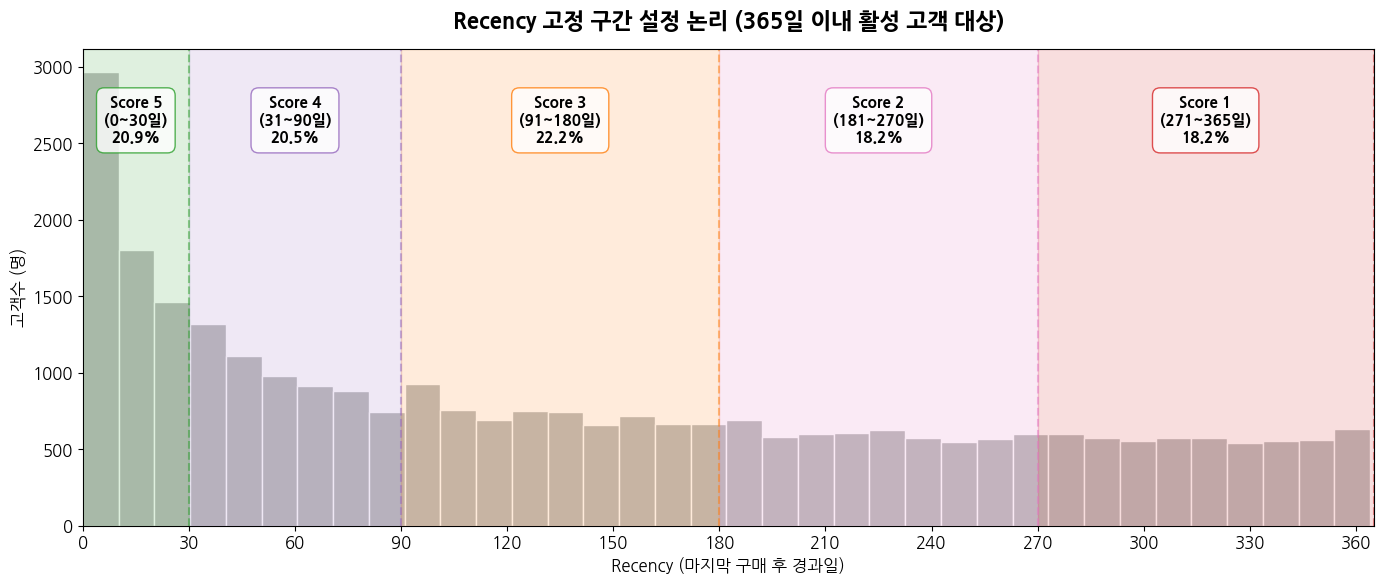

In [367]:
# --- 2. Recency 고정 구간 설정 시각화 (수정 반영) ---
fig, ax = plt.subplots(figsize=(14, 6))

# 시각화의 집중도를 높이기 위해 365일 이내(1~5점 대상자) 데이터만 필터링하여 그립니다.
plot_r_df = rfm_buyers.copy()

# 히스토그램 그리기
sns.histplot(plot_r_df["recency_days"], bins=36, kde=False, ax=ax, color="darkgray", edgecolor='white')

# CRM 기반 고정 구간 정의 (1년 이내를 5등분)
# 5점(0~30), 4점(30~90), 3점(90~180), 2점(180~270), 1점(270~365)
spans = [(0, 30), (30, 90), (90, 180), (180, 270), (270, 365)]
colors = ['#2ca02c', '#9467bd', '#ff7f0e', '#e377c2', '#d62728']
# scores = ['Score 5\n(0~30일)\n[Hot/Active]', 
#           'Score 4\n(31~90일)\n[Warm]', 
#           'Score 3\n(91~180일)\n[Cooling]', 
#           'Score 2\n(181~270일)\n[At Risk]', 
#           'Score 1\n(271~365일)\n[Churning]']
scores = ['Score 5\n(0~30일)', 
          'Score 4\n(31~90일)', 
          'Score 3\n(91~180일)', 
          'Score 2\n(181~270일)', 
          'Score 1\n(271~365일)']

y_max = ax.get_ylim()[1]

# 구간별 배경색(axvspan) 칠하기 및 텍스트 삽입
for i, (span, color, score_text) in enumerate(zip(spans, colors, scores)):
    ax.axvspan(span[0], span[1], color=color, alpha=0.15) # 배경색
    ax.axvline(span[1], color=color, linestyle='--', linewidth=1.5, alpha=0.5) # 경계선
    
    # 365일 이하 전체 모수 대비 해당 구간의 고객 비율 계산 (옵션)
    # 만약 원본 전체(0점 포함) 대비 비율을 원하시면 len(target_df)를 쓰시면 됩니다.
    mask = plot_r_df['recency_days'].between(span[0], span[1], inclusive='left')
    if i == 4: # 마지막 구간은 365일 딱 떨어지는 것 포함
        mask = plot_r_df['recency_days'].between(span[0], span[1], inclusive='both')
    
    pct = (mask.sum() / len(plot_r_df)) * 100
    
    # 텍스트 위치 계산 (구간의 가운데)
    x_center = span[0] + (span[1] - span[0]) / 2
        
    ax.text(x_center, y_max * 0.85, f"{score_text}\n{pct:.1f}%", 
            ha='center', va='center', fontsize=11, fontweight='bold', color='black',
            bbox=dict(facecolor='white', alpha=0.8, edgecolor=color, boxstyle='round,pad=0.5'))

ax.set_title("Recency 고정 구간 설정 논리 (365일 이내 활성 고객 대상)", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Recency (마지막 구매 후 경과일)", fontsize=12)
ax.set_ylabel("고객수 (명)", fontsize=12)
ax.set_xlim(0, 365) 
ax.set_xticks(np.arange(0, 361, 30)) # 30일 간격으로 x축 눈금 표시

plt.tight_layout()
plt.show()

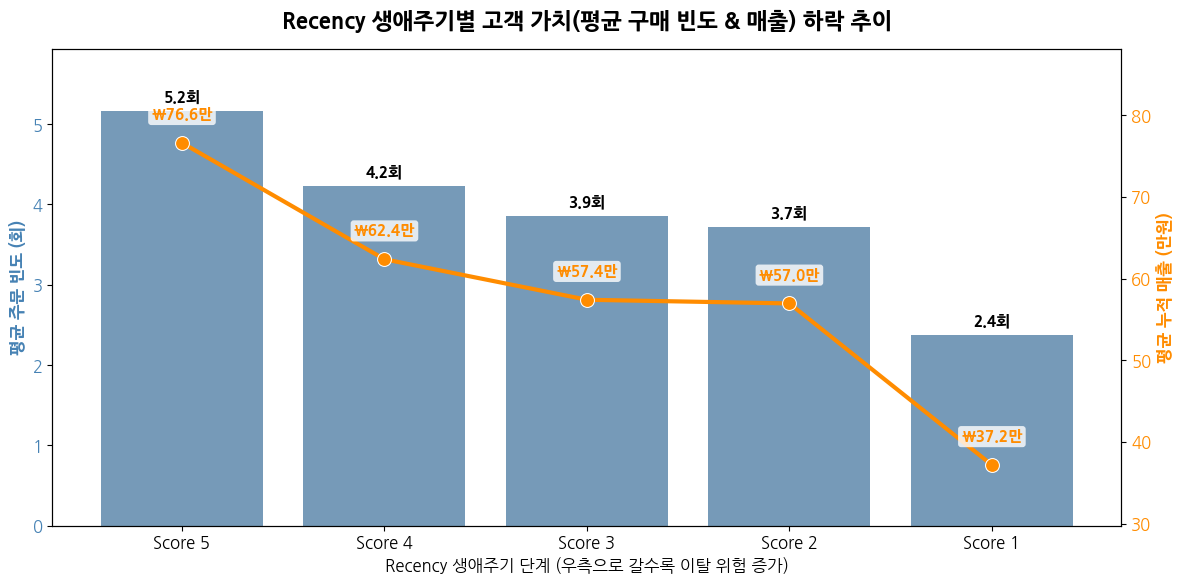

In [369]:
# 1. R_score 그룹별 집계 (Dormant인 0점 제외, 5점->1점 순으로 정렬)
r_group_stats = rfm_buyers[rfm_buyers['R_score'] > 0].groupby('R_score').agg(
    mean_freq=('frequency', 'mean'),
    mean_monetary=('monetary', 'mean'),
    customer_count=('user_id', 'count')
).reset_index()

r_group_stats = r_group_stats.sort_values('R_score', ascending=False)

# Monetary 단위 만원으로 변경
r_group_stats['mean_monetary_manwon'] = r_group_stats['mean_monetary'] / 10000

# X축 라벨 단순화
r_labels = {
    5: 'Score 5',
    4: 'Score 4',
    3: 'Score 3',
    2: 'Score 2',
    1: 'Score 1'
}
r_group_stats['R_label'] = r_group_stats['R_score'].map(r_labels)

# 2. 이중 축(Dual-axis) 시각화 
fig, ax1 = plt.subplots(figsize=(12, 6))

# 왼쪽 Y축: 막대 그래프 (평균 구매 빈도)
sns.barplot(
    data=r_group_stats, 
    x='R_label', 
    y='mean_freq', 
    color='steelblue', 
    alpha=0.8, 
    ax=ax1
)
ax1.set_ylabel('평균 주문 빈도 (회)', fontsize=12, color='steelblue', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.set_xlabel('Recency 생애주기 단계 (우측으로 갈수록 이탈 위험 증가)', fontsize=12)

# 막대 상단 여유 공간 확보 (텍스트 겹침 방지)
ax1.set_ylim(0, r_group_stats['mean_freq'].max() * 1.15)

# 막대 위에 값 표시
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.1f}회", 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='bottom', fontsize=11, fontweight='bold', color='black', 
                 xytext=(0, 5), textcoords='offset points')

# 오른쪽 Y축: 꺾은선 그래프 (평균 누적 매출)
ax2 = ax1.twinx()
sns.lineplot(
    data=r_group_stats, 
    x='R_label', 
    y='mean_monetary_manwon', 
    color='darkorange', 
    marker='o', 
    linewidth=3, 
    markersize=10, 
    ax=ax2
)
ax2.set_ylabel('평균 누적 매출 (만원)', fontsize=12, color='darkorange', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='darkorange')

# 오른쪽 Y축 상단/하단 여유 공간 확보 (선택 라벨이 잘리지 않도록)
y2_min = r_group_stats['mean_monetary_manwon'].min()
y2_max = r_group_stats['mean_monetary_manwon'].max()
ax2.set_ylim(y2_min * 0.8, y2_max * 1.15)

# 선 그래프 마커 근처에 값 표시 (가독성 향상을 위해 텍스트 배경(bbox) 추가 및 zorder 설정)
for i, row in r_group_stats.reset_index(drop=True).iterrows():
    ax2.annotate(f"₩{row['mean_monetary_manwon']:,.1f}만", 
                 xy=(i, row['mean_monetary_manwon']),
                 xytext=(0, 15), # 마커 위쪽으로 약간 이동
                 textcoords='offset points',
                 color='darkorange', fontweight='bold', fontsize=11, 
                 ha='center', va='bottom', zorder=10,
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))

plt.title("Recency 생애주기별 고객 가치(평균 구매 빈도 & 매출) 하락 추이", fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

[최상위 구간 (Score 5: Hot / 0~30일)]
- 평균 구매 횟수 5.1회, 평균 누적 매출 $760,344로 모든 구간 중 압도적인 1위를 기록
- 우리 쇼핑몰의 최상위 VIP 고객들은 본질적으로 "최근에도 우리 사이트에서 지갑을 연" 사람들
- 신상품 우선 안내나 VVIP 전용 혜택을 제공하여 '록인(Lock-in)'을 강화

[이탈 경고 구간 (Score 4 ~ 3 : Warm & Cooling / 30일~180일)]
- 구매 횟수가 5.1회에서 4.2회 -> 3.8회로 계단식으로 하락하고 있으며, 매출 역시 620K−>570K 수준으로 완만하게 떨어지는 모습
- 고객이 구매를 쉬는 기간이 길어질수록, 그 고객이 원래 가지고 있던 '절대적인 가치(과거 누적 구매액과 빈도)' 자체도 낮아지는 경향이 뚜렷
- Score 3 (Cooling, 3~6개월 미방문) 구간에 진입했다는 것은 단순한 '휴식기'를 넘어 경쟁사로 이탈하기 시작했다는 강한 시그널
- 가벼운 타겟팅 쿠폰(Win-back)을 통해 다시 구매 사이클을 'Score 5'로 돌려놓는 것이 CRM 마케팅의 핵심 과제

[골든 타임 붕괴 구간 (Score 2 -> 1 : At Risk -> Churning / 180일~365일)]
- Score 2(3.7회, 564K)에서 Score1(2.3회,355K)로 넘어갈 때 차트의 꺾은선이 말 그대로 폭락함
- `가장 중요한 시사점`: 마지막 구매 후 270일(Score 2의 끝)이 넘어가면 고객의 가치는 반토막남
- Score 1(Churning)의 절벽으로 떨어지기 직전인 'Score 2 (At Risk)' 구간에서 수단과 방법을 가리지 않고 이탈 방어 캠페인을 전개해야 함
- 이때를 놓치면 고객을 데려오는 비용이 신규 고객 획득 비용(CAC)만큼 비싸질 것임

재구매까지의 공백 기간(Recency)이 길어질수록 고객 가치(Frequency, Monetary)는 우하향하며, 특히 미방문 9개월(270일)을 기점으로 가치가 급락하는 임계점 확인

#### 1.1.3.4. 변경된 R, F Score 분포 시각적 확인

In [370]:
# Frequency 고정 구간 스코어링 함수
def get_f_score(f):
    if f >= 9: return 5   # 9회 이상 (매출 파레토 차트에서 Top 10~20%를 견인하는 초핵심 VVIP)
    elif f >= 5: return 4 # 4점 (우수 고객): 5~8회 (매출 상위 30%를 구성하기 시작하는 든든한 허리층)
    elif f >= 3: return 3 # 3점 (정착 단계): 3~4회 (안정적인 재구매가 일어나기 시작하는 그룹)
    elif f == 2: return 2 # 2점 (초기 재구매): 2회 (마의 2회차 장벽을 넘은 그룹)
    else: return 1        # 1점 (하위): 1회 (가입 후 한 번만 사고 이탈/대기)

# Recency 고정 구간 스코어링 함수
def get_r_score(r):
    """
    Recency(최근 구매 경과일)에 따른 고정 구간 스코어링
    - r: 마지막 구매 후 경과일(recency_days)
    - 반환값: 0~5점 (1년 초과는 휴면 간주하여 0점 처리)
    """
    if pd.isna(r):        # 결측치(구매 이력 없음) 방어 로직
        return 0
    elif r <= 30: return 5   # 5점 (Active/Hot): 0~30일 이내 (가장 최근 구매, 즉각적 재구매 유도 가능)
    elif r <= 90: return 4   # 4점 (Warm): 31~90일 이내 (한 시즌 내 구매자, 리마인드 쿠폰 효과적)
    elif r <= 180: return 3  # 3점 (Cooling down): 91~180일 이내 (이탈 위험 발생 시작, 가벼운 윈백 캠페인)
    elif r <= 270: return 2  # 2점 (At Risk): 181~270일 이내 (반년 이상 미방문, 파격적 혜택 필요)
    elif r <= 365: return 1  # 1점 (Churning): 271~365일 이내 (휴면 진입 직전, 마지막 컴백 프로모션 대상)
    else: return 0           # 0점 (Dormant): 365일 초과 (장기 미구매로 인한 휴면/이탈 고객)    

# RFM 초기 설정 (F는 고정 구간, R/M은 5분위수 적용)
def rfm_quintile_scoring(rfm_df, lookback_days: int = 365):
    """
    입력 rfm_df 필수 컬럼:
      - recency_days (int)
      - frequency (int)
      - monetary (float)
    출력:
      - R_score, F_score, M_score (1~5, 높을수록 우수)
      - RFM_score (문자열: 예 '545')
      - RFM_sum (정수 합계)
    """    
    out = rfm_df.copy()

    # 미구매 마스크: recency_days > lookback_days or frequency=0 or monetary=0
    non_buyer_mask = (
        (out["recency_days"] > lookback_days)  # 최근 구매일이 분석 기간 초과
        | (out["frequency"] == 0)              # 구매 횟수 0회
        | (out["monetary"] == 0)               # 구매 금액 0원
    )

    # 미구매는 0점으로 기본값 부여
    out["R_score"] = 0
    out["F_score"] = 0
    out["M_score"] = 0

    # 구매자만 스코어링 진행
    buyers = out.loc[~non_buyer_mask].copy()

    # 1. Recency: 작을수록 좋음 → 역정렬 5분위수
    buyers["R_score"] = buyers["recency_days"].apply(get_r_score)

    # 2. Frequency: 고정 구간 로직 반영 (qcut 대신 get_f_score 함수 적용)
    buyers["F_score"] = buyers["frequency"].apply(get_f_score)

    # 3. Monetary: 클수록 좋음 → 5분위수
    m_cut = pd.qcut(
        buyers["monetary"],
        q=5,
        duplicates="drop")
    n_bins_m = len(m_cut.cat.categories)
    buyers["M_score"] = m_cut.cat.codes.astype(int) + 1

    # 계산된 스코어 본 데이터에 반영
    out.loc[buyers.index, ["R_score", "F_score", "M_score"]] = buyers[["R_score", "F_score", "M_score"]]

    # --- 합성 점수
    out["RFM_score"] = (
        out["R_score"].astype(str)
        + out["F_score"].astype(str)
        + out["M_score"].astype(str)
    )
    out["RFM_sum"] = out[["R_score", "F_score", "M_score"]].sum(axis=1)

    return out

In [371]:
lookback_days = 365
rfm_2024_scored = rfm_quintile_scoring(rfm_2024_df, lookback_days = lookback_days)
rfm_2024_scored.head()

,user_id,created_at,age,gender,traffic_source,last_order_dt,frequency,monetary,recency_days,days_since_signup,aov_user,R_score,F_score,M_score,RFM_score,RFM_sum
0,1,2023-09-20 03:01:49,23,M,direct,2024-02-08 00:28:36,2,258250.0,327,467,129125.00,1,2,3,123,6
1,2,2023-11-01 17:43:31,20,F,email,2024-05-22 01:31:56,10,1817400.0,223,425,181740.00,2,5,5,255,12
2,3,2023-11-09 05:37:17,27,F,direct,NaT,0,0.0,1364,417,0.00,0,0,0,000,0
3,4,2024-09-07 16:42:36,25,M,organic_search,NaT,0,0.0,1364,114,0.00,0,0,0,000,0
4,5,2023-12-23 19:45:29,24,M,direct,2024-09-12 17:47:49,11,1691780.0,110,373,153798.18,3,5,5,355,13


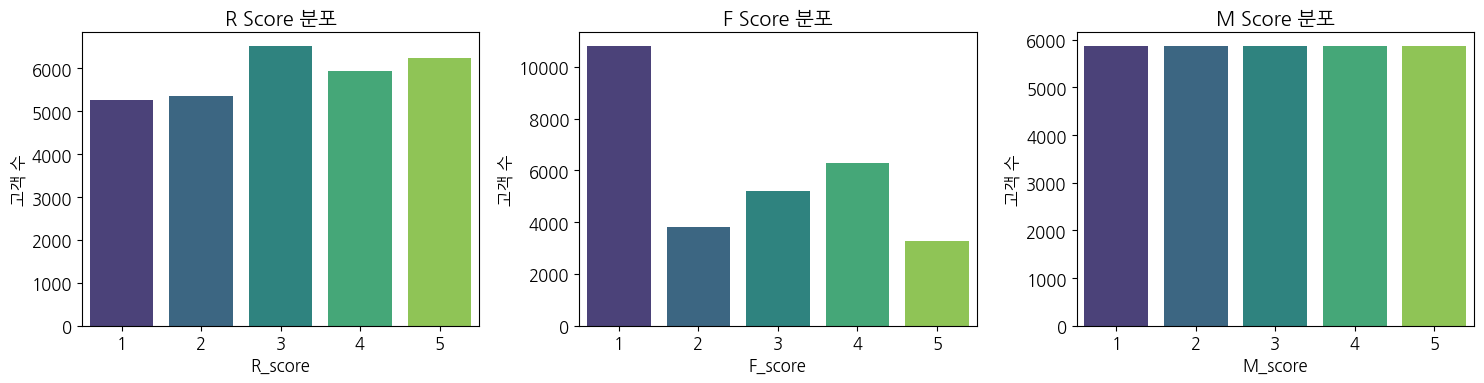

In [372]:
score_cols = ["R_score", "F_score", "M_score"]
titles = ["R Score 분포", "F Score 분포", "M Score 분포"]

# 0점 제외: 구매자(또는 세 점수 모두 부여된 고객)만
mask = (rfm_2024_scored["RFM_sum"] > 0)
rfm_buyers = rfm_2024_scored.loc[mask]

score_cols = ["R_score", "F_score", "M_score"]
titles = ["R Score 분포", "F Score 분포", "M Score 분포"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, title in zip(axes, score_cols, titles):
    order = list(range(1, 6))
    sns.countplot(data=rfm_buyers, x=col, order=order, ax=ax, palette="viridis")
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel("고객 수")

plt.tight_layout()
plt.show()

### 1.1.4. RFM score에 따른 세그먼트 분할 및 EDA

1. 현재 Rule의 논리적 타당성 진단 (비즈니스/확률적 관점)

    현재 설정된 VIP 조건은 (R >= 4) & (F >= 4) & (M >= 4) 입니다.
- 확률적 볼륨 예측 (독립 사건 가정): 만약 R, F, M이 서로 완전히 독립적인 지표라면, 교집합의 확률은 $P(R≥4)×P(F≥4)×P(M≥4)$가 됩니다. 즉, 0.4×0.32×0.4=0.0512, 전체 고객의 약 5.1% 만이 VIP가 됩니다. Loyal 집단까지 합치더라도 상당히 적은 비율이 될 수 있습니다.
- 비즈니스적 현실 (상관관계 고려): 다행히도 이커머스에서 R, F, M은 서로 강한 양의 상관관계를 가집니다. 자주 산 사람(F)이 누적 금액(M)도 높고, 최근에 샀을(R) 확률이 높습니다. 따라서 실제 VIP 비중은 5.1%보다는 훨씬 높은 10~15% 내외로 형성될 가능성이 큽니다.
- 타당성 진단 결론: 초기 의도인 "상위 20~30%가 매출을 견인한다"는 파레토 법칙에 비추어 볼 때, VIP 모수가 10~15%라면 룰이 너무 엄격한 것이 아닙니다. 오히려 "매출의 절반을 책임지는 '핵심 10%'를 타겟팅하겠다"는 마케팅 부서의 니즈(예: 한정된 VIP 혜택 예산)와 맞닿아 있습니다.

2. 세그먼트 타당성 검증 방법론 (Validation in Python)

    설정한 Rule이 정상 동작하는지 확인하기 위해 '세그먼트별 프로파일링 및 기여도 분석'을 진행합니다.

[검증 지표 및 시각화]

1. 세그먼트별 고객 수 비중 vs 매출 기여도 비교 (가장 중요) 이 차트 하나로 파레토 법칙이 우리 분류에 잘 적용되었는지 증명할 수 있습니다.
- Python 구현 아이디어: 세그먼트별 user_id의 nunique() 비율과 monetary의 sum() 비율을 구하여 나란히(Side-by-side) 막대 그래프로 그립니다.
- 검증 포인트: "VIP는 전체 고객의 12%에 불과하지만, 전체 매출의 45%를 차지합니다."라는 결론이 나오면 세그먼테이션 대성공입니다.
2. 세그먼트별 RFM 평균값 (3D Scatter 또는 Radar Chart) 각 세그먼트가 RFM 공간에서 서로 명확히 분리(이질성)되어 있는지 확인합니다.
- Python 구현 아이디어: groupby('segment')[['recency_days', 'frequency', 'monetary']].mean()을 산출합니다.
- 검증 포인트: VIP의 평균 M값이 타 그룹과 확연히 차이 나고, At_Risk의 평균 R값(일수)이 현저히 높게 나타나는지 확인합니다.
3. 세그먼트별 객단가(AOV) 편차 검증 (Step 2 빌드업)
- Python 구현 아이디어: sns.boxplot(data=df, x='segment', y='aov')
- 검증 포인트: Regular 집단의 AOV 박스플롯에 '위쪽으로 긴 꼬리(이상치)'가 짙게 깔려 있다면, "여기에 고과금 1회성 고객(Big Spender)이 숨어 있다"는 Step 2의 논리적 근거(Evidence)가 됩니다.

In [373]:
def label_rfm_segments(scored_df: pd.DataFrame) -> pd.DataFrame:
    out = scored_df.copy()

    # 1. Dormant: 이탈/휴면 (분석 기간 내 구매 이력 없음)
    dormant_cond = (out["RFM_sum"] == 0)

    # 2. VIP: 최상위 핵심 고객 (R, F, M 모두 최상위권)
    vip_cond = (out["R_score"] >= 4) & (out["F_score"] >= 4) & (out["M_score"] >= 4)

    # 3. Loyal: 충성/반복 구매 고객 (VIP에는 못 미치나 꾸준한 구매)
    loyal_cond = (out["R_score"] >= 3) & (out["F_score"] >= 3) & (out["M_score"] >= 3)

    # 4. At_Risk: 이탈 위험군 (과거에 자주/많이 샀으나 최근 발길이 끊김)
    # F나 M이 우수(3 이상)했던 고객 중 최근성(R)이 위험 수준(2 이하)인 타겟
    at_risk_cond = (out["R_score"] <= 2) & ((out["F_score"] >= 3) | (out["M_score"] >= 3))

    # 5. Low_Value: 하위 고객 (과거에 한두 번 소액 구매 후 안 옴)
    low_value_cond = (out["F_score"] <= 2) & (out["M_score"] <= 2)

    conditions = [dormant_cond, vip_cond, loyal_cond, at_risk_cond, low_value_cond]
    choices = ["Dormant", "VIP", "Loyal", "At_Risk", "Low_Value"]

    # 7. Regular: 위 조건에 모두 해당하지 않는 중간 집단 (Default)
    out["segment"] = np.select(conditions, choices, default="Regular")
    
    return out

In [374]:
# rfm_df는 이전 단계에서 산출된 DataFrame
rfm_2024_labeled = label_rfm_segments(rfm_2024_scored)

# 결과 확인
display(rfm_2024_labeled[[
    "user_id", "days_since_signup", "recency_days", "frequency", "monetary", "aov_user",
    "R_score", "F_score", "M_score", "RFM_score", "RFM_sum", "segment"
]].head())

,user_id,days_since_signup,recency_days,frequency,monetary,aov_user,R_score,F_score,M_score,RFM_score,RFM_sum,segment
0,1,467,327,2,258250.0,129125.00,1,2,3,123,6,At_Risk
1,2,425,223,10,1817400.0,181740.00,2,5,5,255,12,At_Risk
2,3,417,1364,0,0.0,0.00,0,0,0,000,0,Dormant
3,4,114,1364,0,0.0,0.00,0,0,0,000,0,Dormant
4,5,373,110,11,1691780.0,153798.18,3,5,5,355,13,Loyal


In [375]:
def plot_rfm_radar_chart(df):
    """
    세그먼트별 R_score, F_score, M_score의 평균값을 비교하는 방사형(Radar) 차트
    *주의: 점수(Score) 컬럼이 존재해야 합니다.
    """
    # 1. 세그먼트별 스코어 평균 계산
    radar_df = df.groupby('segment')[['R_score', 'F_score', 'M_score']].mean().reset_index()
    categories = ['R_score', 'F_score', 'M_score']
    N = len(categories)
    
    # 2. 각도 계산 (원형 차트를 위해 360도를 N등분)
    angles = [n / float(N) * 2 * math.pi for n in range(N)]
    angles += angles[:1] # 다각형을 닫기 위해 첫 번째 각도를 맨 끝에 추가
    
    # 3. 시각화
    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
    
    for i, row in radar_df.iterrows():
        values = row[categories].tolist()
        values += values[:1] # 다각형을 닫기 위해 첫 번째 값을 맨 끝에 추가
        
        ax.plot(angles, values, linewidth=2, linestyle='solid', label=row['segment'])
        ax.fill(angles, values, alpha=0.1) # 면적 칠하기
        
    # 축 설정 (1점 ~ 5점 기준)
    plt.xticks(angles[:-1], categories, fontsize=11)
    ax.set_rlabel_position(0)
    plt.yticks([1, 2, 3, 4, 5], ["1", "2", "3", "4", "5"], color="grey", size=9)
    plt.ylim(0, 5.5)
    
    plt.title('세그먼트별 RFM 점수 프로필 (Radar Chart)', pad=20, fontweight='bold')
    plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
    plt.show()
    
    # 원본 수치(일수, 횟수, 금액)의 평균 테이블도 함께 출력하여 확인
    # print("▼ 세그먼트별 실제 원본 데이터 평균값 (Table)")
    # rfm_mean = df.groupby('segment')[['recency_days', 'frequency', 'monetary']].mean().round(2)
    # display(rfm_mean)

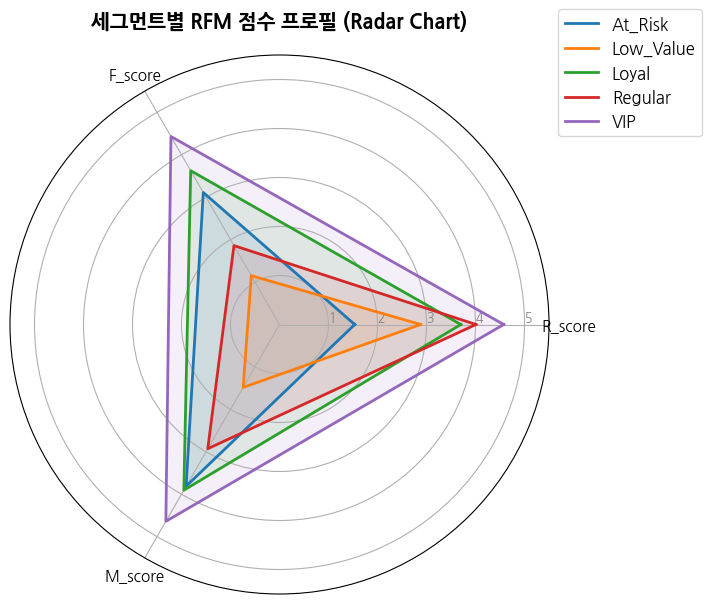

In [376]:
plot_rfm_radar_chart(rfm_2024_labeled[rfm_2024_labeled["segment"] != "Dormant"])

In [377]:
# 세그먼트 분포
segment_2024_dist = (
    rfm_2024_labeled["segment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("pct")
)
segment_2024_count = rfm_2024_labeled["segment"].value_counts()
segment_2024_summary = pd.DataFrame({'count': segment_2024_count, 'percentage': segment_2024_dist})

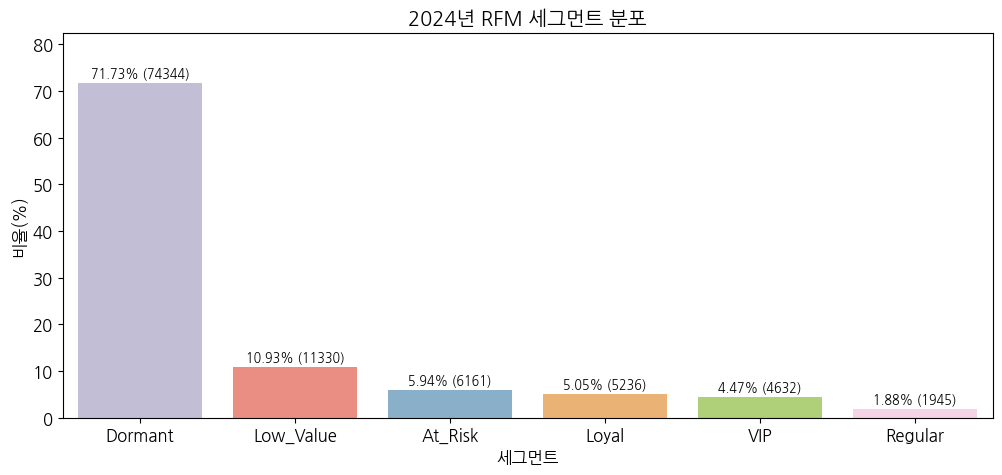

In [378]:
plt.figure(figsize=(12, 5))
ax = sns.barplot(x=segment_2024_summary.index, y=segment_2024_summary['percentage'], palette=sns.color_palette("Set3")[2:])
plt.title("2024년 RFM 세그먼트 분포")
plt.xlabel("세그먼트")
plt.ylabel("비율(%)")

# 각 바 위에 분포값(비율 및 수) 텍스트 표시
for i, (pct, count) in enumerate(zip(segment_2024_summary['percentage'], segment_2024_summary['count'])):
    ax.text(i, pct + 0.5, f"{pct:.2f}% ({count})", ha='center', va='bottom', fontsize=9)

# 차트 내부 상단 여백 추가
y_max = segment_2024_summary['percentage'].max()
ax.set_ylim(0, y_max * 1.15)

plt.show()

In [ ]:
def plot_segment_contribution(df):
    """
    세그먼트별 고객 수 비중과 매출 기여도를 나란히 비교하는 막대 그래프
    """
    # 1. 세그먼트별 고객 수 및 매출액 집계
    seg_stats = df.groupby('segment').agg(
        customer_cnt=('user_id', 'nunique'),
        revenue_sum=('monetary', 'sum')
    ).reset_index()
    
    # 2. 전체 대비 비율 계산 (%)
    seg_stats['customer_ratio'] = seg_stats['customer_cnt'] / seg_stats['customer_cnt'].sum() * 100
    seg_stats['revenue_ratio'] = seg_stats['revenue_sum'] / seg_stats['revenue_sum'].sum() * 100
    
    # 매출 기여도 순으로 내림차순 정렬
    seg_stats = seg_stats.sort_values(by='revenue_ratio', ascending=False)
    
    # 3. 시각화 (Side-by-side Bar Chart)
    fig, ax = plt.subplots(figsize=(10, 6))
    x = np.arange(len(seg_stats))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, seg_stats['customer_ratio'], width, label='고객 수 비중 (%)', color='#AEC6CF')
    bars2 = ax.bar(x + width/2, seg_stats['revenue_ratio'], width, label='매출 기여도 (%)', color='#FFB347')
    
    ax.set_ylabel('비중 (%)')
    ax.set_title('세그먼트별 고객 수 비중 vs 매출 기여도 (파레토 검증)', pad=15, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(seg_stats['segment'])
    ax.legend()
    
    # 막대 위에 수치(%) 표시
    for bar in bars1 + bars2:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.1f}%', ha='center', va='bottom', fontsize=9)
        
    plt.tight_layout()
    plt.show()
    
    return seg_stats

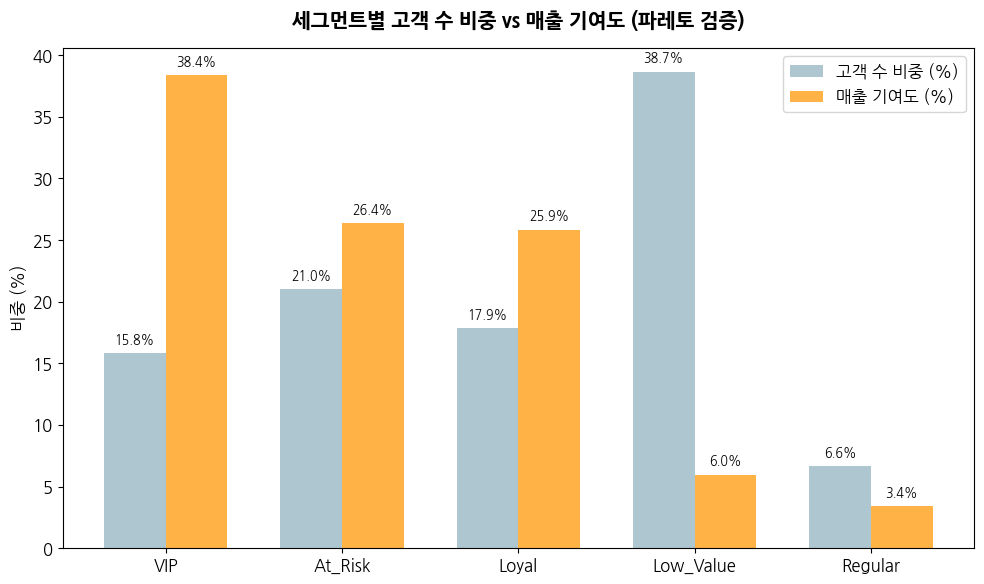

,segment,customer_cnt,revenue_sum,customer_ratio,revenue_ratio
4,VIP,4632,6.540435e+09,15.806716,38.383789
0,At_Risk,6161,4.492397e+09,21.024434,26.364489
2,Loyal,5236,4.405468e+09,17.867868,25.854331
1,Low_Value,11330,1.016217e+09,38.663664,5.963861
3,Regular,1945,5.850590e+08,6.637319,3.433530


In [380]:
plot_segment_contribution(rfm_2024_labeled[rfm_2024_labeled["segment"] != "Dormant"])

In [381]:
def plot_aov_boxplot(df):
    plt.figure(figsize=(12, 6))

    # 1. Boxplot 기본 형태 
    # (flierprops를 통해 이상치 점들의 스타일을 조절할 수 있습니다)
    sns.boxplot(
        data=df, 
        x='segment', 
        y='aov_user', 
        palette='Set2', 
        flierprops={"marker": "o", "markerfacecolor": "red", "markersize": 4, "alpha": 0.3}
    )

    plt.title('세그먼트별 객단가(AOV) 분포 및 이상치 확인', pad=15, fontweight='bold')
    plt.xlabel('세그먼트 (Segment)', fontweight='bold')
    plt.ylabel('평균 객단가 (AOV)', fontweight='bold')

    # y축에 화폐 단위처럼 콤마를 찍어주면 보기 좋습니다 (선택사항)
    current_values = plt.gca().get_yticks()
    plt.gca().set_yticklabels(['{:,.0f}'.format(x) for x in current_values])

    # 💡 팁: 만약 최고가 이상치가 너무 커서 박스가 납작해져 보이지 않는다면,
    # 아래 코드의 주석을 풀고 y축 상한선을 적절히 제한해 보세요. (예: 상위 99% 값 이하로 자르기)
    # y_limit = df['aov_user'].quantile(0.99)
    # plt.ylim(0, y_limit)

    plt.tight_layout()
    plt.show()

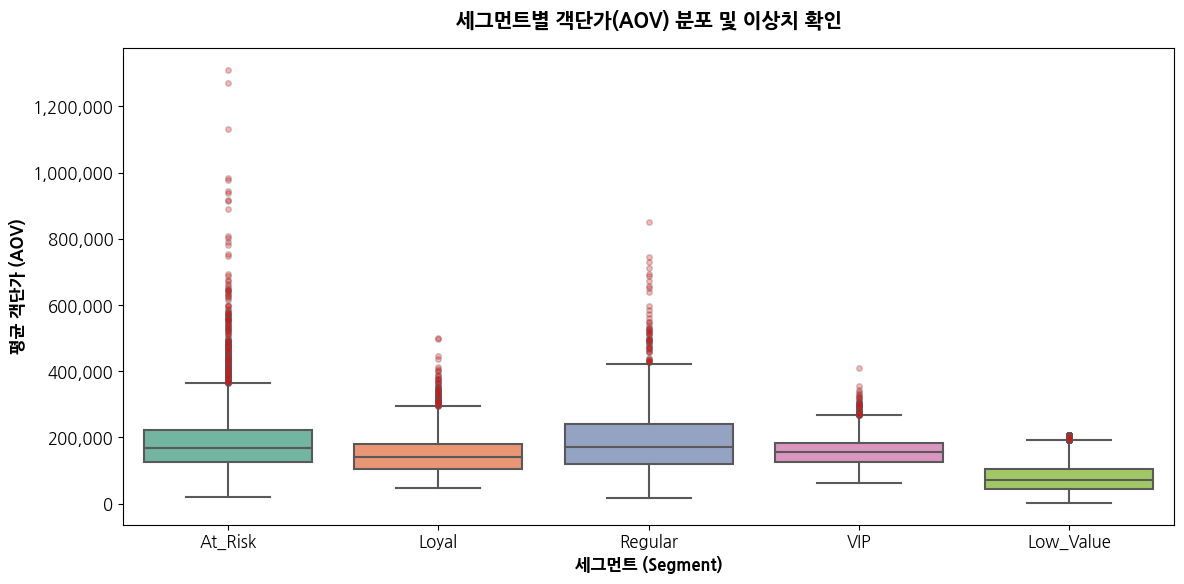

In [382]:
plot_aov_boxplot(rfm_2024_labeled[rfm_2024_labeled["segment"] != "Dormant"])

1. Regular (일반 고객)

- 특징: `전체 세그먼트 중 박스(IQR)의 위치와 중앙값(Median)이 가장 높게 형성`되어 있습니다. 중앙값이 약 18만 원 수준이며, 상위 75% 라인도 20만 원을 훌쩍 넘습니다.
- 해석: 이전 분석에서 확인했던 "결제 빈도는 낮지만 한 번 살 때 크게 결제하는 고객(Big Spender)" 들이 이곳에 여전히 많이 분포하고 있음을 객단가(AOV) 차트가 명확히 증명합니다. 최대 80만 원 이상의 이상치(Outlier)도 다수 존재합니다.

2. At_Risk (이탈 위험 고객)

- 특징: 중앙값은 15만 원 수준으로 평범하지만, `위쪽으로 뻗은 붉은색 이상치(Outlier)들이 압도적으로 높고 넓게 퍼져` 있습니다. (최대 130만 원 이상)
- 해석: `과거에 엄청나게 큰 금액을 한 번에 결제하고 그 이후로 돌아오지 않는 '이탈한 큰손' 들이 매우 많다는 것`을 의미합니다. 이들을 다시 활성화(Win-back) 시킬 수 있다면 매출에 큰 기여를 할 수 있는 핵심 타겟입니다.

3. VIP & Loyal (최우수 & 충성 고객)

- 특징: Regular에 비해 오히려 박스의 높이(중앙값)가 낮고(약 13~15만 원 선), 위아래 꼬리(Whisker)가 짧으며 이상치도 적습니다. `분포가 매우 안정적이고 밀집`되어 있습니다.
- 해석: 이 집단이 높은 총 결제액(Monetary)을 기록하는 이유는 '한 번에 엄청나게 큰 금액을 써서'가 아니라, `'적절한 금액의 상품을 꾸준히 자주 구매(높은 Frequency)'` 하기 때문입니다. 이커머스에서 가장 이상적이고 예측 가능한 수익 창출 집단입니다.

4. New & Low_Value (신규 & 저가치 고객)

- 특징: 두 세그먼트의 분포 형태가 거의 동일합니다. 중앙값이 10만 원 미만(약 7만 원 선)으로 가장 낮고 분포폭도 좁습니다.
- 해석: 신규 가입자들은 처음부터 큰돈을 쓰기보다는 저렴한 상품 위주로 '테스트 구매'를 하는 경향이 뚜렷함을 알 수 있습니다.

💡 [종합 결론 및 인사이트]
1. 객단가(AOV)의 역전 현상 확인: `상위 등급인 VIP, Loyal보다 중간 등급인 Regular의 1회 평균 결제 금액이 더 높습니다.` 이는 세그먼트가 '빈도(Frequency)'에 의해 크게 좌우되고 있음을 보여줍니다.
2. 이탈한 '큰손' 발굴 (At_Risk): At_Risk 그룹에 극단적으로 객단가가 높은 유저들이 방치되어 있습니다. `초고가 상품 구매 후 이탈한 유저들을 대상으로 한 맞춤형 리타겟팅(예: 고가 브랜드 신상품 안내, 프라이빗 할인 등) 전략이 시급`합니다.
3. Regular 내 고단가 유저 분리 필요성 확인: `Regular 세그먼트는 박스 크기가 크고 상단으로 넓게 퍼져 있어 이질적인 유저가 혼합되어 있습니다.` 여전히 빈도는 낮지만 객단가가 매우 높은 유저들을 따로 묶어 특별 관리할 필요성이 필요함을 부여하는 세분화 전략이 유효해 보입니다.

### 1.1.5. Regular(Default) 세그먼트에 포함된 이질적 특성의 고객군 분리

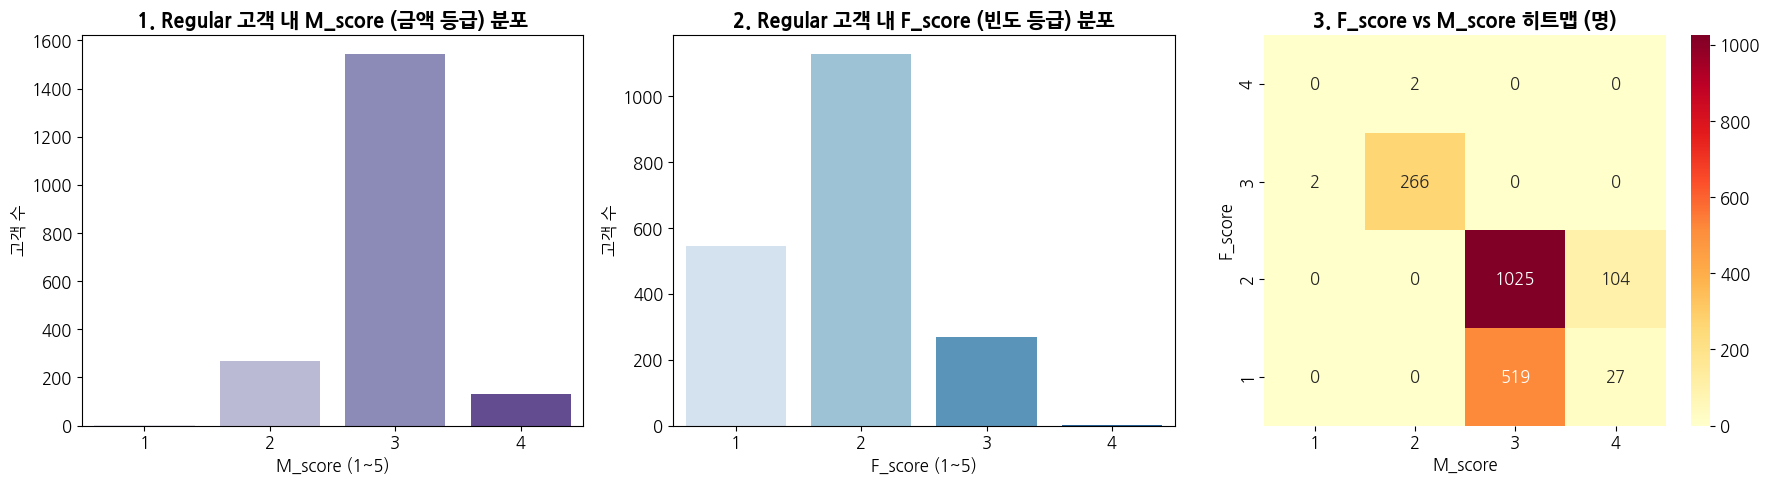

In [383]:
# 1. 기존 로직에 의해 'Regular'로 분류된 고객만 추출
# (rfm_2024_labeled는 현재 수정 전 로직이 적용된 데이터프레임이라고 가정)
regular_df = rfm_2024_labeled[rfm_2024_labeled['segment'] == 'Regular'].copy()

fig = plt.figure(figsize=(18, 5))

# --- 차트 1: Regular 그룹 내 M_score 분포 (고가치 유저가 섞여있는지 확인) ---
ax1 = plt.subplot(1, 3, 1)
sns.countplot(data=regular_df, x='M_score', palette='Purples', ax=ax1)
ax1.set_title("1. Regular 고객 내 M_score (금액 등급) 분포", fontweight='bold')
ax1.set_xlabel("M_score (1~5)")
ax1.set_ylabel("고객 수")
# 해석: 만약 M_score 4, 5에 해당하는 막대가 높게 나타난다면, "돈을 많이 쓴 고객"이 Regular에 대거 갇혀있음을 의미합니다.

# --- 차트 2: Regular 그룹 내 F_score 분포 (저빈도 유저인지 확인) ---
ax2 = plt.subplot(1, 3, 2)
sns.countplot(data=regular_df, x='F_score', palette='Blues', ax=ax2)
ax2.set_title("2. Regular 고객 내 F_score (빈도 등급) 분포", fontweight='bold')
ax2.set_xlabel("F_score (1~5)")
ax2.set_ylabel("고객 수")
# 해석: F_score 1, 2에 집중되어 있다면, "자주 안 사서 Loyal이 못 된 고객들"이라는 가설이 증명됩니다.

# --- 차트 3: F_score vs M_score 히트맵 (어떤 조합이 가장 많은가?) ---
ax3 = plt.subplot(1, 3, 3)
# F_score와 M_score의 교차표(Crosstab) 생성
fm_crosstab = pd.crosstab(regular_df['F_score'], regular_df['M_score'])

# 히트맵 시각화
sns.heatmap(fm_crosstab, annot=True, fmt='d', cmap='YlOrRd', ax=ax3, cbar=True)
ax3.set_title("3. F_score vs M_score 히트맵 (명)", fontweight='bold')
ax3.invert_yaxis() # y축이 1부터 시작하도록 뒤집기
# 해석: 히트맵에서 (F=1~2, M=4~5) 영역의 숫자가 크고 붉은색을 띤다면, 이들이 바로 Regular의 평균(ARPPU)을 끌어올린 주범인 'Big Spender'들입니다.

plt.tight_layout()
plt.show()

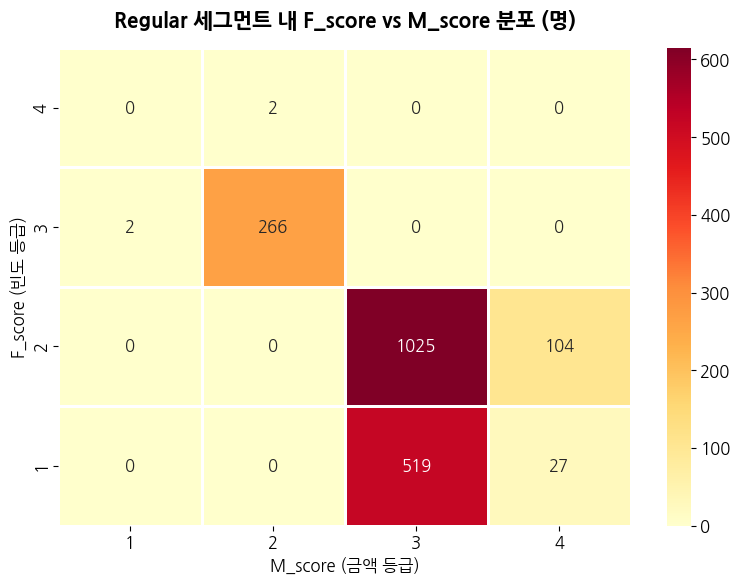

In [384]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Regular 고객 데이터 필터링
regular_df = rfm_2024_labeled[rfm_2024_labeled['segment'] == 'Regular'].copy()

# 2. F_score와 M_score의 교차표(Crosstab) 생성
fm_crosstab = pd.crosstab(regular_df['F_score'], regular_df['M_score'])

# 3. 히트맵 단독 시각화
fig, ax = plt.subplots(figsize=(8, 6))

# [핵심] 시각적 강조를 위한 색상 한도(vmax) 조절
# 1등 그룹 때문에 타겟 그룹이 묻히지 않도록, 상한선을 전체 max의 60% 수준으로 제한
max_val = fm_crosstab.values.max()
vmax_adjusted = max_val * 0.6 

sns.heatmap(
    fm_crosstab, 
    annot=True, 
    fmt='d', 
    cmap='YlOrRd', 
    ax=ax, 
    cbar=True,
    vmax=vmax_adjusted,  # 상한선 조절 적용
    linewidths=1,        # 각 셀 사이에 흰색 테두리를 넣어 깔끔하게 분리
    linecolor='white'
)

ax.set_title("Regular 세그먼트 내 F_score vs M_score 분포 (명)", fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("M_score (금액 등급)", fontsize=12)
ax.set_ylabel("F_score (빈도 등급)", fontsize=12)
ax.invert_yaxis() # y축이 1부터 직관적으로 올라가도록 뒤집기

plt.tight_layout()
plt.show()

[차트 1] M_score (금액 등급) 분포

- M_score = 3인 고객이 약 1,500명으로 가장 많은 비중을 차지하고 있습니다.
- 결제액 상위 20~40%에 해당하는 M_score = 4인 고과금 유저도 약 150명 정도 섞여 있는 것으로 나타납니다.

[차트 2] F_score (빈도 등급) 분포

- 대부분의 고객이 F_score = 2 (약 1,100명)에 집중되어 있으며, F_score = 1 (약 550명), F_score = 3 (약 250명) 순으로 분포합니다.
- M Score = 4인 고객이 VIP나 Loyal 세그먼트(F>=3 필요)로 승급하지 못하고 Regular에 갇힘.

[차트 3] F_score vs M_score 히트맵

- (M=3, F=2): 1,025명 (가장 많음) -> 적당한 빈도와 중간 수준의 금액을 결제한 전형적인 Regular 고객층
- (M=3, F=3): 266명 -> 빈도는 어느 정도 되지만 결제 단가가 상대적으로 평범한 고객
- (M=3, F=1): 519명 -> 빈도는 낮지만 한 번에 꽤 높은 금액(M=3)을 결제한 고객
- (M=4, F=2): 104명, (M=4, F=1): 27명 -> 🚨 주의가 필요한 집단!
- "구매 빈도는 1~2회로 낮지만, 결제액 합은 높은(M=3~4) 성향을 가진 고객이 여전히 약 650명 이상 Regular에 잔존"하고 있습니다.

**[Regular 에서 분리할 (M=3, F=1), (M=4, F=2), (M=4, F=1) 고객의 Recency 분포]**

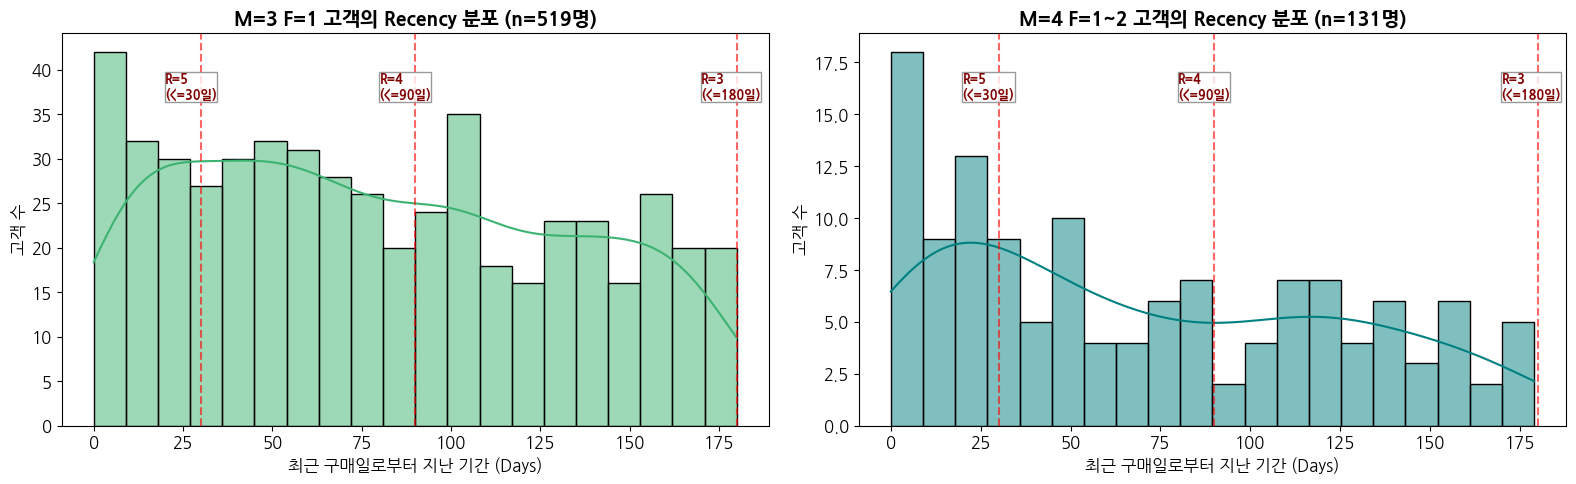

In [385]:
# 1. 대상 타겟 조건 설정 (M=3&F=1, M=4&F=2, M=4&F=1)
target_cond = (rfm_2024_labeled["segment"] == "Regular") & (
              ((rfm_2024_labeled["M_score"] == 3) & (rfm_2024_labeled["F_score"] == 1)) | \
              ((rfm_2024_labeled["M_score"] == 4) & (rfm_2024_labeled["F_score"] == 2)) | \
              ((rfm_2024_labeled["M_score"] == 4) & (rfm_2024_labeled["F_score"] == 1))
              )

potential_candidates = rfm_2024_labeled[target_cond]

# M=3, M=4 그룹 분리
m3_group = potential_candidates[potential_candidates["M_score"] == 3]
m4_group = potential_candidates[potential_candidates["M_score"] == 4]

# --- R_score 고정 구간 경계값 및 라벨 정의 ---
# 365일 초과(0점)는 히스토그램 범위 상 보통 무시되므로 경계선에서 제외했습니다.
fixed_bounds = [
    {"bound": 30, "label": "R=5\n(<=30일)"},
    {"bound": 90, "label": "R=4\n(<=90일)"},
    {"bound": 180, "label": "R=3\n(<=180일)"},
]

# 2. 시각화 설정 (1행 2열)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ==========================================================
# [차트 1] M=3 그룹의 Recency(Days) 히스토그램
# ==========================================================
sns.histplot(m3_group['recency_days'], bins=20, kde=True, color='mediumseagreen', ax=axes[0])
axes[0].set_title(f"M=3 F=1 고객의 Recency 분포 (n={len(m3_group)}명)", fontweight='bold', fontsize=14)
axes[0].set_xlabel("최근 구매일로부터 지난 기간 (Days)", fontsize=12)
axes[0].set_ylabel("고객 수", fontsize=12)

min_r_m3 = m3_group['recency_days'].min()
y_max_1 = axes[0].get_ylim()[1]

# 분포의 min보다 큰 경계값만 세로선 추가
for item in fixed_bounds:
    b_val = item["bound"]
    b_label = item["label"]
    
    if b_val > min_r_m3:
        axes[0].axvline(x=b_val, color='red', linestyle='--', alpha=0.6)
        axes[0].text(
            x=b_val - 10, 
            y=y_max_1 * 0.9, 
            s=b_label, 
            color='maroon', 
            ha='left', 
            va='top', 
            fontsize=9, 
            fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', pad=0.3)
        )

# ==========================================================
# [차트 2] M=4 그룹의 Recency(Days) 히스토그램
# ==========================================================
sns.histplot(m4_group['recency_days'], bins=20, kde=True, color='teal', ax=axes[1])
axes[1].set_title(f"M=4 F=1~2 고객의 Recency 분포 (n={len(m4_group)}명)", fontweight='bold', fontsize=14)
axes[1].set_xlabel("최근 구매일로부터 지난 기간 (Days)", fontsize=12)
axes[1].set_ylabel("고객 수", fontsize=12)

min_r_m4 = m4_group['recency_days'].min()
y_max_2 = axes[1].get_ylim()[1]

# 분포의 min보다 큰 경계값만 세로선 추가
for item in fixed_bounds:
    b_val = item["bound"]
    b_label = item["label"]
    
    if b_val > min_r_m4:
        axes[1].axvline(x=b_val, color='red', linestyle='--', alpha=0.6)
        axes[1].text(
            x=b_val - 10, 
            y=y_max_2 * 0.9, 
            s=b_label, 
            color='maroon', 
            ha='left', 
            va='top', 
            fontsize=9, 
            fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', pad=0.3)
        )

plt.tight_layout()
plt.show()

- 두 그룹 모두 최근 유입(R=5, 30일 이내) 비중이 가장 높음. 또한, Recency가 악화될수록 분포하는 고객의 수가 줄어듬. 즉, '활성 상태의 유망주'가 주로 분포함.
- 해당 고객들은 낮은 빈도로 높은 구매 금액을 달성한 고객이 VIP, Loyal에 속하지 못하고 Regular(Default)에 속했다고 볼 수 있음.
- **따라서, (M=3, F=1), (M=4, F=2), (M=4, F=1) 인 고객 약 650여 명을 Regular에서 분리하여 Potential(잠재적 고가치 고객군)이라는 신규 세그먼트로 독립**
- VIP로 육성하기 위한 특별 CRM(재구매 유도 할인 등)을 가동하거나, 최소한 Regular 그룹의 평균을 오염시키지 않도록 분리

### 1.1.6. 최종 RFM 세그먼트 분류 및 EDA

In [386]:
def label_rfm_segments(scored_df: pd.DataFrame) -> pd.DataFrame:
    out = scored_df.copy()

    # 1. Dormant: 이탈/휴면 (분석 기간 내 구매 이력 없음)
    dormant_cond = (out["RFM_sum"] == 0)

    # 2. VIP: 최상위 핵심 고객 (R, F, M 모두 최상위권)
    vip_cond = (out["R_score"] >= 4) & (out["F_score"] >= 4) & (out["M_score"] >= 4)

    # 3. Loyal: 충성/반복 구매 고객 (VIP에는 못 미치나 꾸준한 구매)
    loyal_cond = (out["R_score"] >= 3) & (out["F_score"] >= 3) & (out["M_score"] >= 3)

    # 4. At_Risk: 이탈 위험군 (과거에 자주/많이 샀으나 최근 발길이 끊김)
    # F나 M이 우수(3 이상)했던 고객 중 최근성(R)이 위험 수준(2 이하)인 타겟
    at_risk_cond = (out["R_score"] <= 2) & ((out["F_score"] >= 3) | (out["M_score"] >= 3))

    # 5. Potential: 잠재적 고가치 고객군 (빈도는 낮으나 결제 금액이 높음)
    # (M=3, F=1)이거나 (M>=4, F<=2) 인 고객
    potential_cond = ((out["M_score"] == 3) & (out["F_score"] == 1)) | ((out["M_score"] >= 4) & (out["F_score"] <= 2))
    
    # 6. Low_Value: 하위 고객 (낮은 빈도로 소액 구매)
    low_value_cond = (out["F_score"] <= 2) & (out["M_score"] <= 2)

    conditions = [
        dormant_cond, 
        vip_cond, 
        loyal_cond, 
        at_risk_cond, 
        potential_cond,
        low_value_cond
    ]
    choices = [
        "Dormant", 
        "VIP", 
        "Loyal", 
        "At_Risk", 
        "Potential",
        "Low_Value"
    ]

    # 8. Regular: 위 조건에 모두 해당하지 않는 중간 집단 (Default)
    out["segment"] = np.select(conditions, choices, default="Regular")
    
    return out

In [387]:
# rfm_df는 이전 단계에서 산출된 DataFrame
rfm_2024_labeled = label_rfm_segments(rfm_2024_scored)

# 결과 확인
display(rfm_2024_labeled[[
    "user_id", "days_since_signup", "recency_days", "frequency", "monetary", "aov_user",
    "R_score", "F_score", "M_score", "RFM_score", "RFM_sum", "segment"
]].head())

,user_id,days_since_signup,recency_days,frequency,monetary,aov_user,R_score,F_score,M_score,RFM_score,RFM_sum,segment
0,1,467,327,2,258250.0,129125.00,1,2,3,123,6,At_Risk
1,2,425,223,10,1817400.0,181740.00,2,5,5,255,12,At_Risk
2,3,417,1364,0,0.0,0.00,0,0,0,000,0,Dormant
3,4,114,1364,0,0.0,0.00,0,0,0,000,0,Dormant
4,5,373,110,11,1691780.0,153798.18,3,5,5,355,13,Loyal


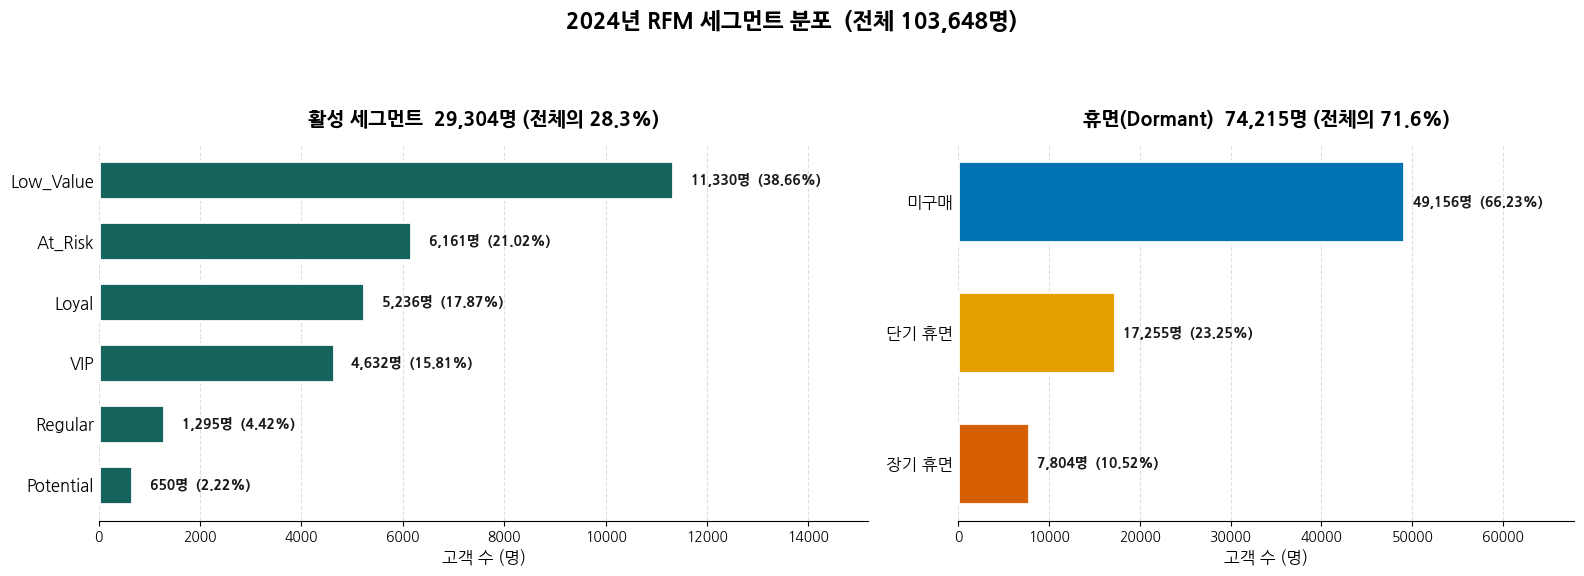

※ 각 패널의 (%)는 '패널 내 비중'입니다 — 좌측은 활성 합계 대비, 우측은 휴면 합계 대비.


In [ ]:
# =====================================================================================
# [차트] 2024년 세그먼트 분포 — Dormant 분리 + 3분해
#
# [요약]
#   (1) 활성 고객과 휴면 고객을 좌/우 패널로 분리하여 활성 세그먼트의 상대 크기를 시각화함.
#   (2) 오른쪽 패널에서 Dormant를 '미구매 / 단기 휴면 / 장기 휴면' 3유형으로 분해.
#       세 집단은 필요한 액션(Activation / Winback / 제외)이 서로 달라, 하나의 막대로
#       묶으면 "휴면 71.7%"라는 수치에서 어떤 개선 과제도 도출할 수 없음.
#   (3) 세그먼트명이 길어 x축 라벨이 서로 겹칠 우려가 있어 가로 막대 채택.
# =====================================================================================

AS_OF_2024 = pd.Timestamp("2024-12-31")
PAID_STATUSES_ = {"Completed", "Processing"}
DT_ORDER = ["미구매", "단기 휴면", "장기 휴면"]
DT_COLOR = {"미구매": "#0072B2", "단기 휴면": "#E69F00", "장기 휴면": "#D55E00"}

# ---- 전체 주문 이력 기반 recency ------------------------------------------------------
_o = orders_enriched.copy()
_o["created_at"] = pd.to_datetime(_o["created_at"], errors="coerce")
if "status" in _o.columns:
    _o = _o[_o["status"].isin(PAID_STATUSES_)]
_span = (_o.dropna(subset=["user_id", "created_at"])
           .groupby("user_id", as_index=False)
           .agg(first_all=("created_at", "min"), last_all=("created_at", "max")))

_d = rfm_2024_labeled[["user_id", "segment"]].merge(_span, on="user_id", how="left")
_d["rec_all"] = (AS_OF_2024 - _d["last_all"]).dt.days
_isd = _d["segment"].eq("Dormant")
_d["seg2"] = np.select(
    [~_isd,
     _isd & (_d["last_all"].isna() | (AS_OF_2024 < _d["first_all"])),
     _isd & _d["rec_all"].between(366, 730),
     _isd & (_d["rec_all"] > 730)],
    [_d["segment"], "미구매", "단기 휴면", "장기 휴면"],
    default="기타",
)

TOTAL = len(_d)
active = (_d.loc[~_isd, "seg2"].value_counts().sort_values())
dorm = (_d.loc[_isd, "seg2"].value_counts().reindex(DT_ORDER).fillna(0).astype(int))

ACTIVE_SUM, DORM_SUM = active.sum(), dorm.sum()

fig, axes = plt.subplots(1, 2, figsize=fig_size(5.8, plot_w=FIG_W_2PANE, legends=0),
                         gridspec_kw={"width_ratios": [1.25, 1]})

# ---- (좌) 활성 세그먼트 : 분모 = 활성 합계 -------------------------------------------
ax = axes[0]
ax.barh(active.index, active.values, color="#14635D", height=0.62, **bar_style())
for i, v in enumerate(active.values):
    ax.text(v + ACTIVE_SUM * 0.012, i, f"{v:,}명  ({v/ACTIVE_SUM*100:.2f}%)",
            va="center", fontsize=FS_LABEL + 1, fontweight="bold", color=ink(True))
ax.set_xlim(0, active.max() * 1.34)
finalize(ax, f"활성 세그먼트  {ACTIVE_SUM:,}명 (전체의 {ACTIVE_SUM/TOTAL*100:.1f}%)",
         "고객 수 (명)", None, panel=True, legend=False, grid_axis="x")
ax.tick_params(axis="y", length=0, labelsize=FS_AXIS)

# ---- (우) 휴면 3분해 : 분모 = 휴면 합계 ------------------------------------------------
ax = axes[1]
_rev = DT_ORDER[::-1]
ax.barh(_rev, dorm[_rev].values, color=[DT_COLOR[k] for k in _rev], height=0.62, **bar_style())
for i, k in enumerate(_rev):
    ax.text(dorm[k] + DORM_SUM * 0.012, i, f"{dorm[k]:,}명  ({dorm[k]/DORM_SUM*100:.2f}%)",
            va="center", fontsize=FS_LABEL + 1, fontweight="bold", color=ink(True))
ax.set_xlim(0, dorm.max() * 1.38)
finalize(ax, f"휴면(Dormant)  {DORM_SUM:,}명 (전체의 {DORM_SUM/TOTAL*100:.1f}%)",
         "고객 수 (명)", None, panel=True, legend=False, grid_axis="x")
ax.tick_params(axis="y", length=0, labelsize=FS_AXIS)

fig.suptitle(f"2024년 RFM 세그먼트 분포  (전체 {TOTAL:,}명)",
             fontsize=FS_TITLE, fontweight="bold", y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

print("※ 각 패널의 (%)는 '패널 내 비중'입니다 — 좌측은 활성 합계 대비, 우측은 휴면 합계 대비.")


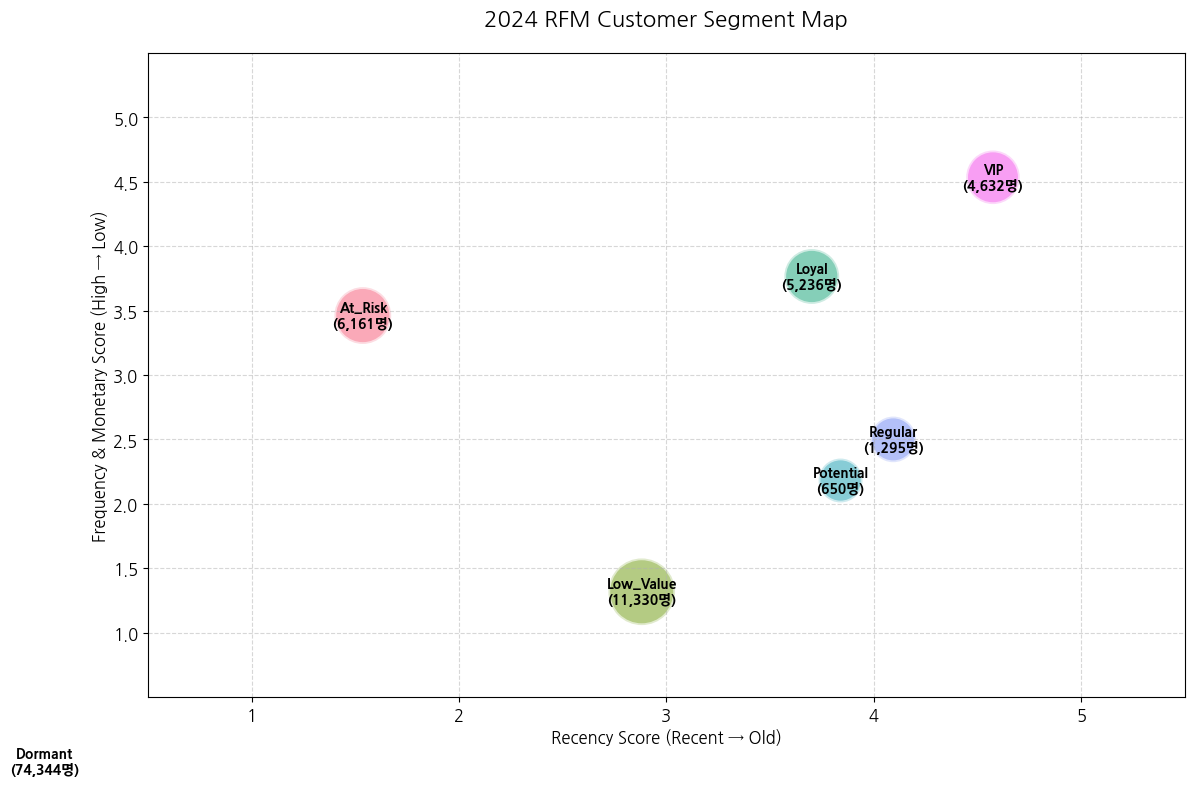

In [392]:
# 1. FM_score 생성 (Frequency와 Monetary의 평균 활용)
# 이미지의 Y축인 'Frequency & Monetary score'를 구현하기 위함입니다.
rfm_2024_labeled['FM_score'] = (rfm_2024_labeled['F_score'] + rfm_2024_labeled['M_score']) / 2

# 2. 시각화를 위한 세그먼트별 요약 통계 계산
# 각 세그먼트의 중심 좌표(평균)와 고객 수(Size)를 구합니다.
segment_map = rfm_2024_labeled.groupby('segment').agg({
    'R_score': 'mean',
    'FM_score': 'mean',
    'user_id': 'count'
}).reset_index()

# 3. 시각화 설정
plt.figure(figsize=(12, 8))
# sns.set_style("whitegrid")

# 컬러 팔레트 설정 (포트폴리오 톤앤매너에 맞춰 수정 가능)
colors = sns.color_palette("husl", len(segment_map['segment']))

# 4. 세그먼트 위치 산점도 그리기
# 점의 크기(s)를 고객 수에 비례하게 설정하여 규모감을 표현합니다.
scatter = sns.scatterplot(
    data=segment_map, 
    x='R_score', 
    y='FM_score', 
    hue='segment', 
    size='user_id', 
    sizes=(1000, 10000), # 원의 최소/최대 크기
    palette=colors,
    legend=False,
    alpha=0.6
)

# 5. 각 원의 중심에 세그먼트 이름과 고객 수 라벨링
for i in range(segment_map.shape[0]):
    plt.text(
        x=segment_map.R_score[i], 
        y=segment_map.FM_score[i], 
        s=f"{segment_map.segment[i]}\n({segment_map.user_id[i]:,}명)",
        fontdict={'size': 10, 'weight': 'bold'},
        ha='center', va='center'
    )

# 6. 축 및 레이아웃 설정
plt.title('2024 RFM Customer Segment Map', fontsize=16, pad=20)
plt.xlabel('Recency Score (Recent → Old)', fontsize=12)
plt.ylabel('Frequency & Monetary Score (High → Low)', fontsize=12)
plt.xticks(range(1, 6))
plt.yticks(np.arange(1, 5.5, 0.5))
plt.grid(True, linestyle='--', alpha=0.5)

# 축 방향 반전 (이미지와 동일하게 최근성 점수가 높을수록 오른쪽, FM 점수가 높을수록 위쪽)
plt.xlim(0.5, 5.5)
plt.ylim(0.5, 5.5)

plt.tight_layout()
plt.show()


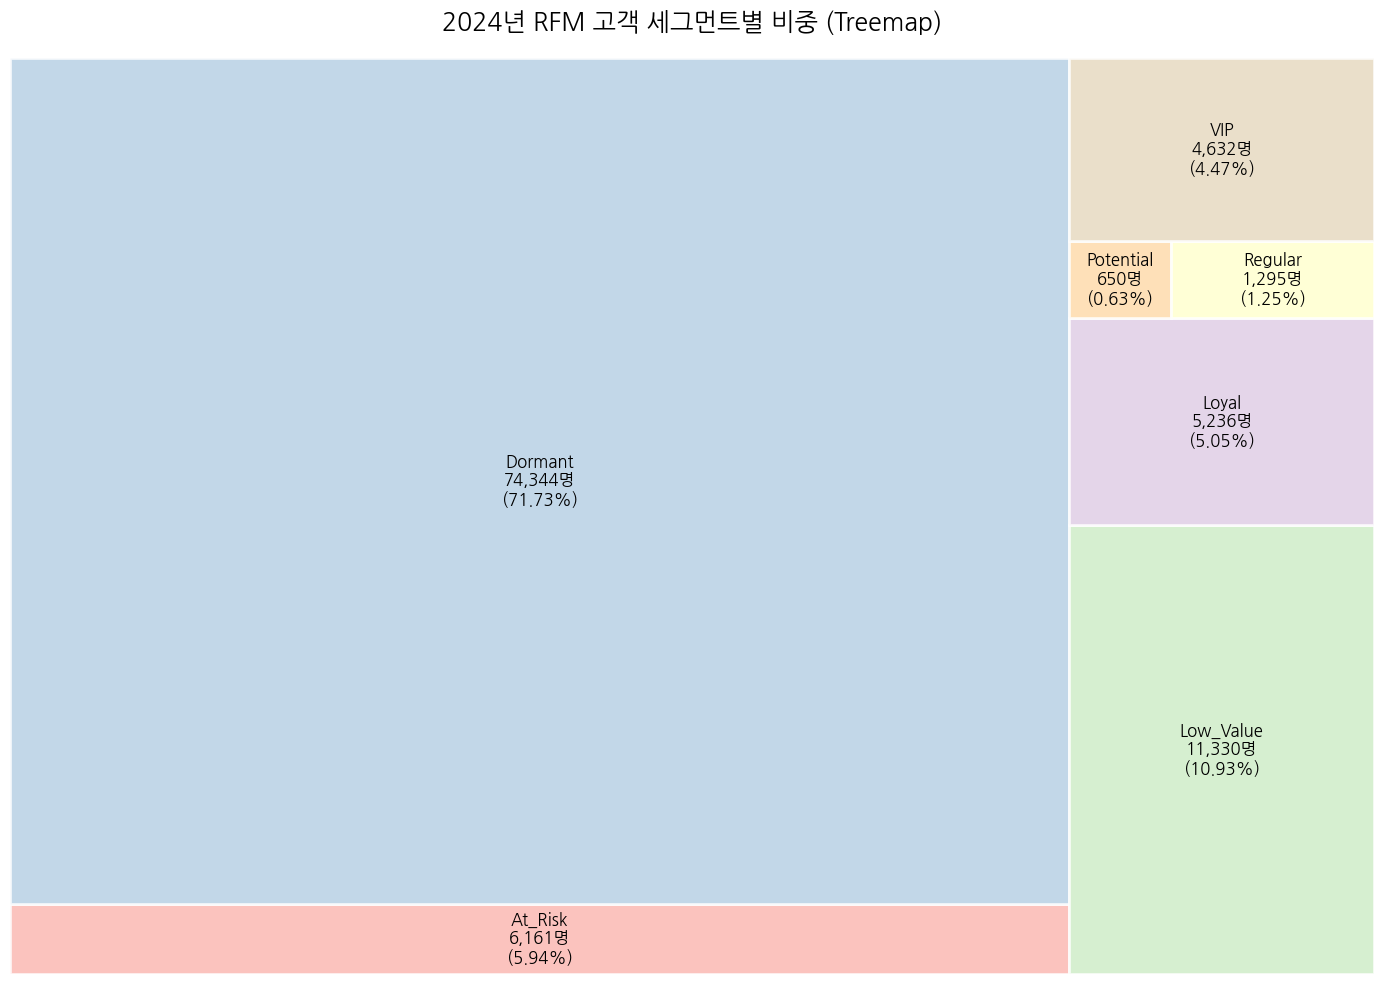

In [396]:
# 1. 시각화를 위한 데이터 요약
# 각 세그먼트별 고객 수와 비중 계산
df_tree = rfm_2024_labeled.groupby('segment').size().reset_index(name='counts')
df_tree['percentage'] = (df_tree['counts'] / df_tree['counts'].sum() * 100).round(2)

# 2. 시각화 설정
plt.figure(figsize=(14, 10))
plt.rcParams['font.family'] = font_name

# 라벨 생성 (세그먼트 명 + 고객 수 + 비중)
labels = [f"{row['segment']}\n{row['counts']:,}명\n({row['percentage']}%)" for _, row in df_tree.iterrows()]
colors = plt.cm.Pastel1(range(len(df_tree)))

# 3. 트리맵 그리기
squarify.plot(sizes=df_tree['counts'], label=labels, color=colors, alpha=0.8, edgecolor="white", linewidth=2)

plt.title('2024년 RFM 고객 세그먼트별 비중 (Treemap)', fontsize=18, pad=20)
plt.axis('off') # 축 제거
plt.tight_layout()
plt.show()

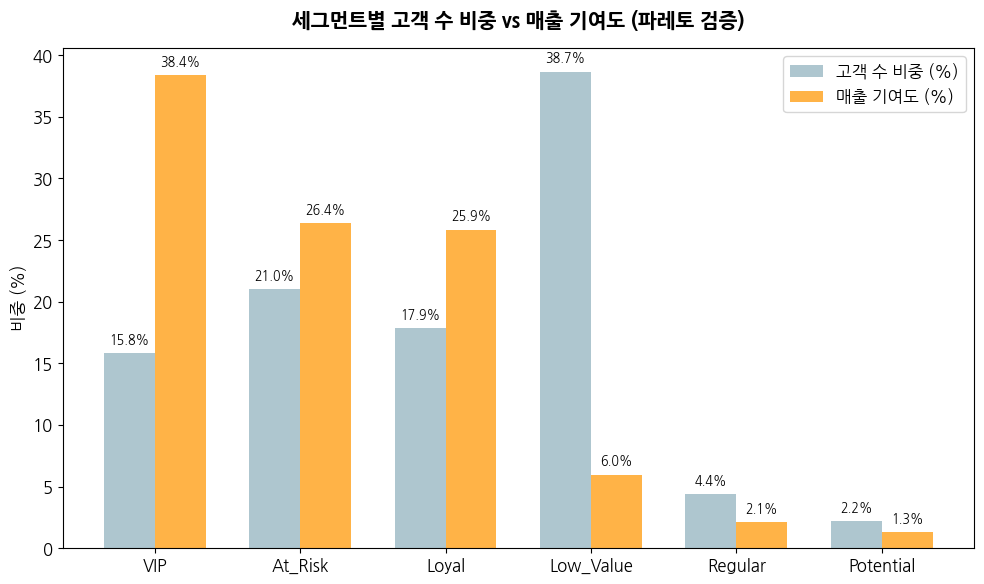

In [397]:
contribution_stats = plot_segment_contribution(rfm_2024_labeled[rfm_2024_labeled["segment"] != "Dormant"])

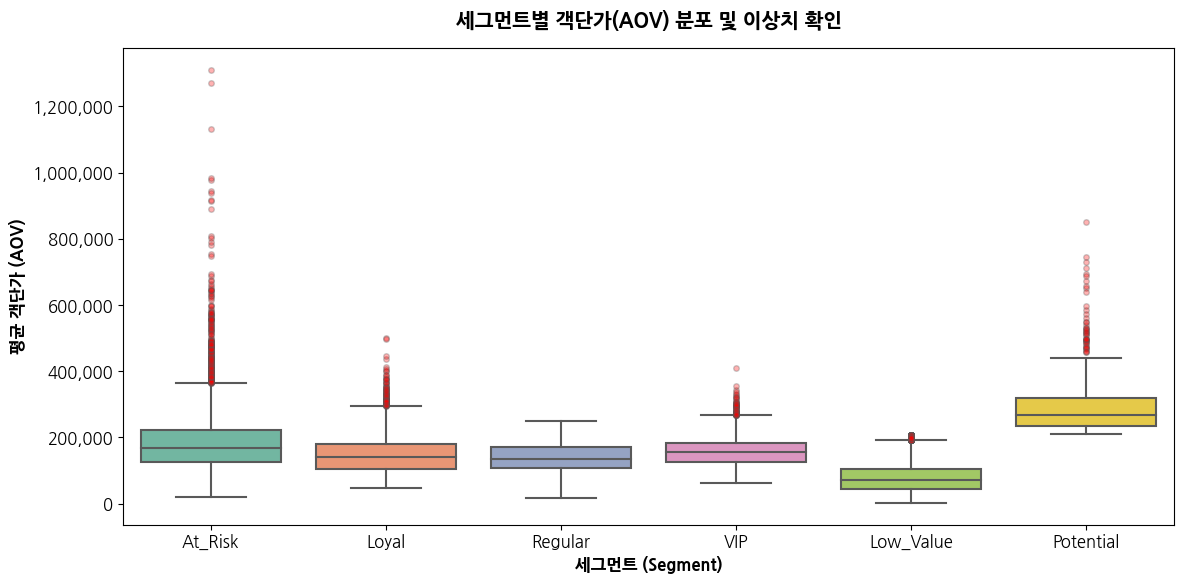

In [398]:
plot_aov_boxplot(rfm_2024_labeled[rfm_2024_labeled["segment"] != "Dormant"])

## 1.2. 세그먼트 간 이질성 검증

**세그먼트가 잘 나누어졌다면, 그룹 간의 Recency, Frequency, Monetary 평균값은 통계적으로 유의미한 차이를 보여야 함.**

### 1.2.1. 시각적 분포 확인

- **위에서 확인했듯, R, F, M score 모두 0인 휴면 고객군(Dormant)의 비중이 다른 고객군에 비해 압도적으로 높아, 세그먼트 그룹간 이질정 검정 과정에서 Dormant 제외**

In [401]:
target_df = rfm_2024_labeled[rfm_2024_labeled['segment'] != 'Dormant'].copy()

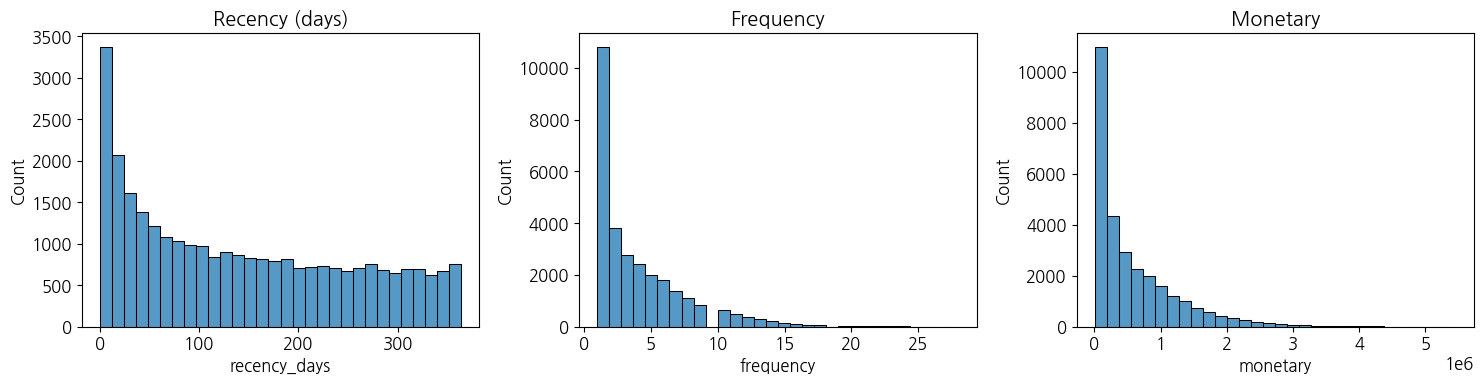

In [402]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(target_df["recency_days"], bins=30, kde=False, ax=axes[0])
axes[0].set_title("Recency (days)")

sns.histplot(target_df["frequency"], bins=30, kde=False, ax=axes[1])
axes[1].set_title("Frequency")

sns.histplot(target_df["monetary"], bins=30, kde=False, ax=axes[2])
axes[2].set_title("Monetary")

plt.tight_layout()
plt.show()

- **세 지표 모두 낮은 값에 치중되어 있는 Long tail 형태의 분포를 가짐.**

**[로그 변환 분포 확인]**

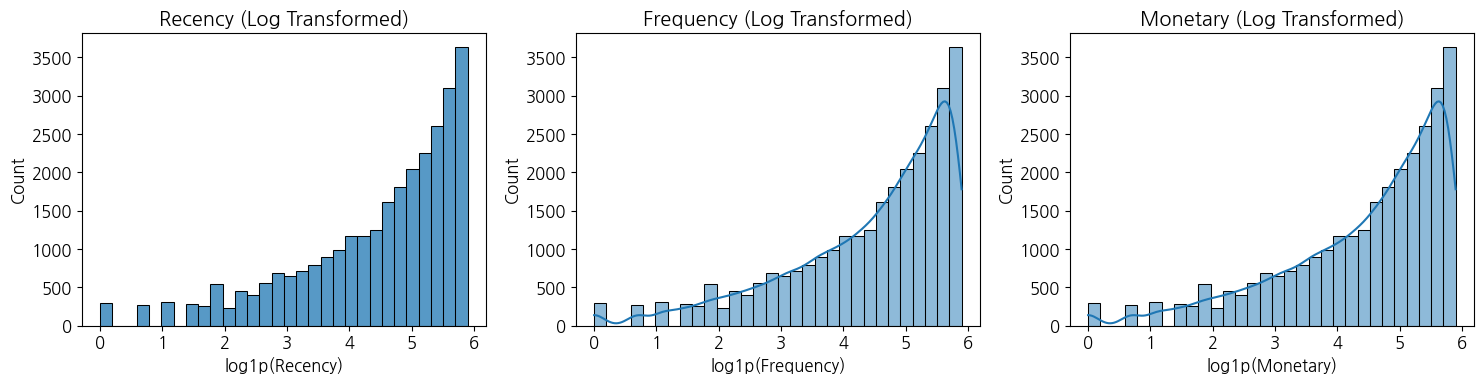

In [403]:
target_df['recency_log'] = np.log(target_df['recency_days'])
target_df['frequency_log'] = np.log(target_df['frequency'])
target_df['monetary_log'] = np.log(target_df['monetary'])

# 1행 2열 서브플롯 생성
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(target_df["recency_log"], bins=30, kde=False, ax=axes[0])
axes[0].set_title("Recency (Log Transformed)")
axes[0].set_xlabel("log1p(Recency)")

sns.histplot(target_df['recency_log'], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Frequency (Log Transformed)")
axes[1].set_xlabel("log1p(Frequency)")

sns.histplot(target_df['recency_log'], bins=30, kde=True, ax=axes[2])
axes[2].set_title("Monetary (Log Transformed)")
axes[2].set_xlabel("log1p(Monetary)")

plt.tight_layout()
plt.show()

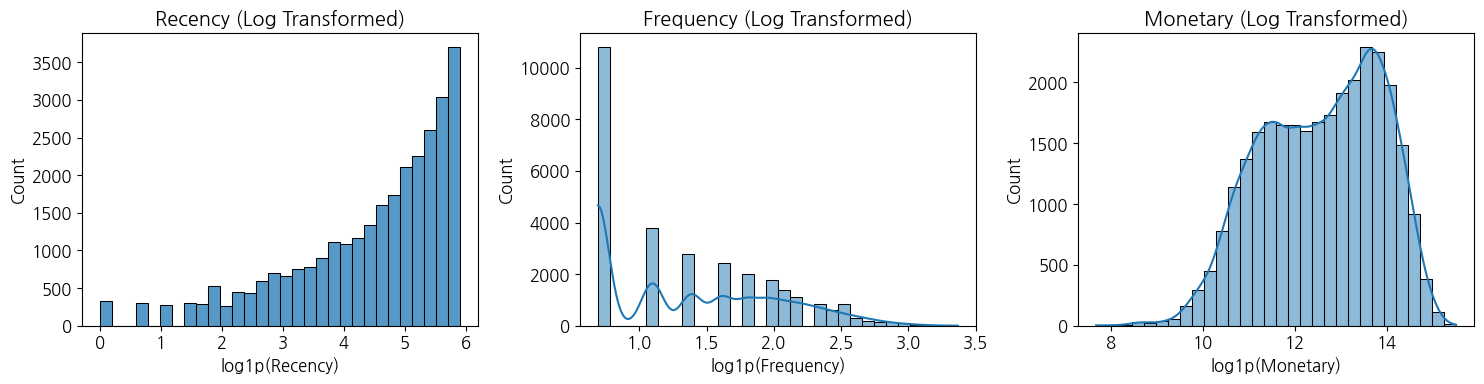

In [404]:
target_df['recency_log1p'] = np.log1p(target_df['recency_days'])
target_df['frequency_log1p'] = np.log1p(target_df['frequency'])
target_df['monetary_log1p'] = np.log1p(target_df['monetary'])

# 1행 2열 서브플롯 생성
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(target_df["recency_log1p"], bins=30, kde=False, ax=axes[0])
axes[0].set_title("Recency (Log Transformed)")
axes[0].set_xlabel("log1p(Recency)")

sns.histplot(target_df['frequency_log1p'], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Frequency (Log Transformed)")
axes[1].set_xlabel("log1p(Frequency)")

sns.histplot(target_df['monetary_log1p'], bins=30, kde=True, ax=axes[2])
axes[2].set_title("Monetary (Log Transformed)")
axes[2].set_xlabel("log1p(Monetary)")

plt.tight_layout()
plt.show()

- Monetary: log(x+1) 변환한 분포의 경우, 왼쪽 꼬리가 약간 있지만 전반적으로 정규분포에 근사한 형태를 띔.
- Recency, Frequency: 두 지표에 대한 분포의 경우, 정규분포의 형태를 띄지 않기 때문에, 비모수 검정(Kruskal-Wallis)을 사용.

### 1.2.2. Recency: 세그먼트간 이질성 통계적 검증

#### Kruskal-Wallis

- 비모수 검정은 데이터의 '실제 값(평균/분산)'을 무시하고, 데이터를 한 줄로 세운 뒤 '순위(Rank)'만을 가지고 비교하는 검정법.
    - 예를들어, VIP (3명): 2일, 5일, 100일 (평균 = 35.6일) / New (3명): 10일, 12일, 15일 (평균 = 12.3일) 일때,
    - ANOVA의 경우, VIP 평균은 35.6일이고 New는 12.3일을 봄, VIP 그룹이 더 최근에 방문했음에도 이상치의 영향을 크게 받음.
    - Kruskal-Wallis H-test는 2일(VIP: 1등), 5일(VIP: 2등), 10일(New: 3등), 12일(New: 4등), 15일(New: 5등), 100일(VIP: 6등)
    - 그룹별로 '등수의 평균(Mean Rank)' 계산 → VIP 등수 평균: (1 + 2 + 6) / 3 = 3등, New 등수 평균: (3 + 4 + 5) / 3 = 4등

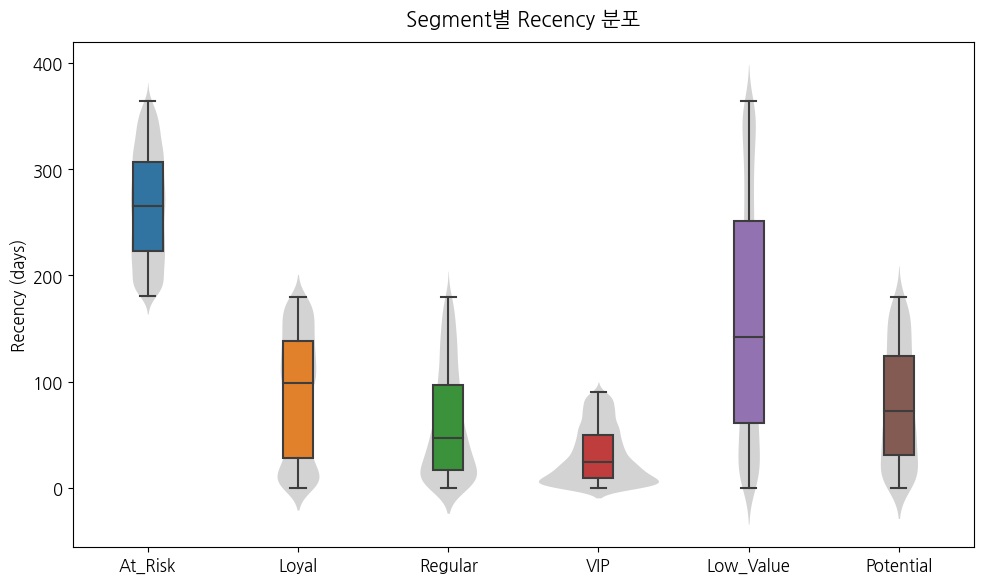

In [405]:
# 한글 폰트 및 마이너스 깨짐 방지 (필요시 주석 해제)
# plt.rcParams['font.family'] = 'AppleGothic'  # Mac
# plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(10, 6))

# 1. Recency 바이올린 플롯 (분포 모양)
sns.violinplot(
    data=target_df, 
    x="segment", 
    y="recency_days", 
    color="lightgray", 
    inner=None, 
    linewidth=0,
    alpha=0.6
)

# 2. Recency 박스 플롯 (분산, 이상치 확인)
sns.boxplot(
    data=target_df, 
    x="segment", 
    y="recency_days", 
    width=0.2, 
    boxprops={'zorder': 2}, 
    fliersize=3
)

plt.title("Segment별 Recency 분포", fontsize=15, pad=12)
plt.xlabel(None)
plt.ylabel("Recency (days)", fontsize=12)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [406]:
def perform_kruskal_wallis(df: pd.DataFrame, target_col: str, segment_col: str = 'segment') -> float:
    """
    비모수 전체 검정 (Kruskal-Wallis H-test)을 수행하고 p-value를 반환합니다.
    (이상치에 영향을 받지 않고 순위 기반으로 그룹 간 차이를 검증)
    """
    print(f"========== [{target_col}] Kruskal-Wallis H-test ==========\n")
    
    # 1. GroupBy를 활용한 데이터 분리 (결측치 제거)
    groups = [group[target_col].dropna().values for _, group in df.groupby(segment_col)]
    
    # 2. 검정 수행
    h_stat, p_val = stats.kruskal(*groups)
    
    print(f"H-statistic = {h_stat:.4f}, p-value = {p_val:.4e}")
    
    if p_val < 0.05:
        print("-> p-value < 0.05 이므로, 적어도 한 세그먼트는 통계적으로 유의미한 순위(값) 차이를 보입니다.")
    else:
        print("-> p-value >= 0.05 이므로, 세그먼트 간 유의미한 차이가 발견되지 않았습니다.")
        
    return p_val

In [407]:
p_val_recency = perform_kruskal_wallis(target_df, 'recency_days')

========== [recency_days] Kruskal-Wallis H-test ==========

H-statistic = 14422.1287, p-value = 0.0000e+00
-> p-value < 0.05 이므로, 적어도 한 세그먼트는 통계적으로 유의미한 순위(값) 차이를 보입니다.


- $H_0(귀무가설)$ 기각. 세그먼트 간 평균의 차이가 있음.

#### Dunn's Test (비모수 사후 검정)

- Kruskal-Wallis에서 구해놓은 전체 순위(Rank) 정보를 기반으로, 1:1 짝궁끼리 등수 차이가 유의미한지 계산.
- 1:1로 여러 번 비교하면 1종 오류(FWER)가 폭발하므로, Dunn's test를 수행할 때는 반드시 p-value 보정(p_adjust='bonferroni' 또는 'holm')을 설정해야 함.

In [408]:
def perform_dunn_posthoc(df: pd.DataFrame, target_col: str, segment_col: str = 'segment', p_val: float = None, alpha: float = 0.05):
    """
    Kruskal-Wallis 검정 결과가 유의미할 때 수행하는 사후 검정 (Dunn's Test).
    Bonferroni 보정을 적용하여 다중 검정의 1종 오류를 통제합니다.
    """
    print(f"\n========== [{target_col}] Dunn's Post-hoc Test ==========\n")
    
    # p_val이 전달되지 않았다면 내부적으로 한 번 수행
    if p_val is None:
        p_val = perform_kruskal_wallis(df, target_col, segment_col)
        
    if p_val >= alpha:
        print(f"전체 검정 p-value({p_val:.4f})가 {alpha} 이상이므로 사후 검정을 진행하지 않습니다.")
        return
        
    # Dunn's test 수행 (p-value 보정 방식: bonferroni)
    posthoc_res = sp.posthoc_dunn(df, val_col=target_col, group_col=segment_col, p_adjust='bonferroni')
    
    print("--- 1. 보정된 p-value 행렬 ---")
    display(posthoc_res.round(4))
    
    print("\n--- 2. 유의미한 차이가 있는 쌍 (True = 통계적 차이 있음) ---")
    # alpha보다 작으면 True(기각)를 반환하는 불리언 데이터프레임
    reject_df = posthoc_res < alpha
    display(reject_df)
    
    print("\n* 해석 가이드:")
    print(f"  - 행렬의 값이 {alpha}보다 작은(True로 표시된) 쌍이 서로 통계적으로 유의미한 차이가 있는 세그먼트입니다.")
    print("  - 실제 누가 더 크고 작은지(방향성)는 각 그룹의 중앙값(Median)이나 원본 시각화(Boxplot 등)를 보고 판단해야 합니다.")

In [409]:
perform_dunn_posthoc(target_df, 'recency_days', p_val=p_val_recency)


========== [recency_days] Dunn's Post-hoc Test ==========

--- 1. 보정된 p-value 행렬 ---


,At_Risk,Low_Value,Loyal,Potential,Regular,VIP
At_Risk,1.0,0.0,0.0000,0.0000,0.0000,0.0
Low_Value,0.0,1.0,0.0000,0.0000,0.0000,0.0
Loyal,0.0,0.0,1.0000,0.6949,0.0000,0.0
Potential,0.0,0.0,0.6949,1.0000,0.0002,0.0
Regular,0.0,0.0,0.0000,0.0002,1.0000,0.0
VIP,0.0,0.0,0.0000,0.0000,0.0000,1.0



--- 2. 유의미한 차이가 있는 쌍 (True = 통계적 차이 있음) ---


,At_Risk,Low_Value,Loyal,Potential,Regular,VIP
At_Risk,False,True,True,True,True,True
Low_Value,True,False,True,True,True,True
Loyal,True,True,False,False,True,True
Potential,True,True,False,False,True,True
Regular,True,True,True,True,False,True
VIP,True,True,True,True,True,False



* 해석 가이드:
  - 행렬의 값이 0.05보다 작은(True로 표시된) 쌍이 서로 통계적으로 유의미한 차이가 있는 세그먼트입니다.
  - 실제 누가 더 크고 작은지(방향성)는 각 그룹의 중앙값(Median)이나 원본 시각화(Boxplot 등)를 보고 판단해야 합니다.


- Loyal - Potential 을 제외한 모든 세그먼트 쌍에 대한 **$H_0(귀무가설)$ 기각**, 서로 다름.

### 1.2.3. Frequency: 세그먼트간 이질성 통계적 검증

#### Kruskal-Wallis

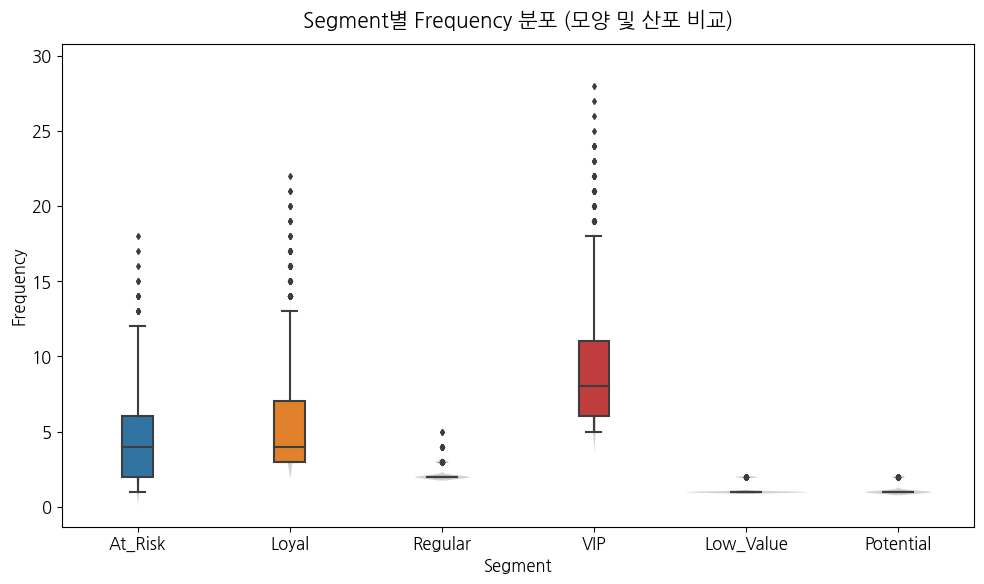

In [410]:
# 한글 폰트 및 마이너스 깨짐 방지 (필요시 주석 해제)
# plt.rcParams['font.family'] = 'AppleGothic'  # Mac
# plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(10, 6))

# 1. Frequency 바이올린 플롯 (분포 모양)
sns.violinplot(
    data=target_df, 
    x="segment", 
    y="frequency", 
    color="lightgray", 
    inner=None, 
    linewidth=0,
    alpha=0.6
)

# 2. Frequency 박스 플롯 (분산, 이상치 확인)
sns.boxplot(
    data=target_df, 
    x="segment", 
    y="frequency", 
    width=0.2, 
    boxprops={'zorder': 2}, 
    fliersize=3
)

plt.title("Segment별 Frequency 분포 (모양 및 산포 비교)", fontsize=15, pad=12)
plt.xlabel("Segment", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [411]:
p_val_freq = perform_kruskal_wallis(target_df, 'frequency')

========== [frequency] Kruskal-Wallis H-test ==========

H-statistic = 22991.0028, p-value = 0.0000e+00
-> p-value < 0.05 이므로, 적어도 한 세그먼트는 통계적으로 유의미한 순위(값) 차이를 보입니다.


- $H_0(귀무가설)$ 기각. 세그먼트 간 평균의 차이가 있음.

#### Dunn's Test

In [412]:
perform_dunn_posthoc(target_df, 'frequency', p_val=p_val_freq)


========== [frequency] Dunn's Post-hoc Test ==========

--- 1. 보정된 p-value 행렬 ---


,At_Risk,Low_Value,Loyal,Potential,Regular,VIP
At_Risk,1.0,0.0,0.0,0.0,0.0,0.0
Low_Value,0.0,1.0,0.0,1.0,0.0,0.0
Loyal,0.0,0.0,1.0,0.0,0.0,0.0
Potential,0.0,1.0,0.0,1.0,0.0,0.0
Regular,0.0,0.0,0.0,0.0,1.0,0.0
VIP,0.0,0.0,0.0,0.0,0.0,1.0



--- 2. 유의미한 차이가 있는 쌍 (True = 통계적 차이 있음) ---


,At_Risk,Low_Value,Loyal,Potential,Regular,VIP
At_Risk,False,True,True,True,True,True
Low_Value,True,False,True,False,True,True
Loyal,True,True,False,True,True,True
Potential,True,False,True,False,True,True
Regular,True,True,True,True,False,True
VIP,True,True,True,True,True,False



* 해석 가이드:
  - 행렬의 값이 0.05보다 작은(True로 표시된) 쌍이 서로 통계적으로 유의미한 차이가 있는 세그먼트입니다.
  - 실제 누가 더 크고 작은지(방향성)는 각 그룹의 중앙값(Median)이나 원본 시각화(Boxplot 등)를 보고 판단해야 합니다.


- Potential - Low_Value를 제외한 모든 세그먼트 쌍에 대한 **$H_0(귀무가설)$ 기각**, 서로 다름.

### 1.2.4. Monetary: 세그먼트간 이질성 통계적 검증

#### 정규성 검정

**[Monetary 정규성 검정]**

$H_0$: 데이터가 완벽한 정규분포를 따른다.</br>
$H_1$: 데이터가 완벽한 정규분포를 따르지 않는다.

**[검정법]**
- Shapiro-Wilk Test / Anderson-Darling Test 사용
- Q-Q plot

In [413]:
def check_normality_assumptions(df: pd.DataFrame, target_col: str, segment_col: str = 'segment'):
    """
    Oneway ANOVA 수행 전, 정규성과 등분산성을 수치적으로 확인합니다.
    """
    print(f"==========  {target_col} 정규성 검정 (Shapiro-Wilk Test) ==========\n")
    
    # 그룹별 데이터 분리
    groups = {name: group[target_col].dropna().values for name, group in df.groupby(segment_col)}
    
    # 1. 정규성 검정 (Shapiro-Wilk) 및 왜도/첨도 확인
    print("1. 정규성 검정 (Shapiro-Wilk Test) 및 분포 형태")
    print("-" * 65)
    print(f"{'Segment':<15} | {'N':<6} | {'Skewness':<10} | {'Kurtosis':<10} | {'p-value (Shapiro)'}")
    print("-" * 65)
    
    for name, data in groups.items():
        n = len(data)
        skew = stats.skew(data)
        kurt = stats.kurtosis(data)
        
        # 샘플 수가 3 이상이어야 검정 가능 (Shapiro-Wilk는 보통 5000개 이상이면 매우 민감함)
        if n >= 3:
            # shapiro는 샘플 사이즈가 매우 클 때 경고를 발생시킬 수 있음
            stat, p_val = stats.shapiro(data)
            p_val_str = f"{p_val:.4e}"
        else:
            p_val_str = "N/A"
            
        print(f"{name:<15} | {n:<6} | {skew:>10.4f} | {kurt:>10.4f} | {p_val_str}")
    
    print("\n* 참고: N이 클 경우 Shapiro-Wilk의 p-value는 쉽게 0.05 미만이 됩니다.")
    print("  이때는 왜도(Skewness, 보통 -2 ~ +2)와 첨도(Kurtosis, 보통 -7 ~ +7) 수치로 정규성 근사를 실무적으로 허용합니다.\n")


In [414]:
check_normality_assumptions(target_df, 'monetary_log1p')

==========  monetary_log1p 정규성 검정 (Shapiro-Wilk Test) ==========

1. 정규성 검정 (Shapiro-Wilk Test) 및 분포 형태
-----------------------------------------------------------------
Segment         | N      | Skewness   | Kurtosis   | p-value (Shapiro)
-----------------------------------------------------------------
At_Risk         | 6161   |    -0.0514 |    -0.7404 | 1.2519e-23
Low_Value       | 11330  |    -0.8005 |     0.8314 | 0.0000e+00
Loyal           | 5236   |     0.3098 |    -0.7368 | 1.7437e-28
Potential       | 650    |     0.9190 |    -0.3252 | 1.1156e-22
Regular         | 1295   |    -0.5267 |     0.5029 | 2.1041e-12
VIP             | 4632   |     0.2284 |    -0.6437 | 3.1647e-21

* 참고: N이 클 경우 Shapiro-Wilk의 p-value는 쉽게 0.05 미만이 됩니다.
  이때는 왜도(Skewness, 보통 -2 ~ +2)와 첨도(Kurtosis, 보통 -7 ~ +7) 수치로 정규성 근사를 실무적으로 허용합니다.



- Shapiro-Wilk Test는 데이터의 수가 많으면 정규분포와 작은 차이가 있어도 p-value가 쉽게 0으로 떨어지는 경향이 있음.
    - 각 세그먼트의 데이터 수는 Loyal 2,195개, 나머지는 4,000-6,000개로 충분히 많음.
    - 왜도(Skewness, 보통 -2 ~ +2)와 첨도(Kurtosis, 보통 -7 ~ +7)가 매우 낮으므로, 분포가 왜곡되었다고 보기 어려움.
    - 각 세그먼트의 데이터 수가 충분히 크기 때문에, 중심극한정리(CLT)에 의해 표본 평균의 분포는 정규분포를 따를 것이며, ANOVA 검정은 "각 그룹에서 뽑은 평균(Mean)들의 분포가 정규분포인가?"를 보기 떄문에</br>
    `ANOVA 진행`.

In [415]:
def perform_anderson_darling(df: pd.DataFrame, target_col: str, segment_col: str = 'segment', alpha: float = 0.05):
    """
    각 세그먼트별로 Anderson-Darling 검정을 수행하여 정규성을 평가합니다.
    """
    print(f"========== [{target_col}] Anderson-Darling Normality Test ==========\n")
    
    # 5% 유의수준에서의 인덱스 (리턴되는 signficance_levels 리스트에서 5%는 보통 3번째 인덱스(2)에 해당)
    # stats.anderson() returns: 
    # signficance_levels = [15. , 10. ,  5. ,  2.5,  1. ]
    alpha_to_idx = {
        0.15: 0,
        0.10: 1,
        0.05: 2,
        0.025: 3,
        0.01: 4
    }
    
    if alpha not in alpha_to_idx:
        raise ValueError(f"지원하지 않는 alpha 값입니다. 허용값: {list(alpha_to_idx.keys())}")
    else:
        sig_idx = alpha_to_idx[alpha]
        
    target_alpha = alpha * 100  # 0.05 → 5%
    
    # 출력 포맷 맞추기
    print(f"{'Segment':<15} | {'N':<6} | {'A-D Stat':<10} | {f'Crit Value({int(target_alpha)}%)':<14} | {f'Normality (at {int(target_alpha)}%)'}")
    print("-" * 75)
    
    # 그룹별로 분리하여 검정
    for name, group in df.groupby(segment_col):
        data = group[target_col].dropna().values
        n = len(data)
        
        # 샘플이 최소 4개 이상이어야 검정이 안정적임 (내부적으로 요구)
        if n > 3:
            # 앤더슨 달링 검정 수행 (기본 분포는 'norm')
            result = stats.anderson(data, dist='norm')
            
            ad_stat = result.statistic
            crit_val = result.critical_values[sig_idx]
            
            # 통계량이 임계값보다 크면 귀무가설(정규분포이다) 기각
            if ad_stat < crit_val:
                normality = "Pass (Normal)"
            else:
                normality = "Fail (Non-Normal)"
                
            print(f"{name:<15} | {n:<6} | {ad_stat:>10.4f} | {crit_val:>14.4f} | {normality}")
        else:
            print(f"{name:<15} | {n:<6} | {'N/A':>10} | {'N/A':>14} | 샘플 부족")

    print("\n* 해석 가이드:")
    print(f"  - A-D Stat(통계량) < Crit Value(임계값) : 지정한 유의수준({alpha})에서 정규분포를 따른다고 볼 수 있습니다.")
    print("  - 데이터(N)가 클 경우, A-D 검정 역시 미세한 이탈에 의해 'Fail'이 뜰 확률이 매우 높습니다.")

In [416]:
perform_anderson_darling(df=target_df, target_col='monetary_log1p', segment_col='segment', alpha=0.05)

========== [monetary_log1p] Anderson-Darling Normality Test ==========

Segment         | N      | A-D Stat   | Crit Value(5%) | Normality (at 5%)
---------------------------------------------------------------------------
At_Risk         | 6161   |    24.9753 |         0.7860 | Fail (Non-Normal)
Low_Value       | 11330  |    87.9492 |         0.7870 | Fail (Non-Normal)
Loyal           | 5236   |    32.5749 |         0.7860 | Fail (Non-Normal)
Potential       | 650    |    31.0473 |         0.7820 | Fail (Non-Normal)
Regular         | 1295   |     3.0645 |         0.7850 | Fail (Non-Normal)
VIP             | 4632   |    14.5686 |         0.7860 | Fail (Non-Normal)

* 해석 가이드:
  - A-D Stat(통계량) < Crit Value(임계값) : 지정한 유의수준(0.05)에서 정규분포를 따른다고 볼 수 있습니다.
  - 데이터(N)가 클 경우, A-D 검정 역시 미세한 이탈에 의해 'Fail'이 뜰 확률이 매우 높습니다.


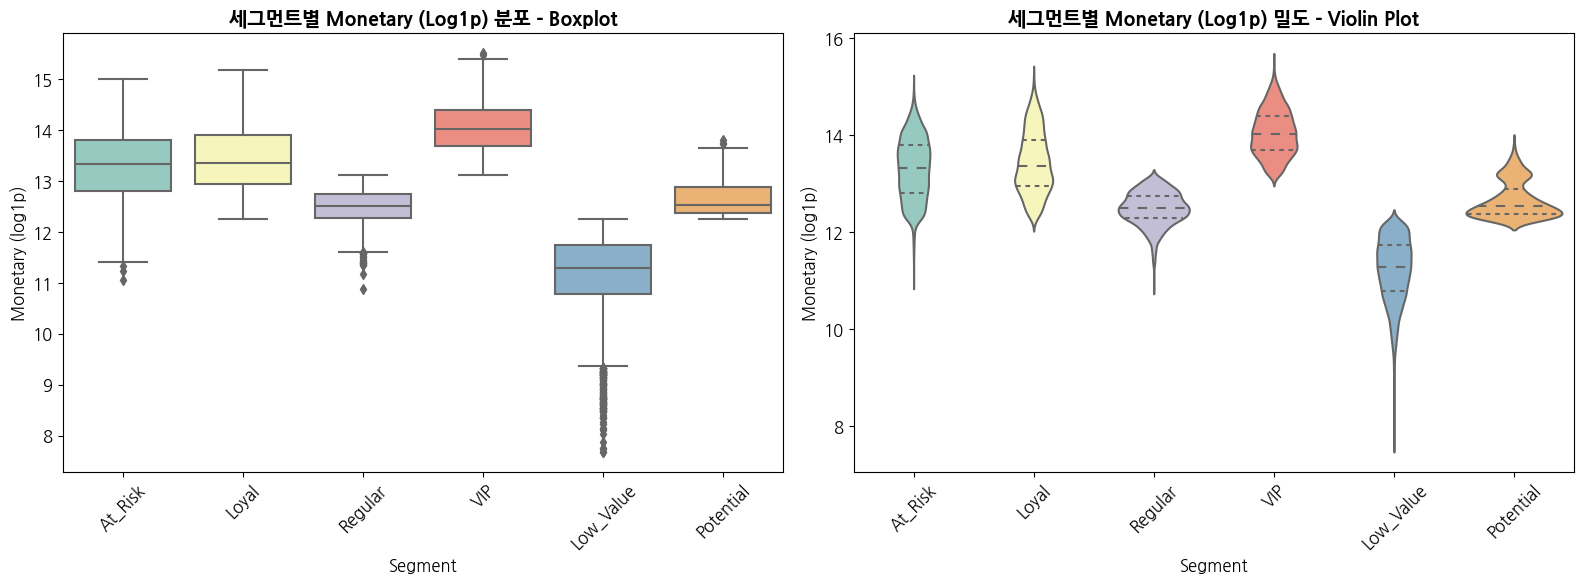

In [417]:
# 시각화할 세그먼트 순서와 색상 설정 (기존에 사용하던 Set3 유지)
plot_segments = target_df['segment'].unique()
palette_dict = dict(zip(plot_segments, sns.color_palette("Set3", n_colors=len(plot_segments))))

# 1행 2열 서브플롯 설정
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- 1. Boxplot (중앙값, 사분위수, 이상치 확인) ---
sns.boxplot(
    data=target_df,
    x="segment",
    y="monetary_log1p",
    order=plot_segments,
    palette=palette_dict,
    ax=axes[0]
)
axes[0].set_title("세그먼트별 Monetary (Log1p) 분포 - Boxplot", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Segment", fontsize=12)
axes[0].set_ylabel("Monetary (log1p)", fontsize=12)
axes[0].tick_params(axis="x", rotation=45)

# --- 2. Violin Plot (분포의 형태와 밀도 확인) ---
sns.violinplot(
    data=target_df,
    x="segment",
    y="monetary_log1p",
    order=plot_segments,
    palette=palette_dict,
    ax=axes[1],
    inner="quartile" # 바이올린 내부에 사분위수 점선 표시
)
axes[1].set_title("세그먼트별 Monetary (Log1p) 밀도 - Violin Plot", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Segment", fontsize=12)
axes[1].set_ylabel("Monetary (log1p)", fontsize=12)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

- Anderson-darling Test의 통계량이 매우 큰 것은 각 세그먼트에 존재하는 이상치(분포의 꼬리)에 영향을 받았을 것.

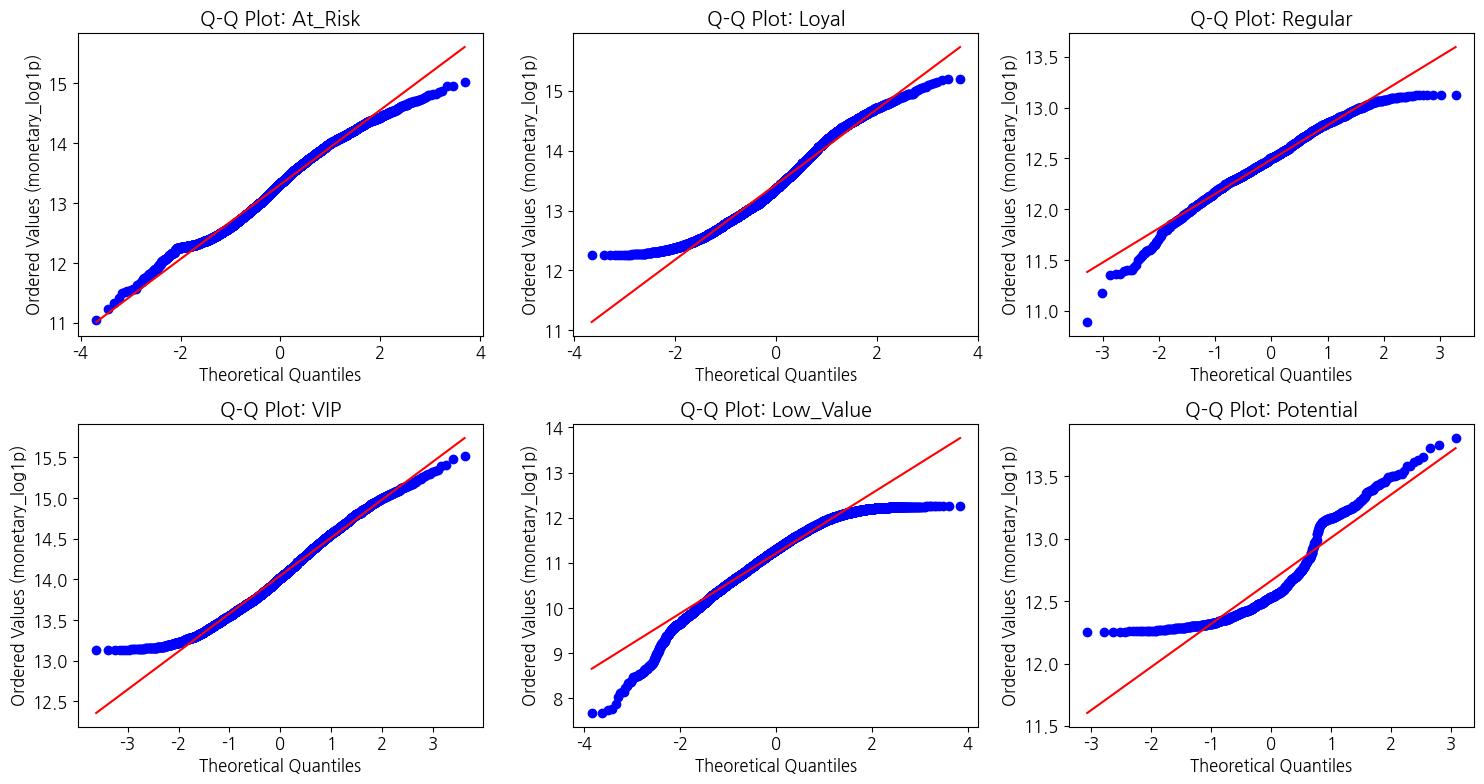

In [418]:
# Dormant가 제외되고 monetary_log1p가 계산된 데이터프레임: target_df 라고 가정
segments = target_df['segment'].unique()

# 서브플롯 행, 열 개수 계산 (예: 6개 세그먼트면 2행 3열)
n_cols = 3
n_rows = math.ceil(len(segments) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
# axes가 1차원 배열이 되도록 평탄화(flatten)
axes = axes.flatten()

for i, seg in enumerate(segments):
    # 각 세그먼트별 monetary_log1p 데이터 추출 (결측치 제외)
    data = target_df[target_df['segment'] == seg]['monetary_log1p'].dropna()
    
    # Q-Q Plot 그리기
    # stats.probplot 함수가 자동으로 해당 축(ax)에 점과 기준선(line='s')을 그려줍니다.
    stats.probplot(data, dist="norm", plot=axes[i])
    
    axes[i].set_title(f"Q-Q Plot: {seg}")
    axes[i].set_xlabel("Theoretical Quantiles")
    axes[i].set_ylabel("Ordered Values (monetary_log1p)")

# 만약 세그먼트 개수가 axes 칸 수보다 적어서 빈 축이 남으면 지워줌
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

- Low_Value와 Potential을 제외하고, Q-Q plot이 꼬리 부분을 제외하고 크게 벗어나지 않음. 중앙 몸통 부분이 선을 잘 따라가고 있기 때문에 선형성을 확보했음.

#### 등분산성 검정
- Levene's Test

In [419]:
def check_equal_variance_assumptions(df: pd.DataFrame, target_col: str, segment_col: str = 'segment'):
    """
    등분산성 검정을 수행하여 등분산성 가정을 평가합니다.
    """
    print(f"========== {target_col} 등분산성 검정 (Levene's Test) ==========\n")

    # 그룹별 데이터 분리
    groups = {name: group[target_col].dropna().values for name, group in df.groupby(segment_col)}

    # 딕셔너리의 value들(배열 리스트)을 언패킹하여 전달
    stat, p_val = stats.levene(*groups.values())
    print(f"Levene-statistic = {stat:.4f}, p-value = {p_val:.4e}")
    
    if p_val < 0.05:
        print("-> p-value < 0.05 이므로 등분산성 가정을 만족하지 않습니다. (Welch's ANOVA 고려 필요)")
    else:
        print("-> p-value >= 0.05 이므로 등분산성 가정을 만족합니다. (일반 Oneway ANOVA 사용 가능)")

In [420]:
check_equal_variance_assumptions(df=target_df, target_col='monetary_log1p', segment_col='segment')

========== monetary_log1p 등분산성 검정 (Levene's Test) ==========

Levene-statistic = 278.3155, p-value = 7.7714e-292
-> p-value < 0.05 이므로 등분산성 가정을 만족하지 않습니다. (Welch's ANOVA 고려 필요)


- 등분산성 검정에 실패했기 때문에 원래 계획했던 One-way ANOVA를 진행하지 않고, `Welch's ANOVA 진행`.

##### 퍼뮤테이션 검정(등분산 가정 하에서 p-value 재추정)

Levene 통계량을 관측값으로 두고, 세그먼트 라벨을 섞었을 때(= 분산 차이가 “라벨” 때문이 아니라면) 그 Levene 통계량이 이 정도로 크게 나올 확률을 계산합니다.

퍼뮤테이션은 그 `결론이 라벨 셔플 하에서도 유지되는지(우연성 배제)` “현재 관측된 분산 이질성이 우연인지”를 더 견고하게 확인합니다.

In [421]:
def permutation_test_levene(
    df: pd.DataFrame,
    target_col: str,
    segment_col: str = "segment",
    n_perm: int = 5000,
    random_state: int = 42,
    center: str = "median",   # Levene 기본(center='median')과 맞춤
):
    """
    퍼뮤테이션 기반 Levene 검정:
    - H0: segment 라벨과 target 분산 구조가 무관(라벨만 섞어도 비슷해야 함)
    - p_perm = 관측 Levene 통계량보다 크거나 같은 통계량이 나온 비율
    """
    data = df[[target_col, segment_col]].dropna().copy()
    if data.empty:
        raise ValueError("유효한 데이터가 없습니다. target_col 또는 segment_col의 결측을 확인하세요.")

    labels = data[segment_col].to_numpy()
    x_all = data[target_col].to_numpy()

    unique_segments = pd.unique(data[segment_col])
    # 관측 Levene 통계량
    groups_obs = [data.loc[data[segment_col] == seg, target_col].to_numpy() for seg in unique_segments]
    stat_obs, _ = stats.levene(*groups_obs, center=center)

    rng = np.random.default_rng(random_state)
    stat_perm = np.empty(n_perm, dtype=float)

    for i in range(n_perm):
        perm_labels = rng.permutation(labels)

        # 퍼뮤트된 라벨로 그룹 재구성(그룹 크기는 유지됨)
        groups = []
        for seg in unique_segments:
            mask = perm_labels == seg
            groups.append(x_all[mask])

        # 그룹 크기가 너무 작으면(예: 1개) Levene가 불안정할 수 있어 방어
        if any(len(g) < 2 for g in groups):
            stat_perm[i] = np.nan
            continue

        stat_perm[i], _ = stats.levene(*groups, center=center)

    # nan 제외하고 p-value 계산
    stat_perm_valid = stat_perm[~np.isnan(stat_perm)]
    p_perm = (np.sum(stat_perm_valid >= stat_obs) + 1) / (len(stat_perm_valid) + 1)

    print(f"========== Permutation Levene ({n_perm}회) ==========")
    print(f"Observed Levene statistic = {stat_obs:.6f}")
    print(f"Permutation p-value      = {p_perm:.6g}")
    return stat_obs, p_perm

In [422]:
stat_obs, p_perm = permutation_test_levene(
    df=target_df,
    target_col="monetary_log1p",
    segment_col="segment",
    n_perm=5000,
    random_state=42
)

========== Permutation Levene (5000회) ==========
Observed Levene statistic = 278.315498
Permutation p-value      = 0.00019996


##### 부트스트랩 (분산 이질성의 안정성/불확실성)

부트스트랩은 “H0 하 p-value”보다는, 세그먼트별 분산 차이가 샘플링에 의해 쉽게 뒤집히는지 확인하는 게 자연스럽습니다.

여기서는 가장 직관적인 지표인 max(var) / min(var)의 부트스트랩 분포를 만듭니다.

분산 이질성이 `샘플링에 따라 크게 흔들리지 않는지(안정성/강건성)`

1. 각 세그먼트 안에서만 관측치를 복원추출로 다시 뽑습니다(세그먼트별 크기는 유지).
2. 그 재표본에서 각 세그먼트의 분산을 다시 구하고 max(var)/min(var)을 다시 계산합니다.
3. 이 과정을 B=3000번 반복하면, max(var)/min(var) 값들의 **분포(가능한 비율의 범위)**가 생깁니다.
4. 그 분포에서 **95% 구간(2.5%~97.5%)**을 뽑아 CI를 만듭니다.

즉, 이 CI는 “분산 이질성 비율이 샘플링 변동에도 어느 정도 유지되는가”를 보여주는 지표예요.

(Levene의 p-value처럼 ‘가정 하 H0 확률’이 아니라, ‘비율의 신뢰구간’ 성격입니다.)

In [423]:
def bootstrap_variance_ratio(
    df: pd.DataFrame,
    target_col: str,
    segment_col: str = "segment",
    B: int = 3000,
    random_state: int = 42,
    ddof: int = 1,  # 표본분산
):
    """
    세그먼트별 target_col 분산의 부트스트랩 분포를 만들고
    max(var)/min(var)의 신뢰구간을 산출해 '분산 이질성의 크기'가 안정적인지 확인.
    """
    data = df[[target_col, segment_col]].dropna().copy()
    groups = {seg: data.loc[data[segment_col] == seg, target_col].to_numpy()
              for seg in pd.unique(data[segment_col])}

    # 너무 작은 그룹은 제외/방어
    groups = {k: v for k, v in groups.items() if len(v) >= 2}
    if len(groups) < 2:
        raise ValueError("분산 비교가 가능한 세그먼트가 2개 이상 필요하며, 각 세그먼트의 표본 크기도 2 이상이어야 합니다.")

    rng = np.random.default_rng(random_state)
    seg_keys = list(groups.keys())
    ratio = np.empty(B, dtype=float)

    for b in range(B):
        variances = []
        for seg in seg_keys:
            x = groups[seg]
            x_star = rng.choice(x, size=len(x), replace=True)
            variances.append(np.var(x_star, ddof=ddof))

        v_min = np.min(variances)
        v_max = np.max(variances)
        ratio[b] = np.inf if v_min == 0 else (v_max / v_min)

    ci_low, ci_high = np.percentile(ratio, [2.5, 97.5])
    print(f"========== Bootstrap Variance Ratio (B={B}) ==========")
    print(f"max(var)/min(var) 95% CI = [{ci_low:.6g}, {ci_high:.6g}]")
    return ratio, (ci_low, ci_high)

In [424]:
ratio, (ci_low, ci_high) = bootstrap_variance_ratio(
    df=target_df,
    target_col="monetary_log1p",
    segment_col="segment",
    B=3000
)

========== Bootstrap Variance Ratio (B=3000) ==========
max(var)/min(var) 95% CI = [3.63805, 4.37238]


분산이 가장 큰 세그먼트의 분산은 가장 작은 세그먼트의 분산보다 대략 `3.63배에서 4.37배 사이일 가능성이 95%`

따라서 “등분산(비율=1)에 가까운 상황”은 부트스트랩 기준으로 거의 나타나지 않는다고 해석할 수 있고,

“세그먼트 간 분산이 다르다(이질성이 크다)”는 방향의 결론을 강하게 지지함.

#### 세그먼트간 이질성 검정

##### Welch's ANOVA

- Welch's ANOVA는 MSE(Mean Square Error, 평균 제곱 오차, 합동 분산이라고도 함.)를 사용하지 않고, 각 그룹의 분산과 샘플 수를 개별적으로 가중치로 적용하여 식 보정.
    - 일반 ANOVA의 F값: $F = \frac{\text{통합된 그룹 간 차이}}{\text{통합된 평균 오차}}$
    - Welch's F값: $W = \frac{\text{그룹 간 차이}}{\text{각 그룹의 고유 분산과 N을 반영한 가중 오차}}$

**분산이 큰 그룹 때문에 발생하는 1종 오류(차이가 없는데 있다고 하는 오류)를 막아주어, 이분산 상황에서도 Robust p-value 반환.**

- 귀무가설(H0): 모든 세그먼트의 Monetary의 평균값은 같다.
- 대립가설(H1): 적어도 한 세그먼트의 Monetary의 평균값은 다르다.

In [425]:
def perform_welchs_anova(df: pd.DataFrame, target_col: str, segment_col: str = 'segment') -> float:
    """
    등분산성 가정을 위반했을 때 사용하는 Welch's ANOVA를 수행합니다.
    """
    print(f"========== {target_col} Welch's ANOVA ==========\n")
    
    # 결측치 제거 후 ANOVA 수행 (pingouin.welch_anova 사용)
    # dv: 종속변수 (target_col), between: 독립변수/그룹 (segment_col)
    clean_df = df[[target_col, segment_col]].dropna()
    welch_res = pg.welch_anova(data=clean_df, dv=target_col, between=segment_col)
    
    # 결과 출력
    display(welch_res)
    
    # p-value 추출
    p_val = welch_res['p-unc'].values[0]
    
    if p_val < 0.05:
        print(f"\n-> p-value({p_val:.4e}) < 0.05 이므로 세그먼트 간 평균에 유의미한 차이가 있습니다.")
    else:
        print(f"\n-> p-value({p_val:.4f}) >= 0.05 이므로 세그먼트 간 유의미한 차이가 없습니다.")
        
    return p_val

In [426]:
p_val_welch = perform_welchs_anova(target_df, 'monetary_log1p')

========== monetary_log1p Welch's ANOVA ==========



,Source,ddof1,ddof2,F,p-unc,np2
0,segment,5,4862.183096,21005.65467,0.0,0.776886



-> p-value(0.0000e+00) < 0.05 이므로 세그먼트 간 평균에 유의미한 차이가 있습니다.


- 결과 데이터프레임의 p-unc (Uncorrected p-value)가 기존 p_val과 동일.
- $H_0(귀무가설)$ 기각. 세그먼트 간 평균의 차이가 있음.

##### Games-Howell Test(사후 검정)

- Tukey HSD는 "모든 세그먼트가 똑같이 퍼져 있다(등분산성)" 가정, MSE 사용.
    - $q(통계량) = \frac{|\bar{X}_A - \bar{X}_B|}{\sqrt{\frac{MSE}{2} (\frac{1}{n_A} + \frac{1}{n_B})}}$
    - 예를 들어, VIP의 평균이 15(만원), 분산이 200이고, Low_Value 의 평균이 13, 분산이 10,000일때 MSE는 8,000이 됨.
    
- Games-Howell Test는 비교하는 두 그룹의 분산을 더함. (자유도 또한 전체 N-k를 사용하지 않고, Welch-Satterthwaite를 사용하여 두 그룹의 분산 비율에 맞게 설정.)
    - $t(통계량) = \frac{|\bar{X}_A - \bar{X}_B|}{\sqrt{\frac{s_A^2}{n_A} + \frac{s_B^2}{n_B}}}$
    - 위와 같은 예시에서, 분모 오차항=$\sqrt{(200 / 1000) + (10000 / 5000)} = \sqrt{0.2 + 2} = \sqrt{2.2} \approx 1.48$
    - $t=(15 - 13) / 1.48 = 1.35$

**따라서, Games-Howell Test 사용**

In [427]:
def perform_games_howell_posthoc(df: pd.DataFrame, target_col: str, segment_col: str = 'segment', p_val: float = None, alpha: float = 0.05):
    """
    Welch's ANOVA 결과가 유의미할 때 수행하는 사후 검정(Games-Howell Test) 함수입니다.
    """
    print(f"\n========== [{target_col}] Games-Howell Post-hoc Test ==========\n")
    
    # 1. p_val이 넘어오지 않았다면 내부적으로 Welch's ANOVA 한번 실행
    if p_val is None:
        clean_df = df[[target_col, segment_col]].dropna()
        welch_res = pg.welch_anova(data=clean_df, dv=target_col, between=segment_col)
        p_val = welch_res['p-unc'].values[0]
        
    # 2. ANOVA에서 차이가 없었다면 사후 검정 종료
    if p_val >= alpha:
        print(f"ANOVA p-value({p_val:.4f})가 {alpha} 이상이므로 사후 검정을 수행하지 않습니다.")
        return
    
    # 3. Games-Howell 사후 검정 수행
    clean_df = df[[target_col, segment_col]].dropna()
    posthoc_res = pg.pairwise_gameshowell(data=clean_df, dv=target_col, between=segment_col)
    
    # 가독성을 위해 불리언 판정 컬럼 추가
    posthoc_res['reject'] = posthoc_res['pval'] < alpha
    
    # 핵심 컬럼만 추려서 보기 좋게 출력
    columns_to_show = ['A', 'B', 'mean(A)', 'mean(B)', 'diff', 'se', 'T', 'df', 'pval', 'reject']
    display(posthoc_res[columns_to_show].round(4))
    
    print("\n* 해석 가이드:")
    print("  - diff: A그룹 평균 - B그룹 평균 (양수면 A가 더 큼)")
    print("  - reject가 True인 행이 통계적으로 두 그룹 간에 유의미한 평균 차이가 있는 짝입니다.")

In [428]:
perform_games_howell_posthoc(target_df, 'monetary_log1p', p_val=p_val_welch)


========== [monetary_log1p] Games-Howell Post-hoc Test ==========



,A,B,mean(A),mean(B),diff,se,T,df,pval,reject
0,At_Risk,Low_Value,13.3104,11.2093,2.1012,0.0102,205.7275,13562.2838,0.0,True
1,At_Risk,Loyal,13.3104,13.4336,-0.1232,0.0119,-10.3875,11044.1666,0.0,True
2,At_Risk,Potential,13.3104,12.6653,0.6451,0.0165,39.0774,1093.0989,0.0,True
3,At_Risk,Regular,13.3104,12.4896,0.8208,0.0124,66.3037,3416.6501,0.0,True
4,At_Risk,VIP,13.3104,14.0473,-0.7369,0.0106,-69.8310,10790.9992,0.0,True
5,Low_Value,Loyal,11.2093,13.4336,-2.2244,0.0109,-204.8714,10832.7065,0.0,True
6,Low_Value,Potential,11.2093,12.6653,-1.4561,0.0158,-92.1372,924.8470,0.0,True
7,Low_Value,Regular,11.2093,12.4896,-1.2803,0.0114,-112.0918,2674.0243,0.0,True
8,Low_Value,VIP,11.2093,14.0473,-2.8380,0.0094,-301.5733,12253.7272,0.0,True
9,Loyal,Potential,13.4336,12.6653,0.7683,0.0169,45.4232,1196.2094,0.0,True



* 해석 가이드:
  - diff: A그룹 평균 - B그룹 평균 (양수면 A가 더 큼)
  - reject가 True인 행이 통계적으로 두 그룹 간에 유의미한 평균 차이가 있는 짝입니다.


- - $H_0(귀무가설)$ 기각. 각 세그먼트의 $log(1+x)$ 변환한 Monetary 분포의 평균은 모두 서로 다름.

---

### 1.2.5. 시각적 검증: Snake Plot

각 세그먼트별 RFM 특성을 한눈에 파악하기 위해 데이터를 표준화한 후 시각화.

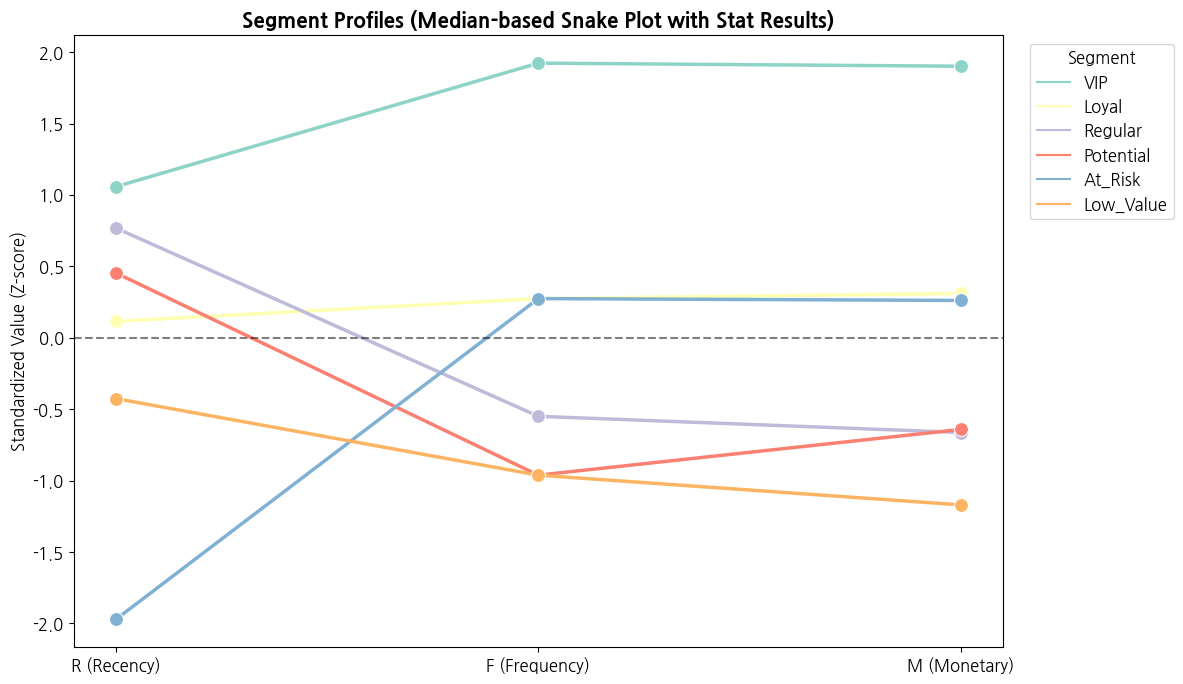

In [429]:
# 1. RFM '중앙값(Median)' 계산 (비모수 검정 결과와 논리적 일관성 유지)
# M의 경우 정규분포에 가까워 평균을 썼지만, 중앙값을 써도 무방하며 통일성을 위해 median 적용
out = target_df.copy() # 대상 데이터프레임 (Dormant 제외 권장)
segment_analysis = out.groupby('segment').agg({
    'recency_days': 'median',
    'frequency': 'median',
    'monetary': 'median'
}).reset_index()

segment_analysis['recency_days'] = segment_analysis['recency_days'] * -1

# 2. 데이터 표준화 (StandardScaler)
scaler = StandardScaler()
norm_data = scaler.fit_transform(segment_analysis[['recency_days', 'frequency', 'monetary']])
norm_df = pd.DataFrame(norm_data, columns=['R (Recency)', 'F (Frequency)', 'M (Monetary)'])
norm_df['segment'] = segment_analysis['segment']

# 3. 데이터 Melt (Long format)
melted_df = pd.melt(norm_df, id_vars='segment', var_name='Metric', value_name='Standardized_Value')

# 4. Snake Plot 시각화
plt.figure(figsize=(12, 7))

# Set3 팔레트 매핑 (일관성 유지)
segments_ordered = ["VIP", "Loyal", "Regular", "Potential", "At_Risk", "Low_Value"]
colors = sns.color_palette("Set3", n_colors=7)
palette_dict = {seg: colors[i] for i, seg in enumerate(segments_ordered)}

sns.lineplot(
    data=melted_df, 
    x='Metric', 
    y='Standardized_Value', 
    hue='segment', 
    hue_order=segments_ordered,
    marker='o', 
    linewidth=2.5,
    markersize=10,
    palette=palette_dict
)

# 5. 통계 검정 결과(귀무가설 채택 = 통계적 차이 없음) 주석 달기
# 차트의 배경 빈 공간(주로 상단이나 하단)에 텍스트 박스 삽입
# tie_text = (
#     "[Statistical Test Results (Non-Significant Pairs)]\n\n"
#     "• Recency (Kruskal-Wallis): \n"
#     "   Loyal ≒ New ≒ Regular  (No diff)\n\n"
#     "• Frequency (Kruskal-Wallis): \n"
#     "   Low_Value ≒ New  (No diff)\n\n"
#     "• Monetary (Welch's ANOVA): \n"
#     "   All segments are distinct (p < 0.05)"
# )

# # 텍스트 박스 추가 (좌측 상단 여백 활용, 좌표는 데이터 값에 따라 미세 조정 필요)
# plt.text(
#     x=-0.2, 
#     y=melted_df['Standardized_Value'].max() * 0.8, 
#     s=tie_text, 
#     fontsize=11, 
#     bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', boxstyle='round,pad=0.5')
# )

# 축 및 타이틀 정리
plt.title('Segment Profiles (Median-based Snake Plot with Stat Results)', fontsize=15, fontweight='bold')
plt.ylabel('Standardized Value (Z-score)', fontsize=12)
plt.xlabel('')
plt.axhline(0, color='black', linestyle='--', alpha=0.5) # 평균 기준선(0)
plt.legend(title='Segment', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

- Potential과 Low_Value는 Frequency 분포에서 통계적 평균(순위)의 차이가 없었지만, Recency와 Monetary에서 큰 차이를 보임.
- Potential과 Loyal은 Recency 분포에서 통계적 평균(순위)의 차이가 없었지만, Frequency와 Monetary에서 큰 차이를 보임.

# 2. 월별 RFM 스냅샷 데이터 마트 정의

04 노트북(전이·이탈 경로)과 05 노트북(CRM·A/B 테스트)이 이 스냅샷을 입력으로 사용합니다.

In [434]:
def monthly_rfm_snapshots(
    users_df: pd.DataFrame,
    orders_enriched_df: pd.DataFrame,
    start_month: str = "2022-01",
    end_month: str = "2024-12",
    lookback_days: int = 365,
    statuses: set | None = None,
) -> pd.DataFrame:
    """
    월말(as_of_date) 기준으로 최근 lookback_days(기본 365일) 구매를 사용해 RFM을 산출하고,
    5분위 스코어링 + 세그먼트 라벨링까지 완료한 스냅샷을 long 포맷으로 반환.

    반환 컬럼(핵심):
      - snapshot_month (YYYY-MM)
      - user_id
      - recency_days, frequency, monetary
      - R_score, F_score, M_score
      - segment
    """

    o = orders_enriched_df.copy()
    o["created_at"] = pd.to_datetime(o["created_at"], errors="coerce")
    o = o.dropna(subset=["created_at", "user_id", "id"])

    # 스냅샷 월말 리스트 생성
    months = pd.period_range(start=start_month, end=end_month, freq="M")

    snapshots = []
    for p in months:
        as_of_date = p.to_timestamp(how="end").strftime("%Y-%m-%d")
        rfm_full = compute_rfm_purchase(
            users_df=users_df,
            orders_enriched_df=o,
            as_of_date=as_of_date,
            lookback_days=lookback_days,
            statuses=statuses,
        )

        rfm_full["snapshot_month"] = p.strftime("%Y-%m")
        rfm_full["days_since_signup"] = (pd.to_datetime(as_of_date) - rfm_full["created_at"]).dt.days  # 가입 후 경과일

        scored = rfm_quintile_scoring(rfm_full, lookback_days=lookback_days)
        labeled = label_rfm_segments(scored)

        snapshots.append(
            labeled[[
                "snapshot_month", "user_id", "days_since_signup", "age", "gender", "traffic_source",
                "last_order_dt", "recency_days", "frequency", "monetary",
                "R_score", "F_score", "M_score",
                "RFM_score", "RFM_sum",
                "segment"
            ]]
        )

    return pd.concat(snapshots, ignore_index=True)
    

In [435]:
snapshots_df = monthly_rfm_snapshots(
    users_df=users_df,
    orders_enriched_df=orders_enriched,
    start_month="2023-01",
    end_month="2024-12",
    lookback_days=365,
)
snapshots_df.head()

,snapshot_month,user_id,days_since_signup,age,gender,traffic_source,last_order_dt,recency_days,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_sum,segment
0,2023-01,7,247,30,M,email,2023-01-16 09:17:42,15,15,2636270.0,5,5,5,555,15,VIP
1,2023-01,13,851,27,F,paid_search,2022-02-23 00:52:56,342,1,298400.0,1,1,3,113,5,At_Risk
2,2023-01,15,40,25,M,instagram,NaT,1364,0,0.0,0,0,0,000,0,Dormant
3,2023-01,18,287,24,M,instagram,NaT,1364,0,0.0,0,0,0,000,0,Dormant
4,2023-01,24,331,31,M,organic_search,2022-10-20 19:05:30,103,1,83340.0,3,1,2,312,6,Low_Value


In [436]:
snapshots_df.to_parquet(os.path.join(data_path, "snapshots_df.parquet"), index=False, engine='pyarrow', compression='snappy')